## Bunch dependence and detected-electron history
Consolidated from `Bunch_dependence_clean.ipynb` (the source confirmed for this task). Analyse the selected 275.0 eV combined H5 through its aggregate metadata, using the existing calibration, KE regions and five-fold train-wise CV. Source notebooks and raw data remain unchanged.

Reference response is 190–220 eV; independent target response is 220–260 eV. Detector history always uses **all detected electrons**. Ratios use sums of observed counts divided by sums of the appropriate normalisation, never averages of per-shot ratios. One bunch is one shot; histories reset at every train and exclude the current shot.

Full-data execution was completed on the Maxwell display node at the user's explicit request, with numerical libraries limited to one CPU thread. All saved outputs are from this corrected notebook using all 35,439 trains; the source notebook and raw data were not modified.

## 1. Setup and data loading
Which shots and electron regions are being analysed? The setup preserves the source paths, calibration, GMD/bunch cuts and CV row-index convention. Loading reads bounded TOF chunks and retains compact train × bunch arrays. There are no plots here; real train metadata is retained without introducing a new filtering rule. `common` remains the population for the original previous-GMD comparison; `current_mask` selects current shots for the later detector-history tests.

In [1]:
# Existing environment, paths, calibration and plotting style.
import os
import sys
import json
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display

os.environ.setdefault("FLASH_ENV", "remote")
repo_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                  if (p / "analysis" / "scripts").exists()), None)
if repo_root is None:
    raise RuntimeError("Open this notebook from within the glycine26 repository.")
scripts_dir = repo_root / "analysis" / "scripts"
if str(scripts_dir) not in sys.path:
    sys.path.insert(0, str(scripts_dir))
import config
AGG_DIR = Path(config.COMBINED_DIR)
CALIB_PATH = AGG_DIR.parent / "Calibrations" / "etof_energy_calibration_t0_scan.json"
with open(CALIB_PATH, "r", encoding="utf-8") as handle:
    calib = json.load(handle)
best_t0 = calib["t0_tof_units"]
best_slope = calib["slope_eV_tof_unit2"]
best_E0 = calib["E0_eV"]

AGG_FILENAMES = [

    "glycine_delay_scan_150C_long_271.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_long_271.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_long_272.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_272.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_273.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_273.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_274.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_275.0eV_aggregates_tr_etof1.h5",   ]


ANALYSIS_PHOTON_ENERGY_EV = 275.0
INDEP_REF_KE_RANGE = BUNCH_REF_KE_RANGE = (190.0, 220.0)
INDEP_TARGET_KE_RANGE = (220.0, 260.0)
INDEP_GMD_RANGE = (1.0, 12.0)
INDEP_GMD_BANDS = LAG_GMD_BANDS = [
    (1.0, 2.0), (3.0, 4.0), (5.0, 6.0), (6.0, 8.0), (8.0, 12.0)]
INDEP_BUNCH_START = COMPARE_BUNCH_START = 10
INDEP_CV_MOD = 5
INDEP_CV_OFFSETS = np.arange(INDEP_CV_MOD)
INDEP_CHUNK_TRAINS = 250
INDEP_MODELS = ["M0", "M5", "M10", "E2", "E3"]
MAX_TRAINS = None  # e.g. 2000 for a preview; tiny subsets may lack Cb reference counts.
ELECTRON_TAU_INITIAL = 3.0
ELECTRON_TAU_BOUNDS = (0.25, 50.0)  # Explicit numerical fit bounds, in bunch spacings.
plt.rcParams.update({"figure.dpi":110, "savefig.dpi":200, "font.size":14,
                     "axes.labelsize":16, "axes.titlesize":18,
                     "xtick.labelsize":14, "ytick.labelsize":14, "legend.fontsize":12})
print("Combined:", AGG_DIR)
print("Calibration:", CALIB_PATH)

Combined: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined
Calibration: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/Calibrations/etof_energy_calibration_t0_scan.json


In [2]:
# Existing helpers copied from Bunch investigations.ipynb.

def tof_to_ke(tof):
    tof = np.asarray(tof, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        ke = best_slope / (tof - best_t0) ** 2 + best_E0
    return np.where(tof > best_t0, ke, np.nan)

def load_aggregate_info(path):
    path = Path(path)
    with h5py.File(path, "r") as handle:
        metadata = {}
        for key in handle.attrs:
            value = handle.attrs[key]
            if isinstance(value, bytes):
                value = value.decode()
            elif isinstance(value, np.ndarray):
                value = value.tolist()
            metadata[key] = value

        info = {
            "path": path,
            "metadata": metadata,
            "tof_edges": handle["tof_edges"][:],
            "gmd_edges": handle["gmd_edges"][:],
            "n_per_bin": handle["n_per_bin"][:],
            "G": handle["G"][:],
            "D_shape": handle["D"].shape if "D" in handle else None,
            "z_edges": handle["z_edges"][:] if "z_edges" in handle else None,
        }

    return info

def electron_counts_ref_target(tofs_e):
    """
    Count electrons per shot in the independent Cb reference region
    and in the target region using one TOF -> KE conversion.
    """
    valid = tofs_e > 0
    shape = tofs_e.shape[:2]

    ref = np.zeros(shape, dtype=np.int32)
    target = np.zeros(shape, dtype=np.int32)

    if not np.any(valid):
        return ref, target

    ke = tof_to_ke(tofs_e[valid])
    flat_index = np.flatnonzero(valid) // tofs_e.shape[-1]

    in_ref = (ke >= INDEP_REF_KE_RANGE[0]) & (ke < INDEP_REF_KE_RANGE[1])
    in_target = (ke >= INDEP_TARGET_KE_RANGE[0]) & (ke < INDEP_TARGET_KE_RANGE[1])

    ref.flat[:] = np.bincount(flat_index[in_ref], minlength=np.prod(shape))
    target.flat[:] = np.bincount(flat_index[in_target], minlength=np.prod(shape))

    return ref, target

def preceding_gmd_mean(gmd, width):
    n_trains, n_bunch = gmd.shape
    out = np.full_like(gmd, np.nan, dtype=float)
    g0 = np.nan_to_num(gmd, nan=0.0)
    cs = np.concatenate((np.zeros((n_trains, 1)), np.cumsum(g0, axis=1)), axis=1)
    fc = np.concatenate((np.zeros((n_trains, 1), dtype=int), np.cumsum(np.isfinite(gmd), axis=1)), axis=1)
    sums = cs[:, width:n_bunch] - cs[:, :n_bunch-width]
    good = fc[:, width:n_bunch] - fc[:, :n_bunch-width]
    out[:, width:] = sums / width
    out[:, width:][good != width] = np.nan
    return out

def build_compare_cb(sum_e, sum_gmd, sum_shots, bunch_start=COMPARE_BUNCH_START):
    """
    Learn Cb from training data only.

    For every bunch position:
      1. electron/GMD response is formed within each GMD band,
      2. each band is normalised by its mean response,
      3. the relative responses are combined using shot-count weights.
    """
    response = np.divide(sum_e, sum_gmd, out=np.full_like(sum_e, np.nan, dtype=float), where=sum_gmd > 0)

    band_mean = np.divide(
        np.sum(sum_e[:, bunch_start:], axis=1),
        np.sum(sum_gmd[:, bunch_start:], axis=1),
        out=np.full(sum_e.shape[0], np.nan, dtype=float),
        where=np.sum(sum_gmd[:, bunch_start:], axis=1) > 0,
    )

    relative = response / band_mean[:, None]

    valid = np.isfinite(relative) & (sum_shots > 0)
    weights = np.where(valid, sum_shots, 0.0)

    factor = np.divide(
        np.sum(np.where(valid, relative * weights, 0.0), axis=0),
        np.sum(weights, axis=0),
        out=np.full(sum_e.shape[1], np.nan, dtype=float),
        where=np.sum(weights, axis=0) > 0,
    )

    # Mean Cb = 1 over exactly the comparison bunch range.
    bunch_weights = np.sum(sum_shots[:, bunch_start:], axis=0)
    factor_range = factor[bunch_start:]

    good = np.isfinite(factor_range) & (bunch_weights > 0)

    factor /= np.average(factor_range[good], weights=bunch_weights[good])

    return factor

def compare_relative_response(obs, norm, bunch_start=COMPARE_BUNCH_START):
    """
    Relative bunch response for each GMD band.

    obs / norm is divided by its band-average value over the comparison
    bunch range, so every method is judged only on residual bunch-position
    structure rather than on an overall scale factor.
    """
    response = np.divide(obs, norm, out=np.full_like(obs, np.nan, dtype=float), where=norm > 0)

    band_scale = np.divide(
        np.sum(obs[:, bunch_start:], axis=1),
        np.sum(norm[:, bunch_start:], axis=1),
        out=np.full(obs.shape[0], np.nan, dtype=float),
        where=np.sum(norm[:, bunch_start:], axis=1) > 0,
    )

    return response / band_scale[:, None]

def compare_flatness(relative_response, shots, bunch_start=COMPARE_BUNCH_START):
    """Shot-weighted RMS distance of the relative response from one."""
    r = relative_response[:, bunch_start:]
    w = shots[:, bunch_start:]

    valid = np.isfinite(r) & (w > 0)

    return np.sqrt(np.sum(w[valid] * (r[valid] - 1.0) ** 2) / np.sum(w[valid]))

def weighted_bunch_line(y, weights, start=0):
    """Weighted linear fit y = m*x + c."""
    x = np.arange(y.size, dtype=float)
    valid = (x >= start) & np.isfinite(y) & np.isfinite(weights) & (weights > 0)
    x_fit, y_fit, w_fit = x[valid], y[valid], weights[valid]

    x0 = np.average(x_fit, weights=w_fit)
    y0 = np.average(y_fit, weights=w_fit)
    slope = np.sum(w_fit * (x_fit - x0) * (y_fit - y0)) / np.sum(w_fit * (x_fit - x0)**2)
    intercept = y0 - slope * x0
    return slope, intercept


# The exponential helper is called but undefined in the source notebook.
def preceding_gmd_exponential(gmd, tau):
    """Exponential mean of earlier finite GMD values, reset at each train."""
    q = np.exp(-1 / tau)
    numerator, denominator = np.zeros(gmd.shape[0]), np.zeros(gmd.shape[0])
    out = np.full_like(gmd, np.nan, dtype=float)
    for i in range(1, gmd.shape[1]):
        finite = np.isfinite(gmd[:, i - 1])
        numerator = q * (numerator + np.where(finite, gmd[:, i - 1], 0.0))
        denominator = q * (denominator + finite)
        out[:, i] = np.divide(numerator, denominator,
                             out=np.full(gmd.shape[0], np.nan), where=denominator > 0)
    return out


def electron_history(total_electrons, tau):
    """H_i = sum_{d>=1} N_e(i-d) exp(-d/tau); H_0=0 independently in every train."""
    q = np.exp(-1 / tau)
    history = np.zeros(total_electrons.shape, dtype=float)
    for i in range(1, total_electrons.shape[1]):
        history[:, i] = q * (history[:, i - 1] + total_electrons[:, i - 1])
    return history


def load_compact_shots(source_h5, max_trains=None):
    """Chunk HDF5 TOFs; keep only GMD and compact train x bunch count matrices."""
    with h5py.File(source_h5, "r") as handle:
        n_trains, n_bunch = handle["gmd"].shape
        if max_trains is not None:
            n_trains = min(n_trains, int(max_trains))
        if n_trains < INDEP_CV_MOD or n_bunch <= INDEP_BUNCH_START:
            raise ValueError("Too few trains/bunches for this comparison.")
        dtype = np.uint16 if handle["tofs_e"].shape[-1] <= 65535 else np.uint32
        gmd = np.empty((n_trains, n_bunch), dtype=float)
        ref_counts = np.empty(gmd.shape, dtype=dtype)
        target_counts, total_electrons = np.empty_like(ref_counts), np.empty_like(ref_counts)
        full_slots = 0
        for start in range(0, n_trains, INDEP_CHUNK_TRAINS):
            stop = min(start + INDEP_CHUNK_TRAINS, n_trains)
            gmd[start:stop] = handle["gmd"][start:stop]
            tofs_e = handle["tofs_e"][start:stop]
            ref_counts[start:stop], target_counts[start:stop] = electron_counts_ref_target(tofs_e)
            # Total load includes hits outside KE windows, even on unselected GMD shots.
            total_electrons[start:stop] = np.count_nonzero(np.isfinite(tofs_e) & (tofs_e > 0), axis=-1)
            full_slots += np.count_nonzero(total_electrons[start:stop] == tofs_e.shape[-1])
        # Read real train metadata while the source handle is still open.
        tID = handle["tID"][:n_trains] if "tID" in handle else None
        between_tdc_files = handle["between_tdc_files"][:n_trains] if "between_tdc_files" in handle else None
    data = dict(gmd=gmd, ref_counts=ref_counts, target_counts=target_counts,
                total_electrons=total_electrons, train_ids=np.arange(n_trains),
                tID=tID, between_tdc_files=between_tdc_files)
    print(f"Compact arrays: {sum(a.nbytes for a in data.values() if a is not None)/2**20:.1f} MiB; "
          f"shots with all hit slots occupied: {full_slots:,}")
    return data


def history_designs(gmd):
    mean5, mean10 = preceding_gmd_mean(gmd, 5), preceding_gmd_mean(gmd, 10)
    exp2, exp3 = preceding_gmd_exponential(gmd, 2), preceding_gmd_exponential(gmd, 3)
    common = ((np.arange(gmd.shape[1]) >= INDEP_BUNCH_START)[None, :]
              & np.isfinite(gmd) & np.isfinite(mean5) & np.isfinite(mean10)
              & np.isfinite(exp2) & np.isfinite(exp3)
              & (gmd >= INDEP_GMD_RANGE[0]) & (gmd < INDEP_GMD_RANGE[1]))
    X = {"M0": np.stack((np.ones_like(gmd), gmd), axis=-1)}
    for name, h in [("M5", mean5), ("M10", mean10), ("E2", exp2), ("E3", exp3)]:
        X[name] = np.stack((np.ones_like(gmd), gmd, h), axis=-1)
    return X, common


def band_sums(values, gmd, selected):
    return np.array([np.sum(np.where(selected & (gmd >= lo) & (gmd < hi), values, 0.0), axis=0)
                     for lo, hi in INDEP_GMD_BANDS])


def bunch_metrics(obs, norm, shots):
    relative = compare_relative_response(obs, norm, bunch_start=INDEP_BUNCH_START)
    lines = np.array([weighted_bunch_line(r, w, INDEP_BUNCH_START)
                      if np.count_nonzero((w > 0) & np.isfinite(r)) >= 2 else (np.nan, np.nan)
                      for r, w in zip(relative, shots)])
    weights = shots[:, INDEP_BUNCH_START:].sum(axis=1)
    valid = (weights > 0) & np.isfinite(lines[:, 0])
    slope = 1000 * np.average(lines[valid, 0], weights=weights[valid]) if valid.any() else np.nan
    return dict(relative=relative, lines=lines, slope=slope,
                flatness=compare_flatness(relative, shots, bunch_start=INDEP_BUNCH_START))


def plot_bunch_response(metrics, title, ax):
    bunch = np.arange(metrics["relative"].shape[1])
    for j, (lo, hi) in enumerate(INDEP_GMD_BANDS):
        line, = ax.plot(bunch, metrics["relative"][j], ".-", ms=3, lw=1, label=f"{lo:g}-{hi:g} uJ")
        m, c = metrics["lines"][j]
        ax.plot(bunch, m * bunch + c, "--", lw=1, color=line.get_color())
    ax.axhline(1, ls=":", lw=1)
    ax.set_xlim(INDEP_BUNCH_START, bunch[-1])
    ax.set_xlabel("bunch index in train")
    ax.set_ylabel("relative response")
    ax.set_title(title)
    ax.grid(alpha=0.25)


def fit_electron_response(gmd, ref_counts, total_electrons, selected):
    """Training-reference least squares; jointly fit signed a0 and continuous tau.

    Profile over the two nonnegative endpoints of a+b*GMD in the selected GMD range.
    Only training-train arrays are passed, including their full earlier hit histories.
    """
    g, y = gmd[selected], ref_counts[selected].astype(float)
    if y.size == 0 or not np.any(y > 0):
        raise ValueError("No training reference signal.")
    lo, hi = INDEP_GMD_RANGE
    u, v = (hi - g)/(hi - lo), (g - lo)/(hi - lo)
    scale = max(float(np.mean(total_electrons)) * ELECTRON_TAU_INITIAL, 1.0)
    y2 = float(y @ y)

    def objective(parameters, return_fit=False):
        gamma, log_tau = parameters
        h = electron_history(total_electrons, np.exp(log_tau))[selected]
        R = np.exp(-(gamma / scale) * h)
        x0, x1 = u * R, v * R
        A = np.array([[x0 @ x0, x0 @ x1], [x0 @ x1, x1 @ x1]])
        z = np.array([x0 @ y, x1 @ y])
        beta = np.linalg.lstsq(A, z, rcond=None)[0]
        candidates = [np.array([max(z[0]/A[0,0], 0) if A[0,0] > 0 else 0, 0]),
                      np.array([0, max(z[1]/A[1,1], 0) if A[1,1] > 0 else 0])]
        if np.all(beta >= 0):
            candidates.append(beta)
        losses = [y2 - 2*c @ z + c @ A @ c for c in candidates]
        k = int(np.argmin(losses))
        mse = max(losses[k], 0.0) / y.size
        return (candidates[k], mse) if return_fit else mse

    result = minimize(objective, [0.05, np.log(ELECTRON_TAU_INITIAL)], method="L-BFGS-B",
                  bounds=[(None, None), tuple(np.log(ELECTRON_TAU_BOUNDS))],
                  options={"maxiter":100, "ftol":1e-10})
    if not result.success:
        raise RuntimeError(f"Electron-history fit did not converge: {result.message}")
    endpoints, mse = objective(result.x, return_fit=True)
    b = (endpoints[1] - endpoints[0])/(hi - lo)
    return dict(alpha=float(result.x[0]/scale), tau=float(np.exp(result.x[1])),
                a=float(endpoints[0] - b*lo), b=float(b), training_mse=float(mse))

In [3]:
# Inspect source paths/shapes and load compact counts with bounded TOF reads.
diag_path = AGG_DIR / next(name for name in AGG_FILENAMES if f"_{ANALYSIS_PHOTON_ENERGY_EV:.1f}eV_" in name)
diag_agg = load_aggregate_info(diag_path)
input_h5 = diag_agg["metadata"].get("input_h5", "")
if not input_h5:
    raise ValueError("Aggregate has no input_h5 metadata; specify the source explicitly.")
source_h5 = Path(input_h5)
TRIM_START = int(diag_agg["metadata"].get("trim_start", 0))
TRIM_END = int(diag_agg["metadata"].get("trim_end", 0))
print("Aggregate:", diag_path)
print("Source:", source_h5)
print("Recorded aggregate trim_start/trim_end:", TRIM_START, TRIM_END)
with h5py.File(source_h5, "r") as handle:
    for key in ("gmd", "tofs_e", "tID", "z", "between_tdc_files"):
        print(key, handle[key].shape if key in handle else "absent")
print("Aggregate D:", diag_agg["D_shape"])
data = load_compact_shots(source_h5, max_trains=MAX_TRAINS)
gmd, train_ids = data["gmd"], data["train_ids"]
n_trains, n_bunch = gmd.shape

with h5py.File(source_h5,"r") as handle:
    local_daq = handle["local_DAQ_running"][:n_trains].astype(bool)
    between_tdc = handle["between_tdc_files"][:n_trains].astype(bool)

daq_valid_rows = local_daq & ~between_tdc

bunch = np.arange(n_bunch)
designs, common = history_designs(gmd)

# Keep the pre-DAQ mask for the DAQ/TDC diagnostic itself.
current_mask_base = ((np.arange(n_bunch) >= INDEP_BUNCH_START)[None,:]
                     & np.isfinite(gmd)
                     & (gmd >= INDEP_GMD_RANGE[0])
                     & (gmd < INDEP_GMD_RANGE[1]))

# All scientific analysis below uses valid DAQ trains only.
current_mask = current_mask_base & daq_valid_rows[:,None]
common &= daq_valid_rows[:,None]
if data["tID"] is not None:
    # Compare neighbours directly to avoid unsigned-integer subtraction wrapping.
    print("tID monotonic:",np.all(data["tID"][1:] >= data["tID"][:-1]))
    if not np.all(data["tID"][1:] >= data["tID"][:-1]):
        print("Rows are not chronological by tID; interpret subsequent row-block panels as acquisition-row blocks.")
else:
    print("tID absent: chronological interpretation of row blocks cannot be verified.")
assert current_mask.shape == common.shape == gmd.shape
assert all(data[key].shape == gmd.shape for key in ("ref_counts","target_counts","total_electrons"))
print(f"Comparison: {n_trains:,} trains, bunches {INDEP_BUNCH_START}–{n_bunch-1}; "
      f"{np.count_nonzero(common):,} selected reference-fitting shots")
print("PREVIEW" if MAX_TRAINS is not None else "FULL DATA")

Aggregate: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_275.0eV_aggregates_tr_etof1.h5
Source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_275.0eV.h5
Recorded aggregate trim_start/trim_end: 3 3
gmd (35439, 101)
tofs_e (35439, 101, 50)
tID (35439,)
z (35439, 101)
between_tdc_files (35439,)
Aggregate D: (4, 53, 5000)
Compact arrays: 48.4 MiB; shots with all hit slots occupied: 6
tID monotonic: False
Rows are not chronological by tID; interpret subsequent row-block panels as acquisition-row blocks.
Comparison: 35,439 trains, bunches 10–100; 2,635,799 selected reference-fitting shots
FULL DATA


## 2. Baseline GMD-normalised bunch dependence
Does ordinary GMD normalisation remove the train trend? x is current bunch position; y is target-electron counts/GMD, scaled by each GMD band's average. A falling curve means fewer target electrons per unit GMD later in the train. This describes bunch dependence and does not establish detector saturation.

GMD: flatness=0.24765, slope=-8.740% / 10 bunches


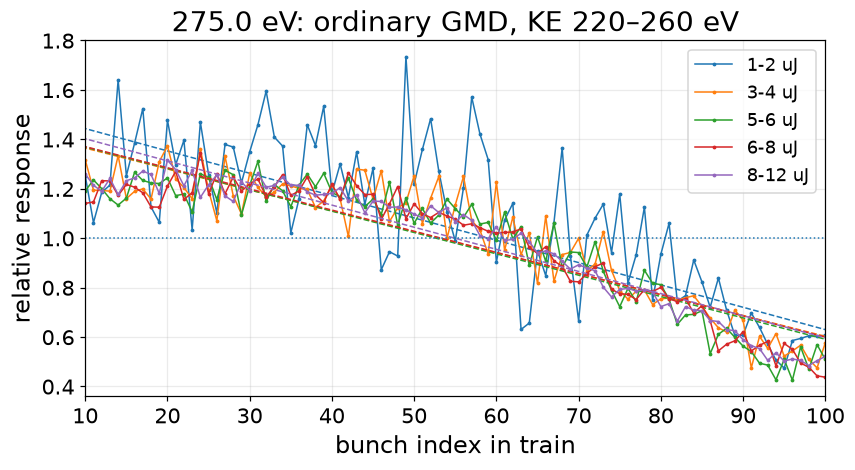

In [4]:
# Baseline on the same shot population used in the final comparison.
all_target = band_sums(data["target_counts"], gmd, common)
all_gmd = band_sums(gmd, gmd, common)
all_shots = band_sums(np.ones_like(gmd), gmd, common)
baseline = bunch_metrics(all_target, all_gmd, all_shots)
print(f"GMD: flatness={baseline['flatness']:.5f}, slope={baseline['slope']:+.3f}% / 10 bunches")
fig, ax = plt.subplots(figsize=(8,4.5))
plot_bunch_response(baseline, "275.0 eV: ordinary GMD, KE 220–260 eV", ax)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Existing empirical $C_b$ correction
Can a reference-derived factor remove the target bunch dependence? Learn each factor from training trains only. In the comparison below, x is bunch position and y is relative target response after GMD × $C_b$ normalisation. Flatter curves indicate successful empirical transfer; they do not identify its physical cause.

In [5]:
# Existing Cb construction, independently for each training fold.
cb_folds = np.full((INDEP_CV_MOD, n_bunch), np.nan)
for off in INDEP_CV_OFFSETS:
    training = common & ((train_ids % INDEP_CV_MOD) != off)[:,None]
    cb_folds[off] = build_compare_cb(
        band_sums(data["ref_counts"], gmd, training),
        band_sums(gmd, gmd, training),
        band_sums(np.ones_like(gmd), gmd, training), bunch_start=INDEP_BUNCH_START)
print("Cb learned separately from reference-region training shots in all five folds.")

Cb learned separately from reference-region training shots in all five folds.


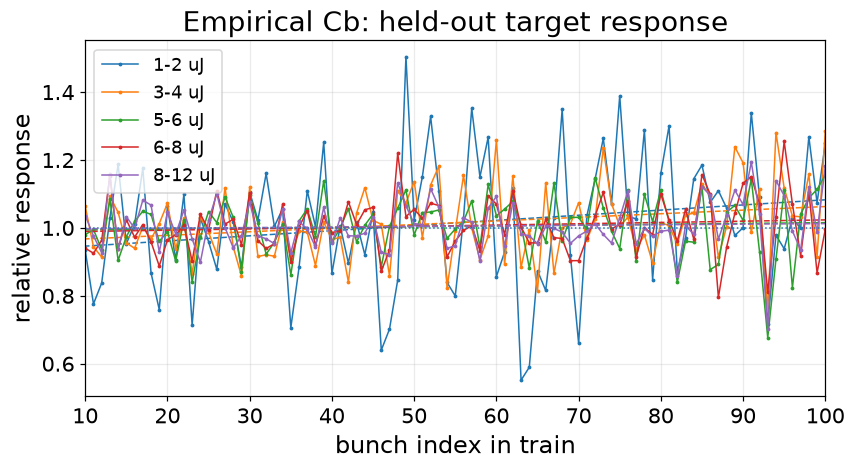

Cb: flatness=0.09511, slope=+0.513% / 10 bunches


In [6]:
# Held-out empirical Cb transfer, retaining the original common shot population.
cb_target = np.zeros((len(INDEP_GMD_BANDS),n_bunch))
cb_norm = np.zeros_like(cb_target); cb_shots = np.zeros_like(cb_target)
for off in INDEP_CV_OFFSETS:
    rows = train_ids % INDEP_CV_MOD == off
    cb_target += band_sums(data["target_counts"][rows],gmd[rows],common[rows])
    cb_norm += band_sums(gmd[rows]*cb_folds[off],gmd[rows],common[rows])
    cb_shots += band_sums(np.ones_like(gmd[rows]),gmd[rows],common[rows])
cb_metric = bunch_metrics(cb_target,cb_norm,cb_shots)
fig,ax = plt.subplots(figsize=(8,4.5))
plot_bunch_response(cb_metric,"Empirical Cb: held-out target response",ax)
ax.legend(); plt.tight_layout(); plt.show()
print(f"Cb: flatness={cb_metric['flatness']:.5f}, slope={cb_metric['slope']:+.3f}% / 10 bunches")

## 4. Previous-GMD history models
Do previous pulse energies improve on the current-GMD line M0? M5/M10 add the preceding 5/10-shot mean GMD; E2/E3 add exponentially weighted previous GMD with 2/3-shot time constants. All fits use training reference counts; all methods share `common`. x is current bunch position; y is held-out relative target response using the model prediction as denominator. A reduced slope indicates transfer to the target region, not proof of an electron-history mechanism.

In [7]:
# Existing linear-model fitting logic, using training reference counts.
beta_cv = {name:[] for name in INDEP_MODELS}
for off in INDEP_CV_OFFSETS:
    training = common & ((train_ids % INDEP_CV_MOD) != off)[:,None]
    y = data["ref_counts"][training].astype(float)
    for name in INDEP_MODELS:
        x = designs[name][training]
        beta_cv[name].append(np.linalg.lstsq(x.T @ x, x.T @ y, rcond=None)[0])
beta_cv = {name:np.asarray(beta) for name,beta in beta_cv.items()}
print("Mean reference-region coefficients across training folds:")
for name in INDEP_MODELS:
    print(name, beta_cv[name].mean(axis=0))

Mean reference-region coefficients across training folds:
M0 [0.00079441 0.00275105]
M5 [-0.00019282  0.00271029  0.00019295]
M10 [ 1.06090531e-03  2.76116718e-03 -5.12141038e-05]
E2 [-0.0001876   0.00271003  0.00019255]
E3 [1.37073310e-05 2.71943507e-03 1.52073649e-04]


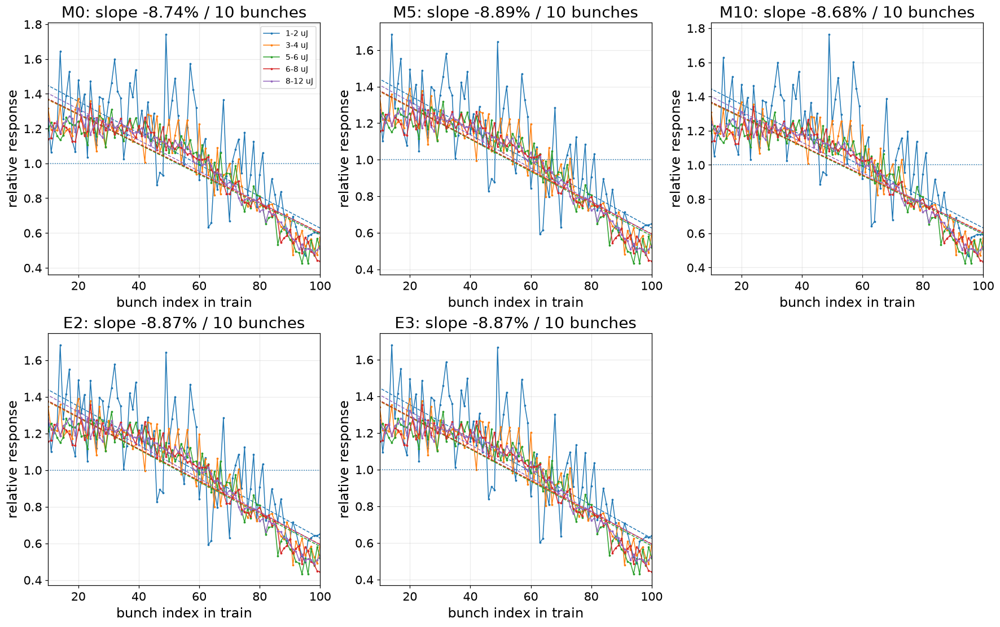

,target slope,target flatness
M0,-8.744036,0.247938
M5,-8.885926,0.247749
M10,-8.683760,0.247457
E2,-8.868634,0.247242
E3,-8.868372,0.248112


In [8]:
# Compact previous-GMD comparison; no global electron-history model is presented as a final correction.
previous_gmd_metrics = {}
for name in INDEP_MODELS:
    obs = np.zeros((len(INDEP_GMD_BANDS),n_bunch))
    norm = np.zeros_like(obs); shots = np.zeros_like(obs)
    for off in INDEP_CV_OFFSETS:
        rows = train_ids % INDEP_CV_MOD == off
        pred = designs[name][rows] @ beta_cv[name][off]
        obs += band_sums(data["target_counts"][rows],gmd[rows],common[rows])
        norm += band_sums(pred,gmd[rows],common[rows])
        shots += band_sums(np.ones_like(gmd[rows]),gmd[rows],common[rows])
    if np.any((shots > 0) & (~np.isfinite(norm) | (norm <= 0))):
        raise ValueError(f"{name}: invalid summed prediction on the original common population.")
    previous_gmd_metrics[name] = bunch_metrics(obs,norm,shots)
fig,axes = plt.subplots(2,3,figsize=(16,10),constrained_layout=True)
for ax,name in zip(axes.flat,INDEP_MODELS):
    m = previous_gmd_metrics[name]
    plot_bunch_response(m,f"{name}: slope {m['slope']:+.2f}% / 10 bunches",ax)
axes[0,0].legend(fontsize=9); axes.flat[-1].set_visible(False); plt.show()
display(pd.DataFrame({name:{"target slope":m["slope"],"target flatness":m["flatness"]} for name,m in previous_gmd_metrics.items()}).T)

## 5. Electron-history model tests
### 5.1 Exponential history: initial global fit
Does an exponentially weighted total-electron load predict reference response? The retained initial model is $y_{ref}=(a+bG)e^{-\alpha H}$, with earlier total counts weighted by $e^{-d/\tau}$. Positive alpha means suppression; negative alpha means enhancement. This section prints training fits rather than a final correction plot. It does not independently control bunch position and is exploratory; the corrected conditional tests below are the main history-model results. A bound-limited tau is not an identified physical timescale.

In [9]:
# Detector response and residual Cb fitted separately on each fold's training trains.
electron_fits = []
residual_cb_folds = np.full_like(cb_folds,np.nan)
for off in INDEP_CV_OFFSETS:
    rows = train_ids % INDEP_CV_MOD != off
    g, selected = gmd[rows], common[rows]
    fit = fit_electron_response(g, data["ref_counts"][rows], data["total_electrons"][rows], selected)
    electron_fits.append(fit)
    R = np.exp(-fit["alpha"] * electron_history(data["total_electrons"][rows], fit["tau"]))
    residual_cb_folds[off] = build_compare_cb(
        band_sums(data["ref_counts"][rows],g,selected), band_sums(g*R,g,selected),
        band_sums(np.ones_like(g),g,selected), bunch_start=INDEP_BUNCH_START)
    print(f"fold {off}: tau={fit['tau']:.3f} bunches, alpha={fit['alpha']:.6g}/electron; "
          f"training reference MSE={fit['training_mse']:.5f}")
print("At alpha=0, tau is unidentifiable; a bound-limited fit is not evidence of a time scale.")

fold 0: tau=3.025 bunches, alpha=-0.0535529/electron; training reference MSE=0.01690
fold 1: tau=3.058 bunches, alpha=-0.0566541/electron; training reference MSE=0.01688
fold 2: tau=3.022 bunches, alpha=-0.0523906/electron; training reference MSE=0.01691
fold 3: tau=3.058 bunches, alpha=-0.0544574/electron; training reference MSE=0.01692
fold 4: tau=3.043 bunches, alpha=-0.053983/electron; training reference MSE=0.01693
At alpha=0, tau is unidentifiable; a bound-limited fit is not evidence of a time scale.


### 5.2 Free linear lag model: initial global implementation
The colleague's model $R_i=1+\sum_d k_dN_{i-d}$ makes no exponential-history assumption. The original global implementation appeared to reduce the bunch slope, but lag and current bunch position were partly confounded: short lags were constrained by many bunch positions, large lags mostly by late bunches. Its apparent improvement is therefore **exploratory evidence, not a final correction**.

The first panel uses ridge strength on x and held-out reference MSE improvement on y; positive improvement means better prediction relative to the global baseline. The second uses previous-shot lag on x and a response coefficient per detected electron on y; negative/positive coefficients describe suppression/enhancement within this fitted model, without establishing causality. Ridge selection uses these held-out scores, so the selected minimum is not a separate unbiased validation.

,ref_mse,baseline_mse,min_R,ref MSE improvement (%)
ridge,,,,
0.0000,0.016894,0.016909,-1.570876,0.087534
0.0001,0.016894,0.016909,-1.569736,0.087537
0.0010,0.016894,0.016909,-1.559410,0.087566
0.0100,0.016894,0.016909,-1.457401,0.087788
0.1000,0.016894,0.016909,-1.152300,0.088841
1.0000,0.016894,0.016909,-0.482072,0.087643
10.0000,0.016900,0.016909,0.468633,0.047585


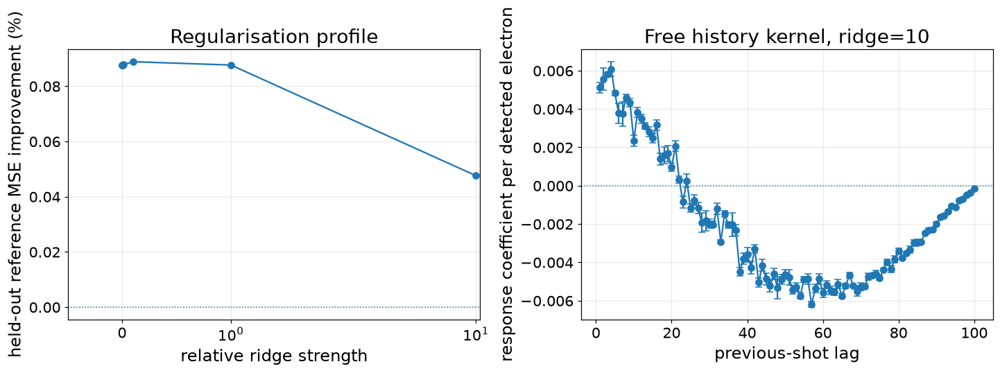

Best ridge strength from held-out 190–220 eV reference data: 10
GMD target:        flatness=0.24765, slope=-8.740% / 10 bunches
Free lag kernel:   flatness=0.19793, slope=-6.700% / 10 bunches


In [10]:
# --- Free shot-history kernel: let each previous bunch have its own coefficient ---

MAX_LAG = 100
RIDGE_GRID = np.array([0,1e-4,1e-3,1e-2,1e-1,1,10],dtype=float)
# RIDGE_GRID = np.array([0,1e-4,1e-3,1e-2,1e-1,1,10],dtype=float)
KERNEL_CHUNK = 200_000

def lag_matrix_selected(total,selected,max_lag):
    rows,cols = np.where(selected)
    X = np.zeros((rows.size,max_lag),dtype=np.float32)
    for d in range(1,max_lag+1):
        ok = cols >= d
        X[ok,d-1] = total[rows[ok],cols[ok]-d]
    return X,rows,cols

def kernel_normal_equations(total,selected,base,y,max_lag):
    rows,cols = np.where(selected)
    A = np.zeros((max_lag,max_lag),dtype=float)
    z = np.zeros(max_lag,dtype=float)
    for start in range(0,rows.size,KERNEL_CHUNK):
        rr,cc = rows[start:start+KERNEL_CHUNK],cols[start:start+KERNEL_CHUNK]
        X = np.zeros((rr.size,max_lag),dtype=float)
        for d in range(1,max_lag+1):
            ok = cc >= d
            X[ok,d-1] = total[rr[ok],cc[ok]-d]
        b = base[rr,cc]
        F = X*b[:,None]
        residual = y[rr,cc]-b
        A += F.T@F
        z += F.T@residual
    return A,z

def kernel_reference_mse(total,selected,base,y,k):
    X,rows,cols = lag_matrix_selected(total,selected,len(k))
    R = 1+X@k
    pred = base[rows,cols]*R
    return np.mean((y[rows,cols]-pred)**2),np.min(R)

def kernel_response(total,k):
    R = np.ones(total.shape,dtype=float)
    for d,kd in enumerate(k,1): R[:,d:] += kd*total[:,:-d]
    return R

kernel_rows = []
kernel_fits = {}
baseline_ref_mse = {}

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    a,b = beta_cv["M0"][off]
    base_train = a+b*gmd[train_rows]
    base_test = a+b*gmd[test_rows]
    y_train = data["ref_counts"][train_rows].astype(float)
    y_test = data["ref_counts"][test_rows].astype(float)
    sel_train,sel_test = common[train_rows],common[test_rows]

    A,z = kernel_normal_equations(data["total_electrons"][train_rows],sel_train,base_train,y_train,MAX_LAG)
    scale = np.mean(np.diag(A)[np.diag(A) > 0])
    rows_test,cols_test = np.where(sel_test)
    baseline_ref_mse[off] = np.mean((y_test[rows_test,cols_test]-base_test[rows_test,cols_test])**2)

    for j,lam in enumerate(RIDGE_GRID):
        k = np.linalg.lstsq(A+lam*scale*np.eye(MAX_LAG),z,rcond=None)[0]
        mse,min_R = kernel_reference_mse(data["total_electrons"][test_rows],sel_test,base_test,y_test,k)
        kernel_fits[(off,j)] = k
        kernel_rows.append({"fold":off,"ridge":lam,"ref_mse":mse,"baseline_mse":baseline_ref_mse[off],"min_R":min_R})

kernel_profile = pd.DataFrame(kernel_rows)
kernel_summary = kernel_profile.groupby("ridge").agg(ref_mse=("ref_mse","mean"),baseline_mse=("baseline_mse","mean"),min_R=("min_R","min"))
kernel_summary["ref MSE improvement (%)"] = 100*(1-kernel_summary["ref_mse"]/kernel_summary["baseline_mse"])
display(kernel_summary.round(6))

valid = kernel_summary["min_R"] > 0
best_ridge = kernel_summary.loc[valid,"ref_mse"].idxmin()
best_j = int(np.where(RIDGE_GRID == best_ridge)[0][0])
K = np.vstack([kernel_fits[(off,best_j)] for off in INDEP_CV_OFFSETS])

hold_target_kernel = np.zeros((INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch))
hold_shots_kernel = np.zeros_like(hold_target_kernel)
hold_gmd_kernel = np.zeros_like(hold_target_kernel)
hold_norm_kernel = np.zeros_like(hold_target_kernel)

for off in INDEP_CV_OFFSETS:
    test_rows = train_ids % INDEP_CV_MOD == off
    g = gmd[test_rows]
    selected = common[test_rows]
    R = kernel_response(data["total_electrons"][test_rows],kernel_fits[(off,best_j)])
    if np.any(R[selected] <= 0): raise ValueError("Free-kernel response became non-positive on held-out shots.")
    hold_target_kernel[off] = band_sums(data["target_counts"][test_rows],g,selected)
    hold_shots_kernel[off] = band_sums(np.ones_like(g),g,selected)
    hold_gmd_kernel[off] = band_sums(g,g,selected)
    hold_norm_kernel[off] = band_sums(g*R,g,selected)

obs_kernel = hold_target_kernel.sum(axis=0)
shots_kernel = hold_shots_kernel.sum(axis=0)
gmd_kernel_metric = bunch_metrics(obs_kernel,hold_gmd_kernel.sum(axis=0),shots_kernel)
free_kernel_metric = bunch_metrics(obs_kernel,hold_norm_kernel.sum(axis=0),shots_kernel)

fig,axes = plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
axes[0].plot(RIDGE_GRID,kernel_summary["ref MSE improvement (%)"],"o-")
axes[0].axhline(0,ls=":",lw=1); axes[0].set(xscale="symlog",xlabel="relative ridge strength",ylabel="held-out reference MSE improvement (%)",title="Regularisation profile"); axes[0].grid(alpha=0.25)
lags = np.arange(1,MAX_LAG+1)
axes[1].errorbar(lags,K.mean(axis=0),yerr=K.std(axis=0,ddof=1),fmt="o-",capsize=3)
axes[1].axhline(0,ls=":",lw=1); axes[1].set(xlabel="previous-shot lag",ylabel="response coefficient per detected electron",title=f"Free history kernel, ridge={best_ridge:g}"); axes[1].grid(alpha=0.25)
plt.show()

print(f"Best ridge strength from held-out 190–220 eV reference data: {best_ridge:g}")
print(f"GMD target:        flatness={gmd_kernel_metric['flatness']:.5f}, slope={gmd_kernel_metric['slope']:+.3f}% / 10 bunches")
print(f"Free lag kernel:   flatness={free_kernel_metric['flatness']:.5f}, slope={free_kernel_metric['slope']:+.3f}% / 10 bunches")

#### Technical support for the exploratory kernel
How much data constrains each lag? x is previous-shot lag; y is training observations in millions. Decreasing support shows why late lags are less constrained and restricted to late bunches. The optional fixed-bunch plot uses lag on x and fitted response coefficient on y; restricting current position helps diagnose the global implementation but does not make its kernel a final physical interpretation.

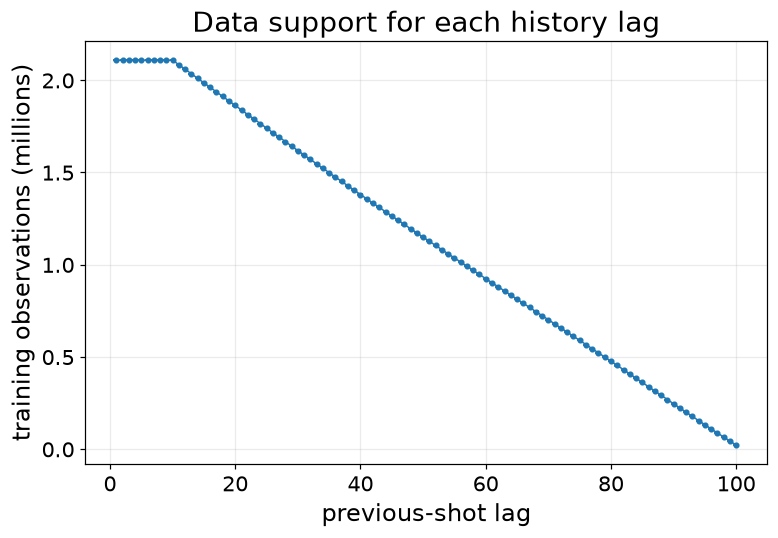

lag   1: 2,108,639 training observations (100.0% of lag-1 support)
lag   5: 2,108,639 training observations (100.0% of lag-1 support)
lag  10: 2,108,639 training observations (100.0% of lag-1 support)
lag  20: 1,863,036 training observations (88.4% of lag-1 support)
lag  40: 1,380,246 training observations (65.5% of lag-1 support)
lag  60: 924,416 training observations (43.8% of lag-1 support)
lag  80: 476,262 training observations (22.6% of lag-1 support)
lag 100: 21,758 training observations (1.0% of lag-1 support)


In [11]:
# --- Diagnostic: how many training observations constrain each lag? ---

lags = np.arange(1,MAX_LAG+1)
lag_support = np.zeros((INDEP_CV_MOD,MAX_LAG),dtype=int)

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    selected = common[train_rows]
    for d in lags: lag_support[off,d-1] = np.count_nonzero(selected[:,d:])

support_mean = lag_support.mean(axis=0)
support_sd = lag_support.std(axis=0,ddof=1)
support_fraction = support_mean/support_mean[0]

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(lags,support_mean/1e6,yerr=support_sd/1e6,fmt="o-",ms=3,lw=1,capsize=2)
ax.set(xlabel="previous-shot lag",ylabel="training observations (millions)",title="Data support for each history lag")
ax.grid(alpha=0.25)
plt.show()

for d in [1,5,10,20,40,60,80,100]:
    if d <= MAX_LAG: print(f"lag {d:3d}: {support_mean[d-1]:,.0f} training observations ({100*support_fraction[d-1]:.1f}% of lag-1 support)")

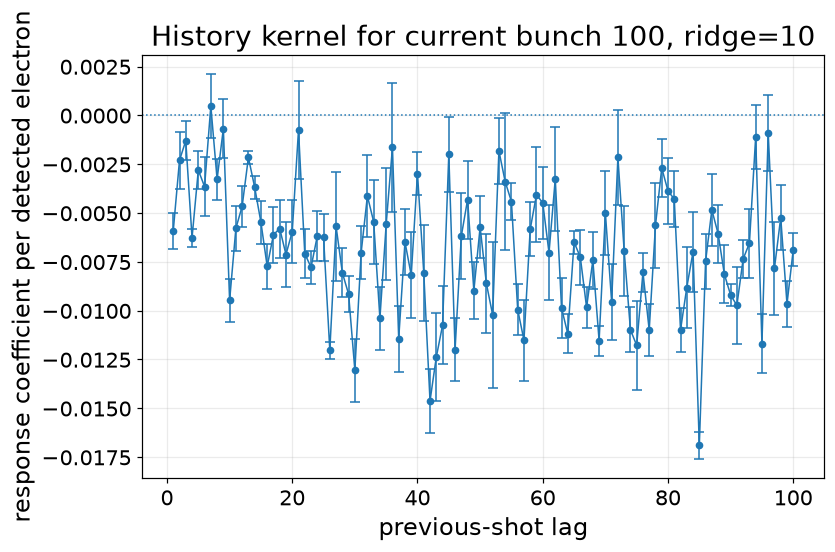

Current bunch index: 100
History available: lags 1–100
Training shots per fold: [np.int64(21751), np.int64(21739), np.int64(21776), np.int64(21754), np.int64(21772)]


In [12]:
# --- Free history kernel for one chosen bunch position only ---

BUNCH_POSITION = 100  # bunch index, so 60 means the point labelled 60 on the existing plots
POSITION_RIDGE = 10

max_lag_pos = BUNCH_POSITION
K_pos = []

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    selected = common[train_rows,BUNCH_POSITION]

    total = data["total_electrons"][train_rows]
    g = gmd[train_rows,BUNCH_POSITION]
    y = data["ref_counts"][train_rows,BUNCH_POSITION].astype(float)
    a,b = beta_cv["M0"][off]
    base = a+b*g

    use = selected & np.isfinite(base) & (base > 0)
    y,base = y[use],base[use]
    total = total[use]

    X = np.column_stack([total[:,BUNCH_POSITION-d] for d in range(1,max_lag_pos+1)]).astype(float)
    F = X*base[:,None]
    residual = y-base

    A = F.T@F
    z = F.T@residual
    scale = np.mean(np.diag(A)[np.diag(A) > 0])
    k = np.linalg.lstsq(A+POSITION_RIDGE*scale*np.eye(max_lag_pos),z,rcond=None)[0]
    K_pos.append(k)

K_pos = np.asarray(K_pos)
lags_pos = np.arange(1,max_lag_pos+1)

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(lags_pos,K_pos.mean(axis=0),yerr=K_pos.std(axis=0,ddof=1),fmt="o-",ms=4,lw=1,capsize=3)
ax.axhline(0,ls=":",lw=1)
ax.set(xlabel="previous-shot lag",ylabel="response coefficient per detected electron",title=f"History kernel for current bunch {BUNCH_POSITION}, ridge={POSITION_RIDGE:g}")
ax.grid(alpha=0.25)
plt.show()

print(f"Current bunch index: {BUNCH_POSITION}")
print(f"History available: lags 1–{max_lag_pos}")
print("Training shots per fold:",[np.count_nonzero(common[train_ids % INDEP_CV_MOD != off,BUNCH_POSITION]) for off in INDEP_CV_OFFSETS])

### 5.3 Conditional history tests controlling bunch position
Once current bunch position and its local GMD response are known, do previous **total** electron counts add predictive information? Fit an independent $a_b+b_bG$ line at each position using training trains, and centre history features by the training mean at that position. These tests use `current_mask`; they do not require the old previous-GMD features.

The exponential plots use tau (previous-shot memory scale) on x, and fitted alpha, held-out reference MSE improvement, or independent target slope on y. Positive alpha indicates suppression; improved reference prediction and reduced target slope are distinct tests. Target transfer retains the existing GMD × history-response normalisation; the local reference baseline is used to fit/evaluate reference counts, not substituted as the target denominator.

In [13]:
# --- Helpers for conditional history tests: control current bunch position first ---

def fit_bunch_baseline(g,y,selected):
    """Fit an independent current-GMD line a_b + b_b*G for every bunch position."""
    base = np.full_like(g,np.nan,dtype=float)
    beta = np.full((g.shape[1],2),np.nan,dtype=float)
    for b in range(g.shape[1]):
        use = selected[:,b] & np.isfinite(g[:,b])
        if np.count_nonzero(use) < 2: continue
        X = np.column_stack((np.ones(np.count_nonzero(use)),g[use,b]))
        beta[b] = np.linalg.lstsq(X,y[use,b].astype(float),rcond=None)[0]
        base[:,b] = beta[b,0]+beta[b,1]*g[:,b]
    return base,beta

def apply_bunch_baseline(g,beta):
    return beta[:,0][None,:]+beta[:,1][None,:]*g

def centre_by_bunch(x_train,x_test,selected_train):
    """Subtract the TRAINING mean at each current bunch position."""
    mu = np.zeros(x_train.shape[1],dtype=float)
    for b in range(x_train.shape[1]):
        use = selected_train[:,b] & np.isfinite(x_train[:,b])
        if np.any(use): mu[b] = np.mean(x_train[use,b])
    return x_train-mu[None,:],x_test-mu[None,:],mu

def grouped_history_features(total,windows):
    """Feature j = electrons in the requested previous-shot lag window."""
    n_trains,n_bunch = total.shape
    X = np.zeros((n_trains,n_bunch,len(windows)),dtype=float)
    for j,(d0,d1) in enumerate(windows):
        for b in range(n_bunch):
            lo,hi = max(0,b-d1),b-d0
            if hi >= 0 and hi >= lo: X[:,b,j] = total[:,lo:hi+1].sum(axis=1)
    return X

def centre_features_by_bunch(X_train,X_test,selected_train):
    mu = np.zeros((X_train.shape[1],X_train.shape[2]),dtype=float)
    for b in range(X_train.shape[1]):
        use = selected_train[:,b]
        if np.any(use): mu[b] = X_train[use,b].mean(axis=0)
    return X_train-mu[None,:,:],X_test-mu[None,:,:],mu

,alpha_mean,alpha_sd,baseline_mse,history_mse,ref MSE improvement (%),target slope,target flatness,target slope SD
tau,,,,,,,,
0.25,0.000000,0.000000,0.016891,0.016891,0.000000,-8.739881,0.247649,0.187521
0.50,0.000000,0.000000,0.016891,0.016891,0.000000,-8.739881,0.247649,0.187521
1.00,0.000000,0.000000,0.016891,0.016891,0.000000,-8.739881,0.247649,0.187521
2.00,-0.000002,0.000005,0.016891,0.016891,0.000000,-8.739881,0.247649,0.187521
3.00,-0.000014,0.000002,0.016891,0.016891,0.000001,-8.739879,0.247649,0.187521
5.00,-0.000025,0.000004,0.016891,0.016891,0.000003,-8.739875,0.247649,0.187522
10.00,-0.008034,0.007316,0.016891,0.016891,0.000187,-8.737288,0.247738,0.189220
20.00,-0.008803,0.000726,0.016891,0.016890,0.001715,-8.743136,0.247897,0.189100
50.00,-0.005521,0.000313,0.016891,0.016890,0.001667,-8.757121,0.248091,0.188061


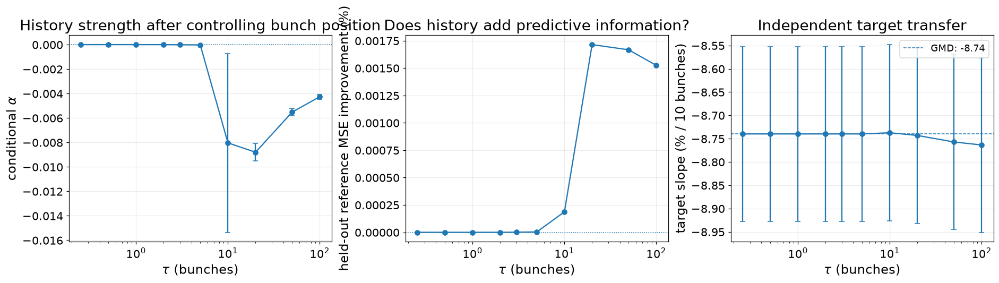

In [14]:
# --- Conditional exponential-history test: does H add information AFTER bunch position is known? ---

COND_TAU_GRID = np.array([0.25,0.5,1,2,3,5,10,20,50,100],dtype=float)
COND_ALPHA_BOUNDS = (-0.5,0.5)

cond_exp_rows = []
shape = (INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch)
cond_exp_target = np.zeros(shape)
cond_exp_shots = np.zeros(shape)
cond_exp_gmd = np.zeros(shape)
cond_exp_norm = np.zeros((len(COND_TAU_GRID),*shape))

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off
    g_train,g_test = gmd[train_rows],gmd[test_rows]
    sel_train,sel_test = current_mask[train_rows],current_mask[test_rows]
    y_train,y_test = data["ref_counts"][train_rows].astype(float),data["ref_counts"][test_rows].astype(float)

    base_train,local_beta = fit_bunch_baseline(g_train,y_train,sel_train)
    base_test = apply_bunch_baseline(g_test,local_beta)
    use_train = sel_train & np.isfinite(base_train) & (base_train > 0)
    use_test = sel_test & np.isfinite(base_test) & (base_test > 0)
    baseline_mse = np.mean((y_test[use_test]-base_test[use_test])**2)

    cond_exp_target[off] = band_sums(data["target_counts"][test_rows],g_test,sel_test)
    cond_exp_shots[off] = band_sums(np.ones_like(g_test),g_test,sel_test)
    cond_exp_gmd[off] = band_sums(g_test,g_test,sel_test)

    for j,tau in enumerate(COND_TAU_GRID):
        H_train = electron_history(data["total_electrons"][train_rows],tau)
        H_test = electron_history(data["total_electrons"][test_rows],tau)
        H_train,H_test,_ = centre_by_bunch(H_train,H_test,sel_train)

        def loss(x):
            pred = base_train[use_train]*np.exp(-x[0]*H_train[use_train])
            return np.mean((y_train[use_train]-pred)**2)

        result = minimize(loss,[0.0],method="L-BFGS-B",bounds=[COND_ALPHA_BOUNDS])
        if not result.success: raise RuntimeError(result.message)

        alpha = float(result.x[0])
        pred_test = base_test[use_test]*np.exp(-alpha*H_test[use_test])
        ref_mse = np.mean((y_test[use_test]-pred_test)**2)
        R_test = np.exp(-alpha*H_test)

        cond_exp_norm[j,off] = band_sums(g_test*R_test,g_test,sel_test)
        cond_exp_rows.append({"fold":off,"tau":tau,"alpha":alpha,"baseline_mse":baseline_mse,"history_mse":ref_mse})

cond_exp = pd.DataFrame(cond_exp_rows)
cond_exp_summary = cond_exp.groupby("tau").agg(alpha_mean=("alpha","mean"),alpha_sd=("alpha","std"),baseline_mse=("baseline_mse","mean"),history_mse=("history_mse","mean"))
cond_exp_summary["ref MSE improvement (%)"] = 100*(1-cond_exp_summary["history_mse"]/cond_exp_summary["baseline_mse"])

obs = cond_exp_target.sum(axis=0)
shots = cond_exp_shots.sum(axis=0)
gmd_metric = bunch_metrics(obs,cond_exp_gmd.sum(axis=0),shots)
slopes,flatness,slope_sd = [],[],[]
for j,tau in enumerate(COND_TAU_GRID):
    m = bunch_metrics(obs,cond_exp_norm[j].sum(axis=0),shots)
    fm = [bunch_metrics(cond_exp_target[off],cond_exp_norm[j,off],cond_exp_shots[off]) for off in INDEP_CV_OFFSETS]
    slopes.append(m["slope"]); flatness.append(m["flatness"]); slope_sd.append(np.std([x["slope"] for x in fm],ddof=1))

cond_exp_summary["target slope"] = slopes
cond_exp_summary["target flatness"] = flatness
cond_exp_summary["target slope SD"] = slope_sd
display(cond_exp_summary.round(6))

fig,axes = plt.subplots(1,3,figsize=(17,4.5),constrained_layout=True)
axes[0].errorbar(COND_TAU_GRID,cond_exp_summary["alpha_mean"],yerr=cond_exp_summary["alpha_sd"],fmt="o-",capsize=3)
axes[0].axhline(0,ls=":",lw=1); axes[0].set(xscale="log",xlabel=r"$\tau$ (bunches)",ylabel=r"conditional $\alpha$",title="History strength after controlling bunch position"); axes[0].grid(alpha=0.25)
axes[1].plot(COND_TAU_GRID,cond_exp_summary["ref MSE improvement (%)"],"o-")
axes[1].axhline(0,ls=":",lw=1); axes[1].set(xscale="log",xlabel=r"$\tau$ (bunches)",ylabel="held-out reference MSE improvement (%)",title="Does history add predictive information?"); axes[1].grid(alpha=0.25)
axes[2].errorbar(COND_TAU_GRID,cond_exp_summary["target slope"],yerr=cond_exp_summary["target slope SD"],fmt="o-",capsize=3)
axes[2].axhline(gmd_metric["slope"],ls="--",lw=1,label=f"GMD: {gmd_metric['slope']:+.2f}")
axes[2].set(xscale="log",xlabel=r"$\tau$ (bunches)",ylabel="target slope (% / 10 bunches)",title="Independent target transfer"); axes[2].grid(alpha=0.25); axes[2].legend()
plt.show()

#### Corrected grouped linear-history test
This is the final version of the linear-combination history test: previous total counts grouped into lag windows, conditioned on independent bunch-specific current-GMD lines. x is ridge strength for the prediction/transfer panels, and previous-shot lag window for the coefficient panel. y is held-out reference MSE improvement, independent target slope, or response coefficient per electron. An improvement in one observable need not improve the other.

Earlier, with the multiplicative bunch baseline, held-out gains were small and target transfer did not remove the slope. The full-data recomputation with independent intercepts/slopes gives a best reference MSE improvement of **0.078526%** (ridge 0.01), while the target slope changes from **−8.674948 to −8.743981% per 10 bunches**. This very small reference gain and slightly worse target slope do not provide a useful correction/explanation of the main bunch trend. The table and printed values below document the recomputation. No scientific significance threshold is imposed; selected ridge scores are exploratory because selection uses the same held-out scores.

Settings with nonpositive history responses in any fold are not scored as successful fits. All five folds must have valid reference scores and target normalisations before a ridge setting can be selected; invalid folds are never silently omitted to improve the average.


,baseline_mse,history_mse,history_folds,min_R,ref MSE improvement (%),target slope,target flatness
ridge,,,,,,,
0.0000,0.016891,0.016890,5,0.761833,0.001547,-8.739285,0.247858
0.0001,0.016891,0.016890,5,0.762067,0.001547,-8.739287,0.247858
0.0010,0.016891,0.016890,5,0.764155,0.001549,-8.739313,0.247858
0.0100,0.016891,0.016890,5,0.782752,0.001572,-8.739551,0.247858
0.1000,0.016891,0.016890,5,0.838305,0.001680,-8.741178,0.247858
1.0000,0.016891,0.016890,5,0.924174,0.001512,-8.744751,0.247828
10.0000,0.016891,0.016891,5,0.977740,0.000581,-8.742433,0.247712


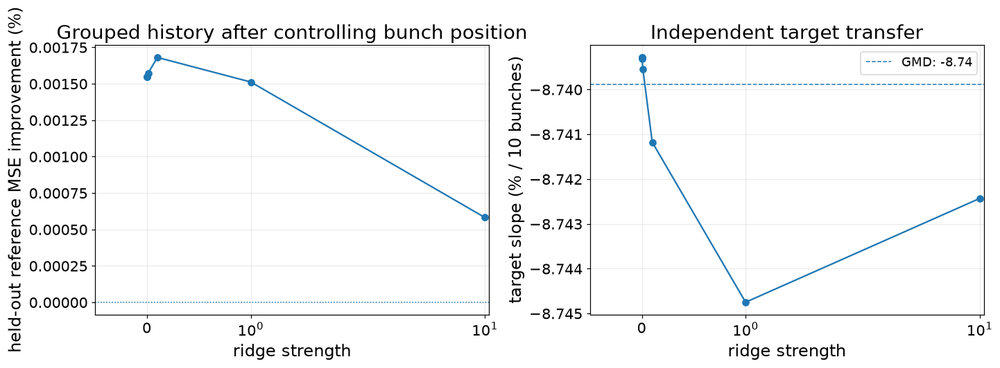

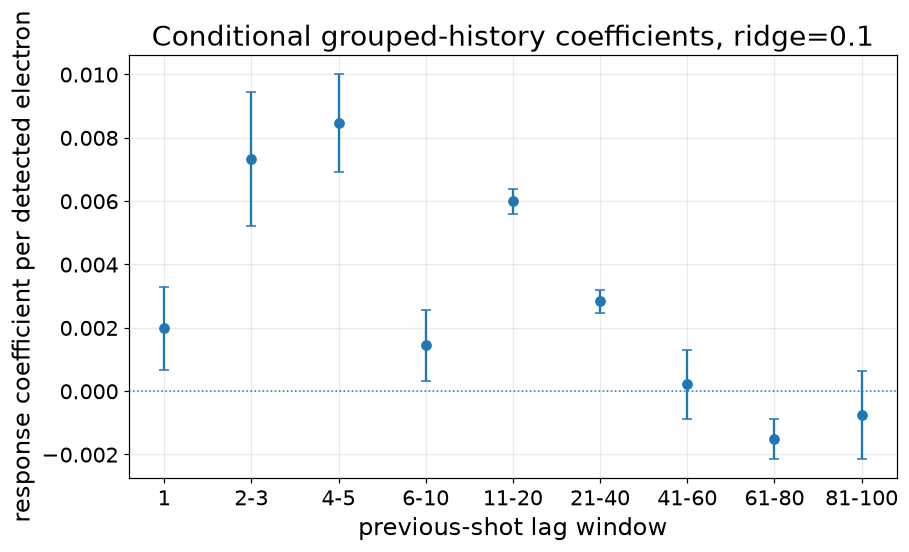

Corrected grouped-linear test: best scored ridge=0.1
Reference held-out MSE improvement: +0.001680%
Target slope: GMD=-8.739881, grouped history=-8.741178% / 10 bunches
Assess predictive usefulness from both reference improvement and target transfer; these scores do not establish physical significance.


In [15]:
# --- Conditional grouped-lag history: flexible test without 100 unstable coefficients ---

HISTORY_WINDOWS = [(1,1),(2,3),(4,5),(6,10),(11,20),(21,40),(41,60),(61,80),(81,100)]
COND_RIDGE_GRID = np.array([0,1e-4,1e-3,1e-2,1e-1,1,10],dtype=float)

shape = (INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch)
group_rows = []
group_coeffs = {}
group_target = np.zeros(shape)
group_shots = np.zeros(shape)
group_gmd = np.zeros(shape)
group_norm = np.zeros((len(COND_RIDGE_GRID),*shape))

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off
    g_train,g_test = gmd[train_rows],gmd[test_rows]
    sel_train,sel_test = current_mask[train_rows],current_mask[test_rows]
    y_train,y_test = data["ref_counts"][train_rows].astype(float),data["ref_counts"][test_rows].astype(float)

    base_train,local_beta = fit_bunch_baseline(g_train,y_train,sel_train)
    base_test = apply_bunch_baseline(g_test,local_beta)
    use_train = sel_train & np.isfinite(base_train) & (base_train > 0)
    use_test = sel_test & np.isfinite(base_test) & (base_test > 0)
    baseline_mse = np.mean((y_test[use_test]-base_test[use_test])**2)

    X_train = grouped_history_features(data["total_electrons"][train_rows],HISTORY_WINDOWS)
    X_test = grouped_history_features(data["total_electrons"][test_rows],HISTORY_WINDOWS)
    X_train,X_test,_ = centre_features_by_bunch(X_train,X_test,sel_train)

    Xtr = X_train[use_train]
    rtr = y_train[use_train]-base_train[use_train]
    F = Xtr*base_train[use_train,None]
    A,z = F.T@F,F.T@rtr
    scale = np.mean(np.diag(A)[np.diag(A) > 0])

    group_target[off] = band_sums(data["target_counts"][test_rows],g_test,sel_test)
    group_shots[off] = band_sums(np.ones_like(g_test),g_test,sel_test)
    group_gmd[off] = band_sums(g_test,g_test,sel_test)

    for j,lam in enumerate(COND_RIDGE_GRID):
        k = np.linalg.lstsq(A+lam*scale*np.eye(len(HISTORY_WINDOWS)),z,rcond=None)[0]
        group_coeffs[(off,j)] = k
        R_test = 1+np.sum(X_test*k[None,None,:],axis=-1)
        if np.any(R_test[sel_test] <= 0): ref_mse = np.nan
        else: ref_mse = np.mean((y_test[use_test]-base_test[use_test]*R_test[use_test])**2)
        group_rows.append({"fold":off,"ridge":lam,"baseline_mse":baseline_mse,"history_mse":ref_mse,"min_R":np.nanmin(R_test[sel_test])})
        if np.all(R_test[sel_test] > 0): group_norm[j,off] = band_sums(g_test*R_test,g_test,sel_test)
        else: group_norm[j,off] = np.nan

group_df = pd.DataFrame(group_rows)
group_summary = group_df.groupby("ridge").agg(baseline_mse=("baseline_mse","mean"),history_mse=("history_mse","mean"),history_folds=("history_mse","count"),min_R=("min_R","min"))
# Invalid responses must not improve the score by dropping failed folds from the mean.
group_summary.loc[group_summary["history_folds"] != len(INDEP_CV_OFFSETS),"history_mse"] = np.nan
group_summary["ref MSE improvement (%)"] = 100*(1-group_summary["history_mse"]/group_summary["baseline_mse"])

obs = group_target.sum(axis=0)
shots = group_shots.sum(axis=0)
gmd_group_metric = bunch_metrics(obs,group_gmd.sum(axis=0),shots)
group_slopes,group_flatness = [],[]
for j,lam in enumerate(COND_RIDGE_GRID):
    if np.any(~np.isfinite(group_norm[j])): group_slopes.append(np.nan); group_flatness.append(np.nan)
    else:
        m = bunch_metrics(obs,group_norm[j].sum(axis=0),shots)
        group_slopes.append(m["slope"]); group_flatness.append(m["flatness"])

group_summary["target slope"] = group_slopes
group_summary["target flatness"] = group_flatness
display(group_summary.round(6))

fig,axes = plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
axes[0].plot(COND_RIDGE_GRID,group_summary["ref MSE improvement (%)"],"o-")
axes[0].axhline(0,ls=":",lw=1); axes[0].set(xscale="symlog",xlabel="ridge strength",ylabel="held-out reference MSE improvement (%)",title="Grouped history after controlling bunch position"); axes[0].grid(alpha=0.25)
axes[1].plot(COND_RIDGE_GRID,group_summary["target slope"],"o-")
axes[1].axhline(gmd_group_metric["slope"],ls="--",lw=1,label=f"GMD: {gmd_group_metric['slope']:+.2f}")
axes[1].set(xscale="symlog",xlabel="ridge strength",ylabel="target slope (% / 10 bunches)",title="Independent target transfer"); axes[1].grid(alpha=0.25); axes[1].legend()
plt.show()

eligible = (group_summary["history_folds"].to_numpy() == len(INDEP_CV_OFFSETS)) & np.isfinite(group_summary["history_mse"].to_numpy()) & np.isfinite(group_slopes)
if not np.any(eligible):
    print("No grouped-history setting has valid scores/target normalisation in every fold; no best model is selected.")
else:
    best_j = int(np.nanargmin(np.where(eligible,group_summary["history_mse"].to_numpy(),np.nan)))
    K_group = np.vstack([group_coeffs[(off,best_j)] for off in INDEP_CV_OFFSETS])
    labels = [f"{a}" if a == b else f"{a}-{b}" for a,b in HISTORY_WINDOWS]

    fig,ax = plt.subplots(figsize=(9,5))
    ax.errorbar(np.arange(len(labels)),K_group.mean(axis=0),yerr=K_group.std(axis=0,ddof=1),fmt="o",capsize=3)
    ax.axhline(0,ls=":",lw=1)
    ax.set_xticks(np.arange(len(labels)),labels)
    ax.set(xlabel="previous-shot lag window",ylabel="response coefficient per detected electron",title=f"Conditional grouped-history coefficients, ridge={COND_RIDGE_GRID[best_j]:g}")
    ax.grid(alpha=0.25)
    plt.show()
    print(f"Corrected grouped-linear test: best scored ridge={COND_RIDGE_GRID[best_j]:g}")
    print(f"Reference held-out MSE improvement: {group_summary['ref MSE improvement (%)'].iloc[best_j]:+.6f}%")
    print(f"Target slope: GMD={gmd_group_metric['slope']:+.6f}, grouped history={group_slopes[best_j]:+.6f}% / 10 bunches")
    print("Assess predictive usefulness from both reference improvement and target transfer; these scores do not establish physical significance.")

## 6. Bunch-dependent current-GMD response
Does the reference-electron/GMD relationship change through the train? In the selected-position panels, x is current GMD and y is mean reference electrons per shot. Local versus global lines expose changes in the response. In the key **Bunch-specific current-GMD response** plot, x is current bunch position and y is the fitted reference-electron slope per µJ. A decreasing slope means the same additional GMD produces fewer detected reference electrons later in the train, which one global GMD correction cannot capture. Intercepts may also vary. Local predictions are fitted on training trains only.

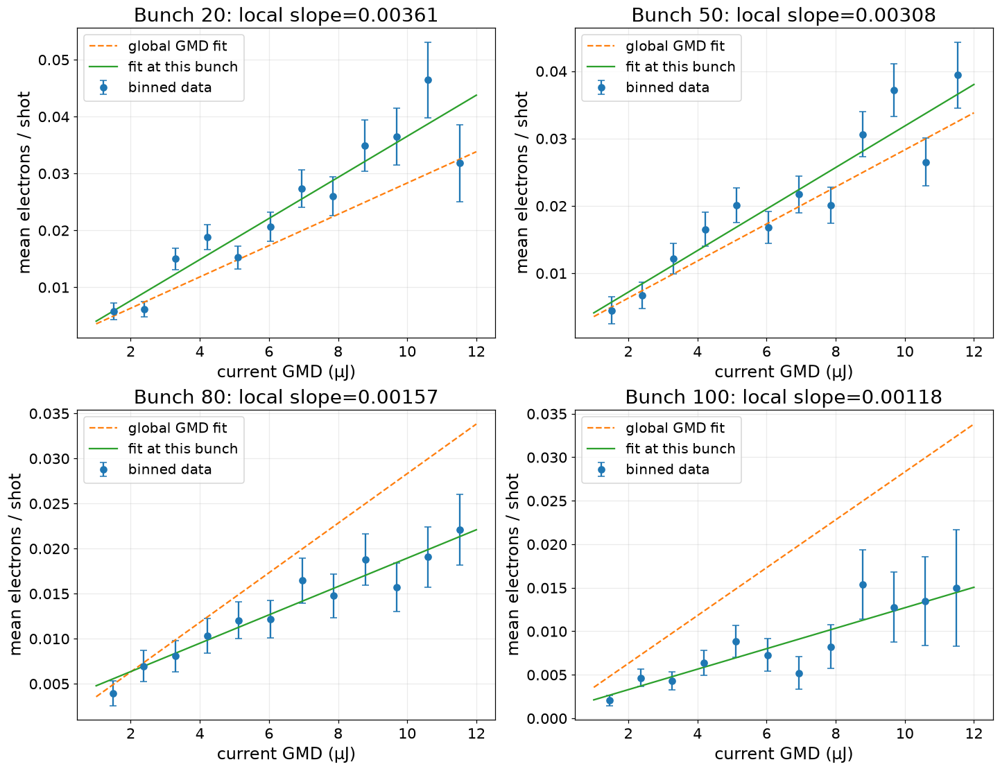

In [16]:
# --- Diagnostic: current reference-electron yield vs current GMD at different bunch positions ---

BUNCH_CHECKS = [20,50,80,100]
N_GMD_BINS = 12
g_grid = np.linspace(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1],200)
beta_mean = beta_cv["M0"].mean(axis=0)

fig,axes = plt.subplots(2,2,figsize=(13,10),constrained_layout=True)

for ax,bunch_pos in zip(axes.flat,BUNCH_CHECKS):
    valid = current_mask[:,bunch_pos]
    g = gmd[valid,bunch_pos]
    y = data["ref_counts"][valid,bunch_pos].astype(float)

    edges = np.linspace(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1],N_GMD_BINS+1)
    ibin = np.digitize(g,edges[1:-1])
    gx,ym,ye = [],[],[]
    for j in range(N_GMD_BINS):
        use = ibin == j
        if not np.any(use): continue
        gx.append(g[use].mean()); ym.append(y[use].mean()); ye.append(np.sqrt(y[use].sum())/use.sum())

    X = np.column_stack((np.ones_like(g),g))
    beta_local = np.linalg.lstsq(X,y,rcond=None)[0]

    ax.errorbar(gx,ym,yerr=ye,fmt="o",capsize=3,label="binned data")
    ax.plot(g_grid,beta_mean[0]+beta_mean[1]*g_grid,"--",lw=1.5,label="global GMD fit")
    ax.plot(g_grid,beta_local[0]+beta_local[1]*g_grid,"-",lw=1.5,label="fit at this bunch")
    ax.set(xlabel="current GMD (µJ)",ylabel="mean electrons / shot",title=f"Bunch {bunch_pos}: local slope={beta_local[1]:.5f}")
    ax.grid(alpha=0.25); ax.legend(fontsize=13)

plt.show()

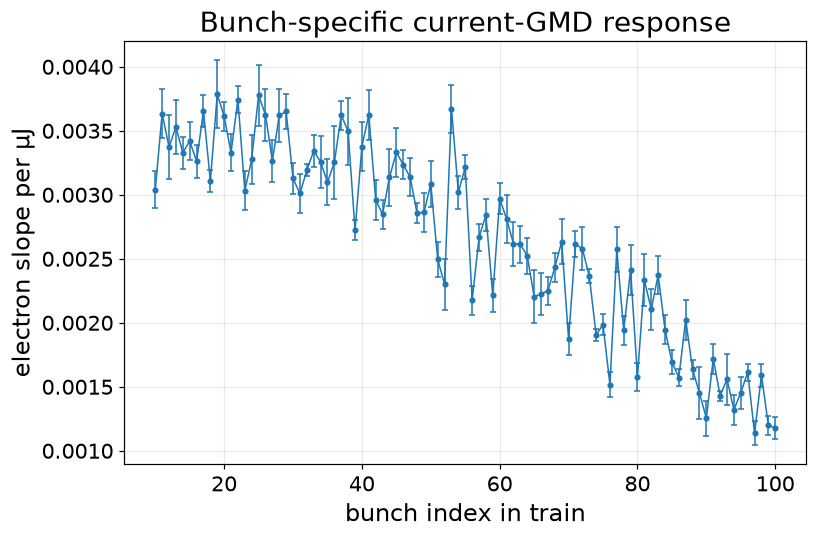

In [17]:
# --- Bunch-specific current-GMD baseline, fitted only on training trains ---

local_pred_cv = np.full_like(gmd,np.nan,dtype=float)
local_beta_cv = np.full((INDEP_CV_MOD,n_bunch,2),np.nan)

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    for b in range(INDEP_BUNCH_START,n_bunch):
        use_train = train_rows & current_mask[:,b]
        if np.count_nonzero(use_train) < 2: continue

        g_train = gmd[use_train,b]
        y_train = data["ref_counts"][use_train,b].astype(float)
        X = np.column_stack((np.ones_like(g_train),g_train))
        beta = np.linalg.lstsq(X,y_train,rcond=None)[0]
        local_beta_cv[off,b] = beta

        g_test = gmd[test_rows,b]
        local_pred_cv[test_rows,b] = beta[0]+beta[1]*g_test

# Diagnostic: mean fitted GMD slope at each bunch position.
mean_local_slope = np.full(n_bunch,np.nan); sd_local_slope = np.full(n_bunch,np.nan)
mean_local_slope[INDEP_BUNCH_START:] = np.nanmean(local_beta_cv[:,INDEP_BUNCH_START:,1],axis=0)
sd_local_slope[INDEP_BUNCH_START:] = np.nanstd(local_beta_cv[:,INDEP_BUNCH_START:,1],axis=0,ddof=1)
bunches_local = np.arange(INDEP_BUNCH_START,n_bunch)

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(bunches_local,mean_local_slope[bunches_local],yerr=sd_local_slope[bunches_local],fmt="o-",ms=3,lw=1,capsize=2)
ax.set(xlabel="bunch index in train",ylabel="electron slope per µJ",title="Bunch-specific current-GMD response")
ax.grid(alpha=0.25)
plt.show()

## 7. Direct detector-history / saturation diagnostics using total electrons
### 7.1 Total electron occupancy
Is recorded detector load substantial, and does the 50-hit storage ceiling matter? x is bunch position; y shows mean total counts, zero-shot fraction, and previous-five-shot zero fraction/mean load. Higher load means more recorded electrons; it is not necessarily the true load if undetected hits exist. Histories include previous shots regardless of their GMD. The printed ceiling counts are a sanity check, not a detector dead-time measurement.

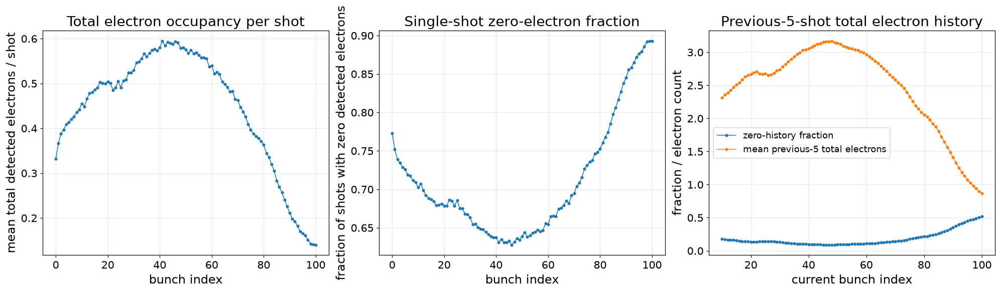

Mean total electrons / shot: 0.4444
Overall current-shot zero fraction: 71.0%
Mean previous-5 zero-history fraction: 18.0%
Previous-5 history percentiles: 25%=1.0, 50%=2.0, 75%=4.0, 90%=5.0, 99%=9.0
Maximum detected electrons in one shot: 50
Shots at 50-hit limit: 6
Fraction at 50-hit limit: 1.6762871580478965e-06


In [18]:
# --- Total-electron occupancy and previous-{HISTORY_SHOTS}-shot detector load ---

HISTORY_SHOTS = 5

# Total detected-electron history. Previous shots are included regardless of their GMD.
H_total = np.full_like(gmd,np.nan,dtype=float)
for b in range(HISTORY_SHOTS,n_bunch): H_total[:,b] = data["total_electrons"][:,b-HISTORY_SHOTS:b].sum(axis=1)

bunches_hist = np.arange(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch)
current_mean = np.mean(data["total_electrons"],axis=0)
current_zero = np.mean(data["total_electrons"] == 0,axis=0)
history_zero = np.array([np.mean(H_total[current_mask[:,b],b] == 0) for b in bunches_hist])
history_mean = np.array([np.mean(H_total[current_mask[:,b],b]) for b in bunches_hist])

fig,axes = plt.subplots(1,3,figsize=(18,5),constrained_layout=True)

axes[0].plot(np.arange(n_bunch),current_mean,"o-",ms=3,lw=1)
axes[0].set(xlabel="bunch index",ylabel="mean total detected electrons / shot",title="Total electron occupancy per shot")
axes[0].grid(alpha=0.25)

axes[1].plot(np.arange(n_bunch),current_zero,"o-",ms=3,lw=1)
axes[1].set(xlabel="bunch index",ylabel="fraction of shots with zero detected electrons",title="Single-shot zero-electron fraction")
axes[1].grid(alpha=0.25)

axes[2].plot(bunches_hist,history_zero,"o-",ms=3,lw=1,label="zero-history fraction")
axes[2].plot(bunches_hist,history_mean,"o-",ms=3,lw=1,label=f"mean previous-{HISTORY_SHOTS} total electrons")
axes[2].set(xlabel="current bunch index",ylabel="fraction / electron count",title=f"Previous-{HISTORY_SHOTS}-shot total electron history")
axes[2].grid(alpha=0.25); axes[2].legend()

plt.show()

values = H_total[current_mask & np.isfinite(H_total)]
print(f"Mean total electrons / shot: {np.mean(data['total_electrons']):.4f}")
print(f"Overall current-shot zero fraction: {np.mean(data['total_electrons'] == 0):.1%}")
print(f"Mean previous-{HISTORY_SHOTS} zero-history fraction: {np.mean(history_zero):.1%}")
print(f"Previous-{HISTORY_SHOTS} history percentiles: 25%={np.percentile(values,25):.1f}, 50%={np.percentile(values,50):.1f}, 75%={np.percentile(values,75):.1f}, 90%={np.percentile(values,90):.1f}, 99%={np.percentile(values,99):.1f}")
print(f"Maximum detected electrons in one shot: {np.nanmax(data['total_electrons']):.0f}")
print("Shots at 50-hit limit:",np.count_nonzero(data["total_electrons"] >= 50))
print("Fraction at 50-hit limit:",np.mean(data["total_electrons"] >= 50))

### 7.2 Short-range total-electron history
At fixed bunch position, chronological row block and current GMD bin, compare zero versus nonzero total counts in the previous five shots. This avoids arbitrarily dividing tied zero histories into percentiles. The first two panels use current bunch index on x and current reference observed/local-GMD-predicted yield or their difference on y. Orange below blue supports short-term suppression; orange above blue indicates positive persistence/correlation; overlap indicates no resolved effect in this test. The third panel uses chronological block on x and pooled separation on y.

Row blocks preserve actual acquisition order; the tID check above determines whether that order is monotonic. Matching uses the source's 1 µJ bins and minimum 5 shots per group for this short-range test. Error bars retain the original count-based approximation; they do not include fit uncertainty or train correlations.

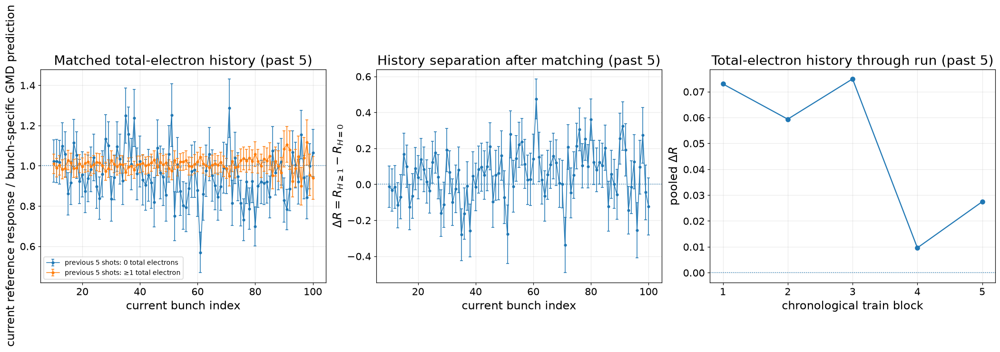

Overall matched H=0 response (past 5):   0.9580
Overall matched H>=1 response (past 5):  1.0070
Overall matched ΔR (past 5):             +0.0490 ± 0.0139
Effective matched shots per group: 461,930
Block ΔR: [0.073  0.0594 0.0749 0.0096 0.0274]


In [19]:
# --- Matched total-electron history (past {HISTORY_SHOTS}): H=0 vs H>=1 ---

N_TIME_BLOCKS = 5
MATCH_GMD_STEP = 1.0
MIN_PER_GROUP = 5

# Use actual train ordering for chronological blocks.
order = np.argsort(train_ids)
block_id = np.empty(gmd.shape[0],dtype=int)
for k,idx in enumerate(np.array_split(order,N_TIME_BLOCKS)): block_id[idx] = k

gmd_edges_match = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+MATCH_GMD_STEP,MATCH_GMD_STEP)

def matched_total_history_stats(blocks=None):
    if blocks is None: blocks = np.arange(N_TIME_BLOCKS)

    obs0 = np.zeros(n_bunch); pred0 = np.zeros(n_bunch); var0 = np.zeros(n_bunch)
    obs1 = np.zeros(n_bunch); pred1 = np.zeros(n_bunch); var1 = np.zeros(n_bunch)
    effective = np.zeros(n_bunch)

    for b in bunches_hist:
        base_valid = current_mask[:,b] & np.isfinite(H_total[:,b]) & np.isfinite(local_pred_cv[:,b]) & (local_pred_cv[:,b] > 0)

        for block in blocks:
            for lo,hi in zip(gmd_edges_match[:-1],gmd_edges_match[1:]):
                use = base_valid & (block_id == block) & (gmd[:,b] >= lo) & (gmd[:,b] < hi)
                idx0 = np.flatnonzero(use & (H_total[:,b] == 0))
                idx1 = np.flatnonzero(use & (H_total[:,b] >= 1))
                m = min(idx0.size,idx1.size)
                if m < MIN_PER_GROUP: continue

                w0,w1 = m/idx0.size,m/idx1.size
                y0 = data["ref_counts"][idx0,b].astype(float)
                y1 = data["ref_counts"][idx1,b].astype(float)

                obs0[b] += w0*y0.sum(); pred0[b] += w0*local_pred_cv[idx0,b].sum(); var0[b] += w0**2*y0.sum()
                obs1[b] += w1*y1.sum(); pred1[b] += w1*local_pred_cv[idx1,b].sum(); var1[b] += w1**2*y1.sum()
                effective[b] += m

    R0 = np.divide(obs0,pred0,out=np.full(n_bunch,np.nan),where=pred0 > 0)
    R1 = np.divide(obs1,pred1,out=np.full(n_bunch,np.nan),where=pred1 > 0)
    E0 = np.divide(np.sqrt(var0),pred0,out=np.full(n_bunch,np.nan),where=pred0 > 0)
    E1 = np.divide(np.sqrt(var1),pred1,out=np.full(n_bunch,np.nan),where=pred1 > 0)

    pooled0 = obs0.sum()/pred0.sum()
    pooled1 = obs1.sum()/pred1.sum()
    pooled_e0 = np.sqrt(var0.sum())/pred0.sum()
    pooled_e1 = np.sqrt(var1.sum())/pred1.sum()

    return {"R0":R0,"R1":R1,"E0":E0,"E1":E1,"delta":R1-R0,"delta_err":np.sqrt(E0**2+E1**2),"effective":effective,
            "pooled0":pooled0,"pooled1":pooled1,"pooled_delta":pooled1-pooled0,"pooled_delta_err":np.sqrt(pooled_e0**2+pooled_e1**2)}

matched_total = matched_total_history_stats()

block_delta = []
for block in range(N_TIME_BLOCKS): block_delta.append(matched_total_history_stats([block])["pooled_delta"])

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)

axes[0].errorbar(bunches_hist,matched_total["R0"][bunches_hist],yerr=matched_total["E0"][bunches_hist],fmt="o-",ms=3,lw=1,capsize=2,label=f"previous {HISTORY_SHOTS} shots: 0 total electrons")
axes[0].errorbar(bunches_hist,matched_total["R1"][bunches_hist],yerr=matched_total["E1"][bunches_hist],fmt="o-",ms=3,lw=1,capsize=2,label=f"previous {HISTORY_SHOTS} shots: ≥1 total electron")
axes[0].axhline(1,ls=":",lw=1)
axes[0].set(xlabel="current bunch index",ylabel="current reference response / bunch-specific GMD prediction",title=f"Matched total-electron history (past {HISTORY_SHOTS})")
axes[0].grid(alpha=0.25); axes[0].legend(fontsize=9)

axes[1].errorbar(bunches_hist,matched_total["delta"][bunches_hist],yerr=matched_total["delta_err"][bunches_hist],fmt="o-",ms=3,lw=1,capsize=2)
axes[1].axhline(0,ls=":",lw=1)
axes[1].set(xlabel="current bunch index",ylabel=r"$\Delta R=R_{H\geq1}-R_{H=0}$",title=f"History separation after matching (past {HISTORY_SHOTS})")
axes[1].grid(alpha=0.25)

axes[2].plot(np.arange(1,N_TIME_BLOCKS+1),block_delta,"o-")
axes[2].axhline(0,ls=":",lw=1)
axes[2].set_xticks(np.arange(1,N_TIME_BLOCKS+1))
axes[2].set(xlabel="chronological train block",ylabel=r"pooled $\Delta R$",title=f"Total-electron history through run (past {HISTORY_SHOTS})")
axes[2].grid(alpha=0.25)

plt.show()

print(f"Overall matched H=0 response (past {HISTORY_SHOTS}):   {matched_total['pooled0']:.4f}")
print(f"Overall matched H>=1 response (past {HISTORY_SHOTS}):  {matched_total['pooled1']:.4f}")
print(f"Overall matched ΔR (past {HISTORY_SHOTS}):             {matched_total['pooled_delta']:+.4f} ± {matched_total['pooled_delta_err']:.4f}")
print(f"Effective matched shots per group: {matched_total['effective'].sum():,.0f}")
print("Block ΔR:",np.round(block_delta,4))

#### Does the original slope survive with zero recent total-electron history?
The three panels compare all shots, zero previous-five total counts, and at least one previous electron. x is bunch position; y is relative **target** yield using the original GMD normalisation, not the bunch-specific baseline. A substantial negative slope in the zero-history population means recent detected-electron history cannot by itself explain the original bunch dependence. Zero detected counts do not rule out undetected charge.

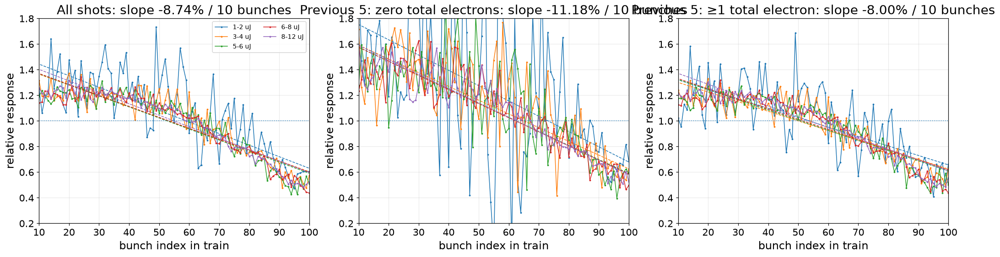

All shots (H past 5): flatness=0.24765, slope=-8.740% / 10 bunches
H=0 (past 5):        flatness=0.37540, slope=-11.179% / 10 bunches
H>=1 (past 5):       flatness=0.21927, slope=-8.005% / 10 bunches
Mean H=0 (past 5) fraction over analysed bunches: 18.0%


In [20]:
# --- Does the original bunch-position dependence survive with zero recent total-electron history? ---

mask_all = current_mask & np.isfinite(H_total)
mask_H0 = mask_all & (H_total == 0)
mask_H1 = mask_all & (H_total >= 1)

def history_subset_metric(mask):
    obs = band_sums(data["target_counts"], gmd, mask)
    norm = band_sums(gmd, gmd, mask)
    shots = band_sums(np.ones_like(gmd), gmd, mask)
    return bunch_metrics(obs, norm, shots)

metric_all = history_subset_metric(mask_all)
metric_H0 = history_subset_metric(mask_H0)
metric_H1 = history_subset_metric(mask_H1)

# Dynamic labels based on HISTORY_SHOTS
labels = [
    "All shots",
    f"Previous {HISTORY_SHOTS}: zero total electrons",
    f"Previous {HISTORY_SHOTS}: ≥1 total electron"
]

fig, axes = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)

for ax, name, m in zip(axes, labels, [metric_all, metric_H0, metric_H1]):
    plot_bunch_response(m, f"{name}: slope {m['slope']:+.2f}% / 10 bunches", ax)
    ax.set_ylim(0.2, 1.8)

axes[0].legend(ncol=2, fontsize=9)
plt.show()

# Print logs with dynamic references
print(f"All shots (H past {HISTORY_SHOTS}): flatness={metric_all['flatness']:.5f}, slope={metric_all['slope']:+.3f}% / 10 bunches")
print(f"H=0 (past {HISTORY_SHOTS}):        flatness={metric_H0['flatness']:.5f}, slope={metric_H0['slope']:+.3f}% / 10 bunches")
print(f"H>=1 (past {HISTORY_SHOTS}):       flatness={metric_H1['flatness']:.5f}, slope={metric_H1['slope']:+.3f}% / 10 bunches")
print(f"Mean H=0 (past {HISTORY_SHOTS}) fraction over analysed bunches: {np.mean([np.mean(mask_H0[:,b][mask_all[:,b]]) if np.any(mask_all[:,b]) else np.nan for b in bunches_hist]):.1%}")

### Improving the investigations between history and bunch position

#### Identical bunch support

,all slope,zero-history slope,nonzero-history slope,zero shots,zero fraction,median zero shots / bunch,minimum zero shots / bunch
window,,,,,,,
1,-11.24456,-11.24149,-11.23484,314952,0.74478,3050.0,1902
2,-11.24456,-10.58373,-11.75375,239384,0.56608,2187.0,1227
3,-11.24456,-10.61052,-12.02282,185330,0.43826,1526.0,770
5,-11.24456,-12.16812,-11.03313,115717,0.27364,752.0,324


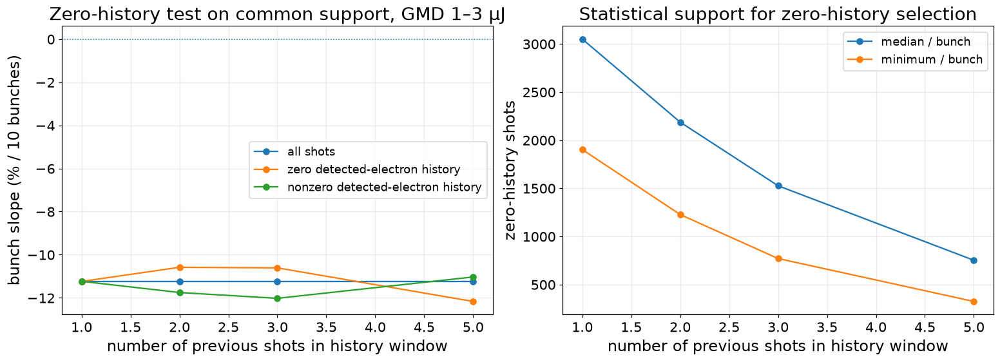

In [21]:
# --- Zero-history window scan with identical bunch and GMD support for every window ---

WINDOWS = [1,2,3,5]
COMMON_BUNCH_START = max(20,max(WINDOWS))
GMD_TEST_RANGE = (1.0,3.0)

ref_counts = data["ref_counts"].astype(float)
total_electrons = data["total_electrons"].astype(float)
n_trains,n_bunch = gmd.shape

cum_e = np.concatenate((np.zeros((n_trains,1)),np.cumsum(total_electrons,axis=1)),axis=1)
bunches = np.arange(COMMON_BUNCH_START,n_bunch)

def history_curve(window,mode):
    response = np.full(n_bunch,np.nan)
    counts = np.zeros(n_bunch,dtype=int)

    for b in bunches:
        h = cum_e[:,b]-cum_e[:,b-window]
        sel = current_mask[:,b] & np.isfinite(gmd[:,b]) & (gmd[:,b] >= GMD_TEST_RANGE[0]) & (gmd[:,b] < GMD_TEST_RANGE[1])
        if mode == "zero": sel &= h == 0
        elif mode == "nonzero": sel &= h > 0

        counts[b] = sel.sum()
        if counts[b] > 0 and gmd[sel,b].sum() > 0: response[b] = ref_counts[sel,b].sum()/gmd[sel,b].sum()

    use = np.isfinite(response[bunches])
    x = bunches[use]
    y = response[bunches][use]
    y = y/np.nanmean(y)
    slope = np.polyfit(x,y,1)[0]*1000 if y.size >= 2 else np.nan  # % / 10 bunches
    return response,counts,slope

rows = []
for w in WINDOWS:
    _,n_all,s_all = history_curve(w,"all")
    _,n_zero,s_zero = history_curve(w,"zero")
    _,n_nonzero,s_nonzero = history_curve(w,"nonzero")
    nz = n_zero[bunches]
    nnz = n_nonzero[bunches]
    rows.append({"window":w,"all slope":s_all,"zero-history slope":s_zero,"nonzero-history slope":s_nonzero,
                 "zero shots":nz.sum(),"zero fraction":nz.sum()/(nz.sum()+nnz.sum()),
                 "median zero shots / bunch":np.median(nz),"minimum zero shots / bunch":np.min(nz)})

zero_window_table = pd.DataFrame(rows).set_index("window")
display(zero_window_table.round(5))

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

axes[0].plot(WINDOWS,zero_window_table["all slope"],"o-",label="all shots")
axes[0].plot(WINDOWS,zero_window_table["zero-history slope"],"o-",label="zero detected-electron history")
axes[0].plot(WINDOWS,zero_window_table["nonzero-history slope"],"o-",label="nonzero detected-electron history")
axes[0].axhline(0,ls=":",lw=1)
axes[0].set_xlabel("number of previous shots in history window")
axes[0].set_ylabel("bunch slope (% / 10 bunches)")
axes[0].set_title(f"Zero-history test on common support, GMD {GMD_TEST_RANGE[0]:.0f}–{GMD_TEST_RANGE[1]:.0f} μJ")
axes[0].grid(alpha=0.25); axes[0].legend()

axes[1].plot(WINDOWS,zero_window_table["median zero shots / bunch"],"o-",label="median / bunch")
axes[1].plot(WINDOWS,zero_window_table["minimum zero shots / bunch"],"o-",label="minimum / bunch")
axes[1].set_xlabel("number of previous shots in history window")
axes[1].set_ylabel("zero-history shots")
axes[1].set_title("Statistical support for zero-history selection")
axes[1].grid(alpha=0.25); axes[1].legend()

plt.show()

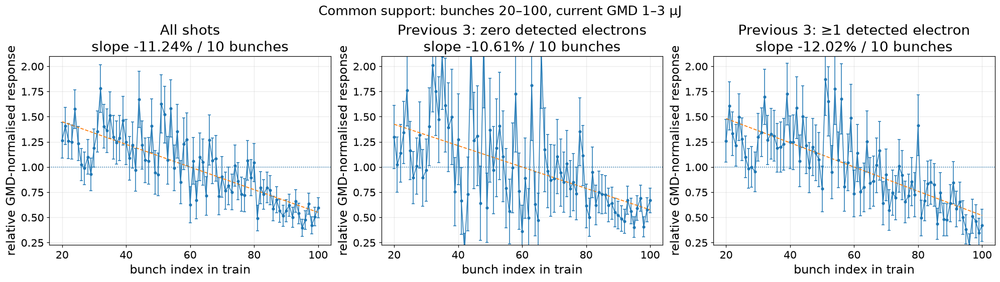

all     : total=422,880, median/bunch=4381, minimum/bunch=2,994
zero    : total=185,330, median/bunch=1526, minimum/bunch=770
nonzero : total=237,550, median/bunch=2720, minimum/bunch=2,126


In [22]:
# --- All / zero-history / nonzero-history bunch curves on identical support ---

HISTORY_SHOTS_PANEL = 3
PANEL_BUNCH_START = 20
PANEL_GMD_RANGE = (1.0,3.0)

if HISTORY_SHOTS_PANEL > PANEL_BUNCH_START:
    raise ValueError("HISTORY_SHOTS_PANEL must not exceed PANEL_BUNCH_START for common support.")

total_electrons = data["total_electrons"].astype(float)
ref_counts = data["ref_counts"].astype(float)

cum_e = np.concatenate((np.zeros((n_trains,1)),np.cumsum(total_electrons,axis=1)),axis=1)
bunches_panel = np.arange(PANEL_BUNCH_START,n_bunch)

def panel_curve(mode):
    response = np.full(n_bunch,np.nan)
    error = np.full(n_bunch,np.nan)
    shots = np.zeros(n_bunch,dtype=int)

    for b in bunches_panel:
        H = cum_e[:,b]-cum_e[:,b-HISTORY_SHOTS_PANEL]
        sel = current_mask[:,b] & (gmd[:,b] >= PANEL_GMD_RANGE[0]) & (gmd[:,b] < PANEL_GMD_RANGE[1])

        if mode == "zero": sel &= H == 0
        elif mode == "nonzero": sel &= H > 0

        shots[b] = sel.sum()
        obs = ref_counts[sel,b].sum()
        norm = gmd[sel,b].sum()

        if norm > 0:
            response[b] = obs/norm
            error[b] = np.sqrt(obs)/norm

    use = np.isfinite(response[bunches_panel])
    mean_response = np.nanmean(response[bunches_panel][use])
    relative = response/mean_response
    relative_error = error/mean_response

    x = bunches_panel[use]
    y = relative[bunches_panel][use]
    slope = np.polyfit(x,y,1)[0]*1000 if y.size >= 2 else np.nan
    intercept = np.polyfit(x,y,1)[1] if y.size >= 2 else np.nan

    return relative,relative_error,shots,slope,intercept

results_panel = {mode:panel_curve(mode) for mode in ["all","zero","nonzero"]}

titles = {
    "all":"All shots",
    "zero":f"Previous {HISTORY_SHOTS_PANEL}: zero detected electrons",
    "nonzero":f"Previous {HISTORY_SHOTS_PANEL}: ≥1 detected electron"
}

fig,axes = plt.subplots(1,3,figsize=(18,5),constrained_layout=True)

for ax,mode in zip(axes,["all","zero","nonzero"]):
    response,error,shots,slope,intercept = results_panel[mode]
    valid = np.isfinite(response[bunches_panel])

    ax.errorbar(bunches_panel[valid],response[bunches_panel][valid],
                yerr=error[bunches_panel][valid],fmt="o-",ms=3,lw=1,capsize=2)

    xfit = np.array([PANEL_BUNCH_START,n_bunch-1])
    ax.plot(xfit,intercept+(slope/1000)*xfit,"--",lw=1.2)

    ax.axhline(1,ls=":",lw=1)
    ax.set_xlabel("bunch index in train")
    ax.set_ylabel("relative GMD-normalised response")
    ax.set_title(f"{titles[mode]}\nslope {slope:+.2f}% / 10 bunches")
    ax.grid(alpha=0.25)

# Synchronize all y-axes to match the first subplot's view limits
ylim0 = axes[0].get_ylim()
for ax in axes: ax.set_ylim(ylim0)

fig.suptitle(f"Common support: bunches {PANEL_BUNCH_START}–{n_bunch-1}, current GMD {PANEL_GMD_RANGE[0]:g}–{PANEL_GMD_RANGE[1]:g} µJ")
plt.show()

for mode in ["all","zero","nonzero"]:
    shots = results_panel[mode][2][bunches_panel]
    print(f"{mode:8s}: total={shots.sum():,}, median/bunch={np.median(shots):.0f}, minimum/bunch={shots.min():,}")

,all slope,all SD,zero-history slope,zero SD,zero 95% low,zero 95% high,nonzero-history slope,nonzero SD
window,,,,,,,,
1,-11.2446,0.7237,-11.2415,0.8365,-12.9569,-9.7554,-11.2348,1.5032
2,-11.2446,0.7237,-10.5837,0.9968,-12.5215,-8.6640,-11.7538,1.0982
3,-11.2446,0.7237,-10.6105,1.2463,-13.2006,-8.3063,-12.0228,0.9948
5,-11.2446,0.7237,-12.1681,1.5378,-15.1982,-9.0209,-11.0331,0.8824


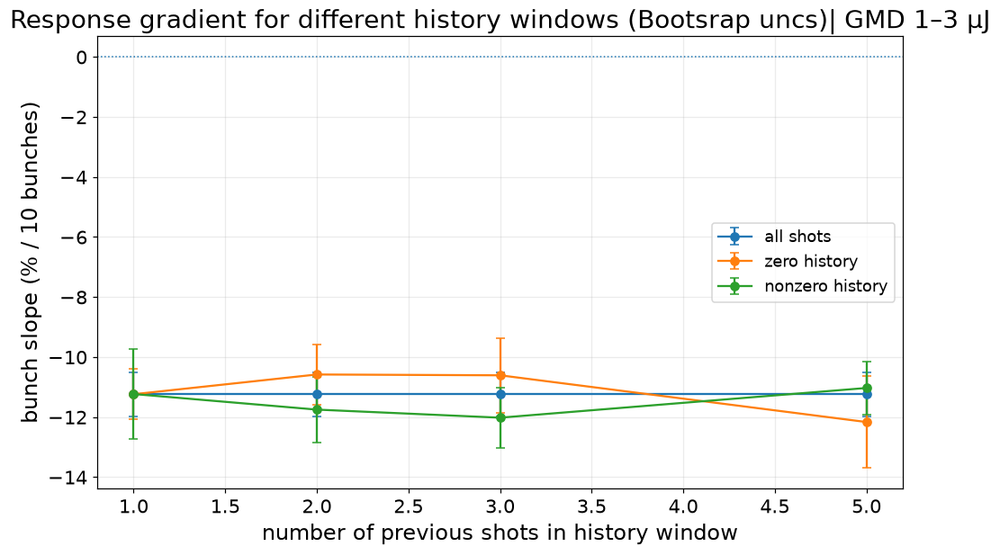

In [23]:
# --- Whole-train bootstrap uncertainties for the common-support zero-history scan ---

WINDOWS = [1,2,3,5]
COMMON_BUNCH_START = 20
GMD_TEST_RANGE = (1.0,3.0)
N_BOOT = 200
BOOT_SEED = 12345

rng = np.random.default_rng(BOOT_SEED)
bunches_boot = np.arange(COMMON_BUNCH_START,n_bunch)

def build_train_contributions(window,mode):
    num = np.zeros((n_trains,len(bunches_boot)),dtype=np.float32)
    den = np.zeros_like(num)

    for j,b in enumerate(bunches_boot):
        H = cum_e[:,b]-cum_e[:,b-window]
        sel = current_mask[:,b] & (gmd[:,b] >= GMD_TEST_RANGE[0]) & (gmd[:,b] < GMD_TEST_RANGE[1])

        if mode == "zero": sel &= H == 0
        elif mode == "nonzero": sel &= H > 0

        num[sel,j] = ref_counts[sel,b]
        den[sel,j] = gmd[sel,b]

    return num,den

def slope_from_sums(num_sum,den_sum):
    response = np.divide(num_sum,den_sum,out=np.full_like(num_sum,np.nan,dtype=float),where=den_sum > 0)
    valid = np.isfinite(response)
    if valid.sum() < 2: return np.nan
    y = response[valid]/np.nanmean(response[valid])
    x = bunches_boot[valid]
    return np.polyfit(x,y,1)[0]*1000

def bootstrap_slopes(num,den,n_boot=N_BOOT):
    slopes = np.full(n_boot,np.nan)

    for ib in range(n_boot):
        sampled = rng.integers(0,n_trains,n_trains)
        weights = np.bincount(sampled,minlength=n_trains).astype(np.float32)
        num_sum = weights @ num
        den_sum = weights @ den
        slopes[ib] = slope_from_sums(num_sum,den_sum)

    return slopes

boot_rows = []

# All-shot slope needs calculating only once because support is identical.
num_all,den_all = build_train_contributions(WINDOWS[0],"all")
all_nominal = slope_from_sums(num_all.sum(axis=0),den_all.sum(axis=0))
all_boot = bootstrap_slopes(num_all,den_all)

for window in WINDOWS:
    num_zero,den_zero = build_train_contributions(window,"zero")
    num_nonzero,den_nonzero = build_train_contributions(window,"nonzero")

    zero_nominal = slope_from_sums(num_zero.sum(axis=0),den_zero.sum(axis=0))
    nonzero_nominal = slope_from_sums(num_nonzero.sum(axis=0),den_nonzero.sum(axis=0))

    zero_boot = bootstrap_slopes(num_zero,den_zero)
    nonzero_boot = bootstrap_slopes(num_nonzero,den_nonzero)

    boot_rows.append({
        "window":window,
        "all slope":all_nominal,
        "all SD":np.nanstd(all_boot,ddof=1),
        "zero-history slope":zero_nominal,
        "zero SD":np.nanstd(zero_boot,ddof=1),
        "zero 95% low":np.nanpercentile(zero_boot,2.5),
        "zero 95% high":np.nanpercentile(zero_boot,97.5),
        "nonzero-history slope":nonzero_nominal,
        "nonzero SD":np.nanstd(nonzero_boot,ddof=1)
    })

bootstrap_table = pd.DataFrame(boot_rows).set_index("window")
display(bootstrap_table.round(4))

fig,ax = plt.subplots(figsize=(9,5.5),constrained_layout=True)

ax.errorbar(WINDOWS,bootstrap_table["all slope"],
            yerr=bootstrap_table["all SD"],fmt="o-",capsize=3,label="all shots")

ax.errorbar(WINDOWS,bootstrap_table["zero-history slope"],
            yerr=bootstrap_table["zero SD"],fmt="o-",capsize=3,label="zero history")

ax.errorbar(WINDOWS,bootstrap_table["nonzero-history slope"],
            yerr=bootstrap_table["nonzero SD"],fmt="o-",capsize=3,label="nonzero history")

ax.axhline(0,ls=":",lw=1)
ax.set_xlabel("number of previous shots in history window")
ax.set_ylabel("bunch slope (% / 10 bunches)")
ax.set_title(f"Response gradient for different history windows (Bootsrap uncs)| GMD {GMD_TEST_RANGE[0]:g}–{GMD_TEST_RANGE[1]:g} µJ")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

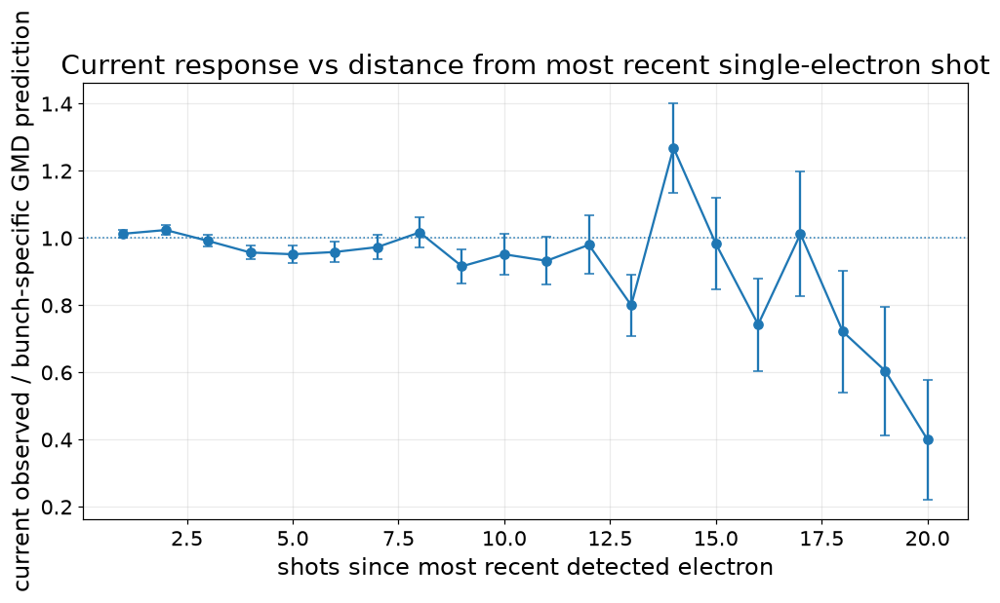

,response,counting error,shots
lag,,,
1,1.01242,0.01090,467607
2,1.02350,0.01373,309273
3,0.99116,0.01677,208921
4,0.95655,0.02037,143224
5,0.95136,0.02481,100607
6,0.95813,0.03021,71924
7,0.97255,0.03676,51952
8,1.01640,0.04501,38224
9,0.91552,0.05078,28578


In [26]:
# --- Current response versus time since most recent single-electron shot ---

MAX_LOOKBACK = 20

sum_obs = np.zeros(MAX_LOOKBACK+1)
sum_pred = np.zeros(MAX_LOOKBACK+1)
n_hits = np.zeros(MAX_LOOKBACK+1,dtype=int)

for b in range(MAX_LOOKBACK,n_bunch):
    history = total_electrons[:,b-MAX_LOOKBACK:b]

    # Search backwards: lag 1 is immediately preceding shot.
    reversed_history = history[:,::-1]
    has_hit = np.any(reversed_history > 0,axis=1)
    first_hit_index = np.argmax(reversed_history > 0,axis=1)
    lag = first_hit_index+1

    rows = np.flatnonzero(has_hit & current_mask[:,b] & np.isfinite(ref_base_cv[:,b]) & (ref_base_cv[:,b] > 0))

    for d in range(1,MAX_LOOKBACK+1):
        selected = rows[lag[rows] == d]
        if selected.size == 0: continue

        # Require the most recent hit shot itself to contain exactly one electron.
        previous_counts = total_electrons[selected,b-d]
        selected = selected[previous_counts == 1]
        if selected.size == 0: continue

        sum_obs[d] += data["ref_counts"][selected,b].sum()
        sum_pred[d] += ref_base_cv[selected,b].sum()
        n_hits[d] += selected.size

response = np.divide(sum_obs,sum_pred,out=np.full_like(sum_obs,np.nan),where=sum_pred > 0)
error = np.divide(np.sqrt(sum_obs),sum_pred,out=np.full_like(sum_obs,np.nan),where=sum_pred > 0)

lags = np.arange(1,MAX_LOOKBACK+1)

fig,ax = plt.subplots(figsize=(9,5),constrained_layout=True)
ax.errorbar(lags,response[1:],yerr=error[1:],fmt="o-",capsize=3)
ax.axhline(1,ls=":",lw=1)
ax.set_xlabel("shots since most recent detected electron")
ax.set_ylabel("current observed / bunch-specific GMD prediction")
ax.set_title("Current response vs distance from most recent single-electron shot")
ax.grid(alpha=0.25)
plt.show()

display(pd.DataFrame({
    "lag":lags,
    "response":response[1:],
    "counting error":error[1:],
    "shots":n_hits[1:]
}).set_index("lag").round(5))

### 7.3 Direct dose-response
Does increasing recent detected-electron load suppress the current response? x is **all detected electrons in the previous five shots**, in the retained discrete bins; y is current **190–220 eV reference yield divided by the bunch-specific current-GMD prediction**. Falling response supports saturation; rising response indicates positive persistence, opposite to simple saturation. This pooled plot is descriptive: unlike the matched tests, it does not additionally balance chronological blocks and GMD bins between history groups.

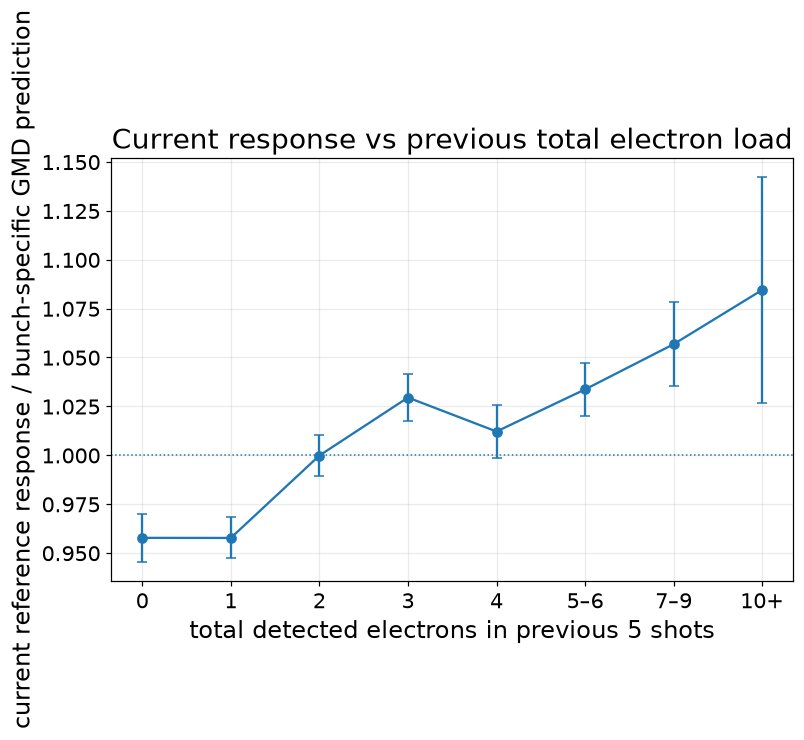

history   0: response=0.9577 ± 0.0124, shots=470,001
history   1: response=0.9577 ± 0.0105, shots=548,703
history   2: response=0.9998 ± 0.0107, shots=509,826
history   3: response=1.0295 ± 0.0119, shots=401,668
history   4: response=1.0121 ± 0.0137, shots=283,962
history 5–6: response=1.0337 ± 0.0134, shots=293,651
history 7–9: response=1.0568 ± 0.0214, shots=112,509
history 10+: response=1.0845 ± 0.0577, shots=15,395


In [27]:
# --- Direct dose-response to total detected-electron history ---

HISTORY_SHOTS = 5
H_total = np.full_like(gmd,np.nan,dtype=float)
for b in range(HISTORY_SHOTS,n_bunch): H_total[:,b] = data["total_electrons"][:,b-HISTORY_SHOTS:b].sum(axis=1)

# Bins chosen from the observed total-history distribution.
HISTORY_BINS = [(0,0),(1,1),(2,2),(3,3),(4,4),(5,6),(7,9),(10,np.inf)]
labels = ["0","1","2","3","4","5–6","7–9","10+"]

response,response_err,n_shots = [],[],[]
valid_base = current_mask & np.isfinite(H_total) & np.isfinite(local_pred_cv) & (local_pred_cv > 0)

for lo,hi in HISTORY_BINS:
    use = valid_base & (H_total >= lo) & (H_total <= hi)
    obs = data["ref_counts"][use].sum()
    pred = local_pred_cv[use].sum()
    response.append(obs/pred if pred > 0 else np.nan)
    response_err.append(np.sqrt(obs)/pred if obs > 0 and pred > 0 else np.nan)
    n_shots.append(np.count_nonzero(use))

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(np.arange(len(labels)),response,yerr=response_err,fmt="o-",capsize=3)
ax.axhline(1,ls=":",lw=1)
ax.set_xticks(np.arange(len(labels)),labels)
ax.set(xlabel=f"total detected electrons in previous {HISTORY_SHOTS} shots",ylabel="current reference response / bunch-specific GMD prediction",title="Current response vs previous total electron load")
ax.grid(alpha=0.25)
plt.show()

for label,r,e,n in zip(labels,response,response_err,n_shots): print(f"history {label:>3s}: response={r:.4f} ± {e:.4f}, shots={n:,}")

### 7.4 Cumulative total-electron history
How does recorded load accumulate? In the descriptive plot, x is current bunch position and y is total detected electrons in all earlier shots of the same train. Rising load is expected as more shots precede the current one; it is not evidence that load causes the bunch-position loss.

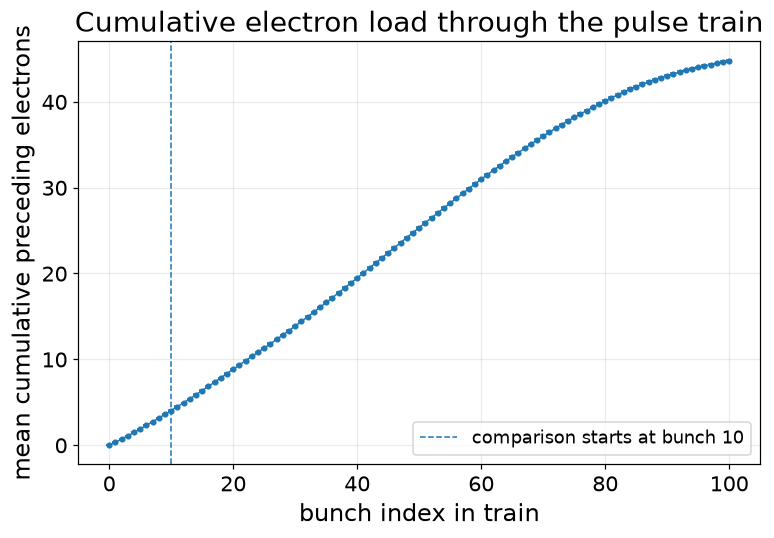

In [28]:
# --- Cumulative detected-electron load: all earlier shots in the same train ---

def cumulative_electron_history(total_electrons):
    C = np.zeros(total_electrons.shape,dtype=float)
    C[:,1:] = np.cumsum(total_electrons[:,:-1],axis=1)
    return C

C_e = cumulative_electron_history(data["total_electrons"])
bunch = np.arange(n_bunch)

mean_C = C_e.mean(axis=0)
sem_C = C_e.std(axis=0,ddof=1)/np.sqrt(C_e.shape[0])

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(bunch,mean_C,yerr=sem_C,fmt="o-",ms=3,lw=1,capsize=2)
ax.axvline(INDEP_BUNCH_START,ls="--",lw=1,label=f"comparison starts at bunch {INDEP_BUNCH_START}")
ax.set(xlabel="bunch index in train",ylabel="mean cumulative preceding electrons",title="Cumulative electron load through the pulse train")
ax.grid(alpha=0.25); ax.legend(); plt.show()

#### Matched cumulative load
At fixed current bunch position, chronological block and current GMD bin, compare low/high cumulative **total-electron** load. The first two panels use current bunch on x and observed/local-GMD-predicted reference yield or high-minus-low separation on y. High below low is consistent with cumulative suppression; high above low indicates positive train-level persistence. The third panel uses chronological block on x and pooled separation on y. A common sign across blocks supports a reproducible direction, although magnitudes may vary; it does not establish causality.

Retain 25% tails, five chronological blocks, 0.5 µJ matching bins and minimum 20 shots per group. Tied cumulative counts are included at thresholds; strata with equal low/high thresholds are skipped, so there is no chronological tie-breaking split.

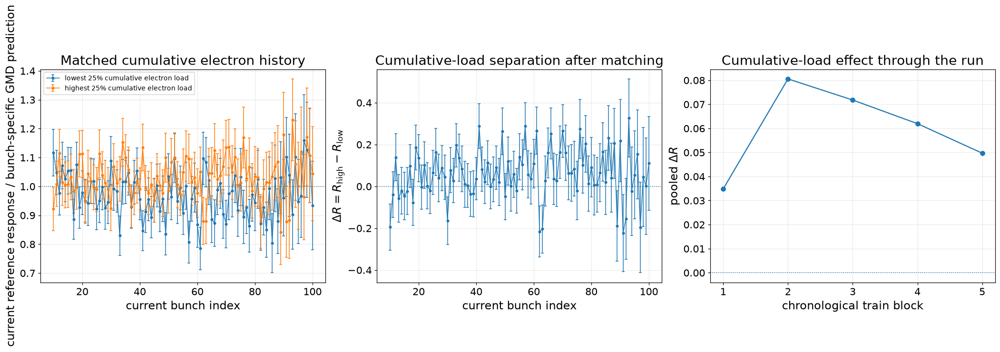

Matched low cumulative-load response:  0.9692
Matched high cumulative-load response: 1.0284
Overall cumulative-load ΔR:            +0.0592 ± 0.0128
Effective matched shots per group:     695,074
Block ΔR: [0.0348 0.0805 0.0718 0.0619 0.0497]


In [29]:
# --- Matched cumulative total-electron history ---
# At fixed current bunch, current GMD and time block, compare low vs high
# total detected-electron load accumulated since the start of the train.

CUM_QUANTILE = 0.25
N_TIME_BLOCKS = 5
MATCH_GMD_STEP = 0.5
MIN_PER_GROUP = 20

# C_total[:, b] = all detected electrons in shots 0 ... b-1 of the same train.
C_total = np.zeros_like(gmd,dtype=float)
C_total[:,1:] = np.cumsum(data["total_electrons"][:,:-1],axis=1)

# Chronological train blocks.
order = np.argsort(train_ids)
block_id = np.empty(gmd.shape[0],dtype=int)
for k,idx in enumerate(np.array_split(order,N_TIME_BLOCKS)): block_id[idx] = k

gmd_edges_match = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+MATCH_GMD_STEP,MATCH_GMD_STEP)
bunches_cum = np.arange(INDEP_BUNCH_START,n_bunch)

def matched_cumulative_stats(blocks=None):
    if blocks is None: blocks = np.arange(N_TIME_BLOCKS)

    obs_lo = np.zeros(n_bunch); pred_lo = np.zeros(n_bunch); var_lo = np.zeros(n_bunch)
    obs_hi = np.zeros(n_bunch); pred_hi = np.zeros(n_bunch); var_hi = np.zeros(n_bunch)
    effective = np.zeros(n_bunch)

    for b in bunches_cum:
        base_valid = current_mask[:,b] & np.isfinite(C_total[:,b]) & np.isfinite(local_pred_cv[:,b]) & (local_pred_cv[:,b] > 0)

        for block in blocks:
            for g_lo,g_hi in zip(gmd_edges_match[:-1],gmd_edges_match[1:]):
                idx = np.flatnonzero(base_valid & (block_id == block) & (gmd[:,b] >= g_lo) & (gmd[:,b] < g_hi))
                if idx.size < 2*MIN_PER_GROUP: continue

                C = C_total[idx,b]
                q_lo,q_hi = np.quantile(C,[CUM_QUANTILE,1-CUM_QUANTILE])
                if q_lo >= q_hi: continue

                idx_lo = idx[C <= q_lo]
                idx_hi = idx[C >= q_hi]
                m = min(idx_lo.size,idx_hi.size)
                if m < MIN_PER_GROUP: continue

                # Equal effective weight for low/high history inside each matched stratum.
                w_lo,w_hi = m/idx_lo.size,m/idx_hi.size
                y_lo = data["ref_counts"][idx_lo,b].astype(float)
                y_hi = data["ref_counts"][idx_hi,b].astype(float)

                obs_lo[b] += w_lo*y_lo.sum(); pred_lo[b] += w_lo*local_pred_cv[idx_lo,b].sum(); var_lo[b] += w_lo**2*y_lo.sum()
                obs_hi[b] += w_hi*y_hi.sum(); pred_hi[b] += w_hi*local_pred_cv[idx_hi,b].sum(); var_hi[b] += w_hi**2*y_hi.sum()
                effective[b] += m

    R_lo = np.divide(obs_lo,pred_lo,out=np.full(n_bunch,np.nan),where=pred_lo > 0)
    R_hi = np.divide(obs_hi,pred_hi,out=np.full(n_bunch,np.nan),where=pred_hi > 0)
    E_lo = np.divide(np.sqrt(var_lo),pred_lo,out=np.full(n_bunch,np.nan),where=pred_lo > 0)
    E_hi = np.divide(np.sqrt(var_hi),pred_hi,out=np.full(n_bunch,np.nan),where=pred_hi > 0)

    pooled_lo = obs_lo.sum()/pred_lo.sum()
    pooled_hi = obs_hi.sum()/pred_hi.sum()
    pooled_e_lo = np.sqrt(var_lo.sum())/pred_lo.sum()
    pooled_e_hi = np.sqrt(var_hi.sum())/pred_hi.sum()

    return {"R_lo":R_lo,"R_hi":R_hi,"E_lo":E_lo,"E_hi":E_hi,"delta":R_hi-R_lo,"delta_err":np.sqrt(E_lo**2+E_hi**2),
            "effective":effective,"pooled_lo":pooled_lo,"pooled_hi":pooled_hi,"pooled_delta":pooled_hi-pooled_lo,
            "pooled_delta_err":np.sqrt(pooled_e_lo**2+pooled_e_hi**2)}

cum_match = matched_cumulative_stats()

block_delta = []
for block in range(N_TIME_BLOCKS): block_delta.append(matched_cumulative_stats([block])["pooled_delta"])

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)

axes[0].errorbar(bunches_cum,cum_match["R_lo"][bunches_cum],yerr=cum_match["E_lo"][bunches_cum],fmt="o-",ms=3,lw=1,capsize=2,label="lowest 25% cumulative electron load")
axes[0].errorbar(bunches_cum,cum_match["R_hi"][bunches_cum],yerr=cum_match["E_hi"][bunches_cum],fmt="o-",ms=3,lw=1,capsize=2,label="highest 25% cumulative electron load")
axes[0].axhline(1,ls=":",lw=1)
axes[0].set(xlabel="current bunch index",ylabel="current reference response / bunch-specific GMD prediction",title="Matched cumulative electron history")
axes[0].grid(alpha=0.25); axes[0].legend(fontsize=9)

axes[1].errorbar(bunches_cum,cum_match["delta"][bunches_cum],yerr=cum_match["delta_err"][bunches_cum],fmt="o-",ms=3,lw=1,capsize=2)
axes[1].axhline(0,ls=":",lw=1)
axes[1].set(xlabel="current bunch index",ylabel=r"$\Delta R=R_{\rm high}-R_{\rm low}$",title="Cumulative-load separation after matching")
axes[1].grid(alpha=0.25)

axes[2].plot(np.arange(1,N_TIME_BLOCKS+1),block_delta,"o-")
axes[2].axhline(0,ls=":",lw=1)
axes[2].set_xticks(np.arange(1,N_TIME_BLOCKS+1))
axes[2].set(xlabel="chronological train block",ylabel=r"pooled $\Delta R$",title="Cumulative-load effect through the run")
axes[2].grid(alpha=0.25)

plt.show()

print(f"Matched low cumulative-load response:  {cum_match['pooled_lo']:.4f}")
print(f"Matched high cumulative-load response: {cum_match['pooled_hi']:.4f}")
print(f"Overall cumulative-load ΔR:            {cum_match['pooled_delta']:+.4f} ± {cum_match['pooled_delta_err']:.4f}")
print(f"Effective matched shots per group:     {cum_match['effective'].sum():,.0f}")
print("Block ΔR:",np.round(block_delta,4))

## 8. GMD nonlinearity through the pulse train
Does total-electron yield become sublinear at high GMD, and is that loss stronger at later bunch positions? In the two-row, five-panel figure, x is current GMD and y is mean **all detected electrons** per shot in 0.5 µJ bins. Fit a straight line to individual shots only in 1–4 µJ and extrapolate it to high GMD. Points are unsmoothed bin averages; the line is the fitted model, not interpolation.

The second figure uses current GMD on x and summed observed total counts/summed low-GMD linear predictions on y, within each bin. Ratio 1 is consistent with the low-GMD line; below 1 is sublinear and above 1 is superlinear relative to its extrapolation. Nonpositive predicted bins are omitted from the ratio. These are descriptive fits on the plotted population, not held-out model scores. Count-based bars exclude uncertainty in the fitted extrapolation.

Earlier inspected curves suggested high-GMD sublinearity without a simple monotonic increase with bunch position. Treat that as a prior observation to check in these new total-electron panels: it does not by itself explain the monotonic bunch-position loss.

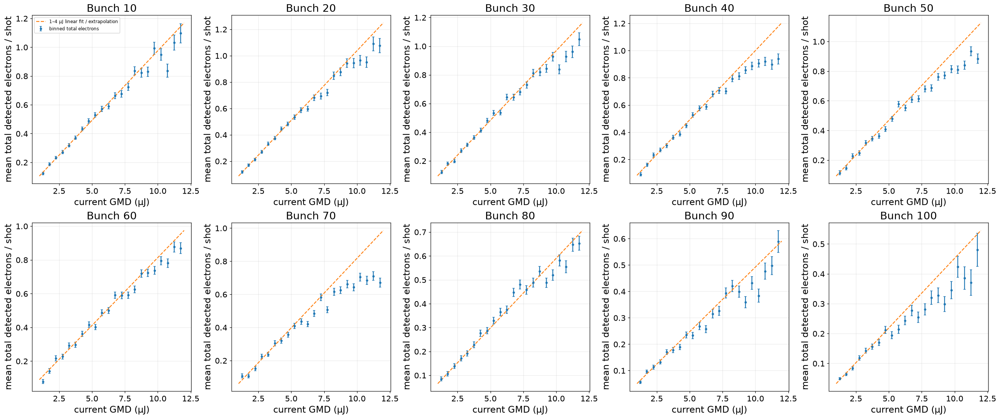

In [30]:
# --- Total detected-electron yield versus current GMD at representative bunch positions ---
GMD_BIN_WIDTH = 0.5
LOW_GMD_FIT_RANGE = (1.0,4.0)
BUNCH_POSITIONS = [10,20,30,40,50,60,70,80,90,100]
gmd_edges_nonlinear = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+GMD_BIN_WIDTH,GMD_BIN_WIDTH)
g_grid_nonlinear = np.linspace(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1],200)
nonlinearity_results = {}
fig,axes = plt.subplots(2,5,figsize=(24,10),constrained_layout=True)
for ax,bunch_pos in zip(axes.flat,BUNCH_POSITIONS):
    if bunch_pos >= n_bunch:
        ax.set_visible(False); print(f"Bunch {bunch_pos} absent in this dataset; panel skipped."); continue
    valid = current_mask[:,bunch_pos]
    g = gmd[valid,bunch_pos]
    y = data["total_electrons"][valid,bunch_pos].astype(float)
    fit_use = (g >= LOW_GMD_FIT_RANGE[0]) & (g < LOW_GMD_FIT_RANGE[1])
    if np.count_nonzero(fit_use) < 2 or np.unique(g[fit_use]).size < 2:
        ax.set_visible(False); print(f"Bunch {bunch_pos}: insufficient low-GMD fit support."); continue
    X = np.column_stack((np.ones(np.count_nonzero(fit_use)),g[fit_use]))
    beta_low = np.linalg.lstsq(X,y[fit_use],rcond=None)[0]
    gx,ym,ye,ratio,ratio_err,counts = [],[],[],[],[],[]
    for lo,hi in zip(gmd_edges_nonlinear[:-1],gmd_edges_nonlinear[1:]):
        use = (g >= lo) & (g < hi)
        if not np.any(use): continue
        observed = y[use].sum(); n = np.count_nonzero(use)
        predicted = (beta_low[0]+beta_low[1]*g[use]).sum()
        gx.append(g[use].mean()); ym.append(observed/n); ye.append(np.sqrt(observed)/n); counts.append(n)
        ratio.append(observed/predicted if predicted > 0 else np.nan)
        ratio_err.append(np.sqrt(observed)/predicted if predicted > 0 else np.nan)
    nonlinearity_results[bunch_pos] = dict(gmd=np.asarray(gx),mean=np.asarray(ym),error=np.asarray(ye),
                                          ratio=np.asarray(ratio),ratio_err=np.asarray(ratio_err),beta=beta_low,n=np.asarray(counts))
    ax.errorbar(gx,ym,yerr=ye,fmt="o",ms=3,capsize=2,label="binned total electrons")
    ax.plot(g_grid_nonlinear,beta_low[0]+beta_low[1]*g_grid_nonlinear,"--",lw=1.5,label="1–4 µJ linear fit / extrapolation")
    ax.set(xlabel="current GMD (µJ)",ylabel="mean total detected electrons / shot",title=f"Bunch {bunch_pos}")
    ax.grid(alpha=0.25)
axes[0,0].legend(fontsize=8)
plt.show()

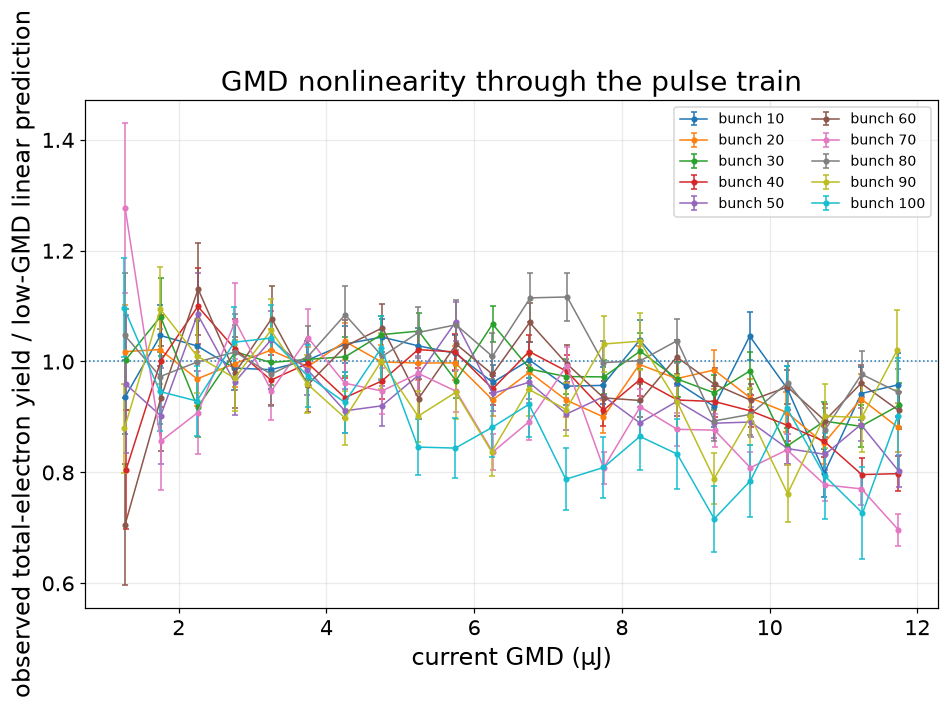

In [31]:
# --- GMD nonlinearity through the pulse train ---
fig,ax = plt.subplots(figsize=(10,6))
for bunch_pos,result in nonlinearity_results.items():
    ax.errorbar(result["gmd"],result["ratio"],yerr=result["ratio_err"],fmt="o-",ms=3,lw=1,capsize=2,label=f"bunch {bunch_pos}")
ax.axhline(1,ls=":",lw=1)
ax.set(xlabel="current GMD (µJ)",ylabel="observed total-electron yield / low-GMD linear prediction",title="GMD nonlinearity through the pulse train")
ax.grid(alpha=0.25); ax.legend(ncol=2,fontsize=9); plt.show()

## Investigating bunch dependence

### Bunch dependency by KE region

,slope (% / 10 bunches),flatness,total electrons
KE region,,,
180–200 eV,-9.23312,0.34398,25652
200–220 eV,-9.06891,0.30322,44293
220–240 eV,-8.63825,0.25696,140541
240–260 eV,-8.82004,0.25378,179885
260–270 eV,-9.01726,0.37840,19740
all detected,-8.95199,0.24388,1590825


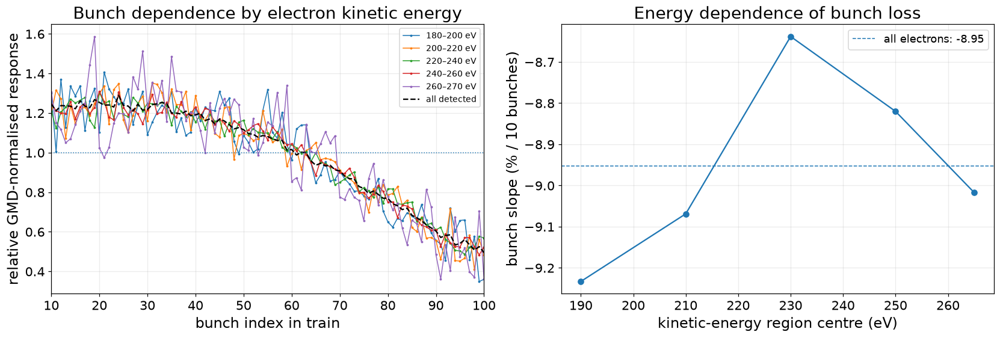

In [32]:
# --- Electron bunch dependence in separate kinetic-energy regions ---

KE_REGIONS = [(180,200),(200,220),(220,240),(240,260),(260,270)]

def load_electron_region_counts(path,regions,max_trains=None):
    counts = np.zeros((len(regions),n_trains,n_bunch),dtype=np.uint16)
    with h5py.File(path,"r") as handle:
        n_load = n_trains if max_trains is None else min(n_trains,int(max_trains))
        for start in range(0,n_load,INDEP_CHUNK_TRAINS):
            stop = min(start+INDEP_CHUNK_TRAINS,n_load)
            tof = handle["tofs_e"][start:stop]
            valid = tof > 0
            if not np.any(valid): continue
            ke = tof_to_ke(tof[valid])
            shot_index = np.flatnonzero(valid)//tof.shape[-1]
            for j,(lo,hi) in enumerate(regions):
                inside = (ke >= lo) & (ke < hi)
                counts[j,start:stop].flat[:] = np.bincount(shot_index[inside],minlength=(stop-start)*n_bunch)
    return counts

ke_region_counts = load_electron_region_counts(source_h5,KE_REGIONS,MAX_TRAINS)

def metrics_from_counts(counts):
    obs = band_sums(counts,gmd,current_mask)
    norm = band_sums(gmd,gmd,current_mask)
    shots = band_sums(np.ones_like(gmd),gmd,current_mask)
    return bunch_metrics(obs,norm,shots),shots

def combined_relative_profile(metrics,shots):
    r = metrics["relative"]
    valid = np.isfinite(r) & (shots > 0)
    num = np.sum(np.where(valid,r*shots,0),axis=0)
    den = np.sum(np.where(valid,shots,0),axis=0)
    return np.divide(num,den,out=np.full(n_bunch,np.nan),where=den > 0)

ke_rows = []
ke_profiles = {}

for j,(lo,hi) in enumerate(KE_REGIONS):
    m,shots = metrics_from_counts(ke_region_counts[j])
    ke_profiles[(lo,hi)] = combined_relative_profile(m,shots)
    ke_rows.append({"KE region":f"{lo:g}–{hi:g} eV","slope (% / 10 bunches)":m["slope"],"flatness":m["flatness"],
                    "total electrons":int(ke_region_counts[j].sum())})

m_total,shots_total = metrics_from_counts(data["total_electrons"])
total_profile = combined_relative_profile(m_total,shots_total)
ke_rows.append({"KE region":"all detected","slope (% / 10 bunches)":m_total["slope"],"flatness":m_total["flatness"],
                "total electrons":int(data["total_electrons"].sum())})

display(pd.DataFrame(ke_rows).set_index("KE region").round(5))

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)

for (lo,hi),profile in ke_profiles.items(): axes[0].plot(bunch,profile,".-",ms=3,lw=1,label=f"{lo:g}–{hi:g} eV")
axes[0].plot(bunch,total_profile,"k--",lw=1.5,label="all detected")
axes[0].axhline(1,ls=":",lw=1)
axes[0].set_xlim(INDEP_BUNCH_START,n_bunch-1)
axes[0].set(xlabel="bunch index in train",ylabel="relative GMD-normalised response",title="Bunch dependence by electron kinetic energy")
axes[0].grid(alpha=0.25); axes[0].legend(fontsize=9)

centres = [(lo+hi)/2 for lo,hi in KE_REGIONS]
slopes = [ke_rows[j]["slope (% / 10 bunches)"] for j in range(len(KE_REGIONS))]
axes[1].plot(centres,slopes,"o-")
axes[1].axhline(m_total["slope"],ls="--",lw=1,label=f"all electrons: {m_total['slope']:+.2f}")
axes[1].set(xlabel="kinetic-energy region centre (eV)",ylabel="bunch slope (% / 10 bunches)",title="Energy dependence of bunch loss")
axes[1].grid(alpha=0.25); axes[1].legend()

plt.show()

### Does the ion have the same dependence?

In [33]:
# --- Load total detected-ion counts per shot ---

def load_total_ion_counts(path,max_trains=None):
    ion_counts = np.zeros((n_trains,n_bunch),dtype=np.uint16)
    full_slots = 0
    with h5py.File(path,"r") as handle:
        n_load = n_trains if max_trains is None else min(n_trains,int(max_trains))
        n_slots = handle["tofs_i"].shape[-1]
        for start in range(0,n_load,INDEP_CHUNK_TRAINS):
            stop = min(start+INDEP_CHUNK_TRAINS,n_load)
            tof_i = handle["tofs_i"][start:stop]
            ion_counts[start:stop] = np.count_nonzero(tof_i > 0,axis=-1)
            full_slots += np.count_nonzero(ion_counts[start:stop] == n_slots)
    print(f"Ion shots at {n_slots}-hit storage ceiling: {full_slots:,}")
    return ion_counts

ion_counts = load_total_ion_counts(source_h5,MAX_TRAINS)

print(f"Mean ions / shot: {ion_counts.mean():.4f}")
print(f"Zero-ion fraction: {np.mean(ion_counts == 0):.1%}")
print(f"Maximum ions in one shot: {ion_counts.max()}")

KeyboardInterrupt: 

/tmp/ipykernel_3211535/3659327020.py:18: RuntimeWarning: Mean of empty slice
  return np.nanmean(slopes,axis=0),np.nanstd(slopes,axis=0,ddof=1)
/home/mmanresa/glycine26/.venv/lib64/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


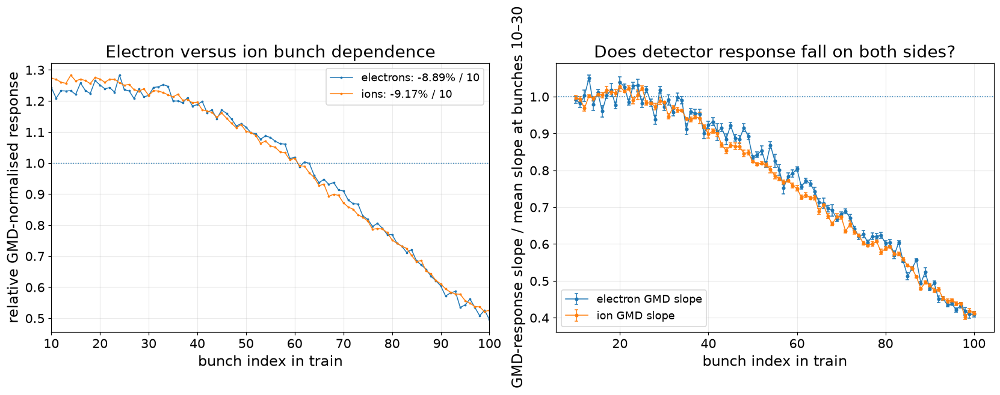

In [ ]:
# --- Electron versus ion bunch dependence ---

electron_metric,electron_shots = metrics_from_counts(data["total_electrons"])
ion_metric,ion_shots = metrics_from_counts(ion_counts)

electron_profile = combined_relative_profile(electron_metric,electron_shots)
ion_profile = combined_relative_profile(ion_metric,ion_shots)

def cv_local_gmd_slopes(counts):
    slopes = np.full((INDEP_CV_MOD,n_bunch),np.nan)
    for off in INDEP_CV_OFFSETS:
        train_rows = train_ids % INDEP_CV_MOD != off
        for b in range(INDEP_BUNCH_START,n_bunch):
            use = train_rows & current_mask[:,b]
            if np.count_nonzero(use) < 2: continue
            X = np.column_stack((np.ones(np.count_nonzero(use)),gmd[use,b]))
            slopes[off,b] = np.linalg.lstsq(X,counts[use,b].astype(float),rcond=None)[0][1]
    return np.nanmean(slopes,axis=0),np.nanstd(slopes,axis=0,ddof=1)

electron_slope,electron_slope_sd = cv_local_gmd_slopes(data["total_electrons"])
ion_slope,ion_slope_sd = cv_local_gmd_slopes(ion_counts)

NORM_BUNCH_RANGE = (10,30)
norm_sel = (bunch >= NORM_BUNCH_RANGE[0]) & (bunch <= NORM_BUNCH_RANGE[1])
electron_scale = np.nanmean(electron_slope[norm_sel])
ion_scale = np.nanmean(ion_slope[norm_sel])

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)

axes[0].plot(bunch,electron_profile,".-",ms=3,lw=1,label=f"electrons: {electron_metric['slope']:+.2f}% / 10")
axes[0].plot(bunch,ion_profile,".-",ms=3,lw=1,label=f"ions: {ion_metric['slope']:+.2f}% / 10")
axes[0].axhline(1,ls=":",lw=1)
axes[0].set_xlim(INDEP_BUNCH_START,n_bunch-1)
axes[0].set(xlabel="bunch index in train",ylabel="relative GMD-normalised response",title="Electron versus ion bunch dependence")
axes[0].grid(alpha=0.25); axes[0].legend()

axes[1].errorbar(bunches_local,electron_slope[bunches_local]/electron_scale,yerr=electron_slope_sd[bunches_local]/abs(electron_scale),fmt="o-",ms=3,lw=1,capsize=2,label="electron GMD slope")
axes[1].errorbar(bunches_local,ion_slope[bunches_local]/ion_scale,yerr=ion_slope_sd[bunches_local]/abs(ion_scale),fmt="o-",ms=3,lw=1,capsize=2,label="ion GMD slope")
axes[1].axhline(1,ls=":",lw=1)
axes[1].set(xlabel="bunch index in train",ylabel=f"GMD-response slope / mean slope at bunches {NORM_BUNCH_RANGE[0]}–{NORM_BUNCH_RANGE[1]}",title="Does detector response fall on both sides?")
axes[1].grid(alpha=0.25); axes[1].legend()

plt.show()



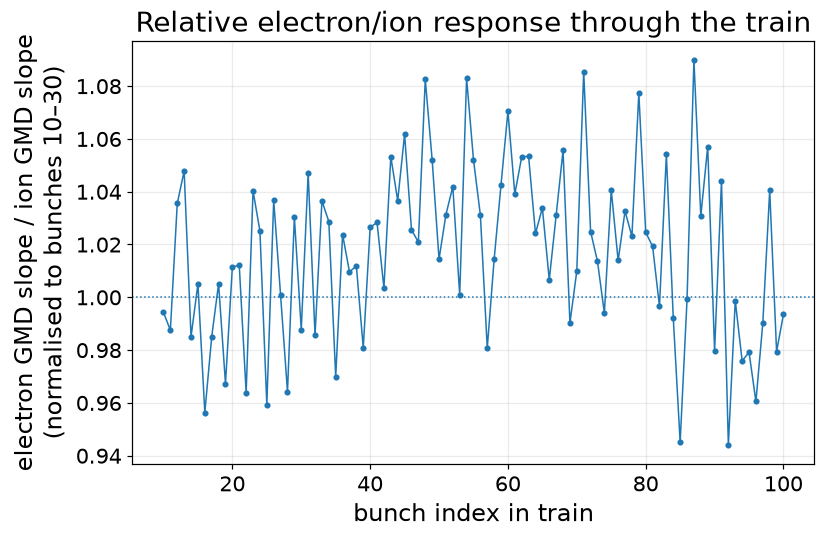

In [ ]:
# --- Does the electron/ion response ratio change through the train? ---

ei_ratio = electron_slope/ion_slope
norm = np.nanmean(ei_ratio[(bunch >= 10) & (bunch <= 30)])
ei_ratio_norm = ei_ratio/norm

fig,ax = plt.subplots(figsize=(8,5))
ax.plot(bunches_local,ei_ratio_norm[bunches_local],"o-",ms=3,lw=1)
ax.axhline(1,ls=":",lw=1)
ax.set(xlabel="bunch index in train",ylabel="electron GMD slope / ion GMD slope\n(normalised to bunches 10–30)",title="Relative electron/ion response through the train")
ax.grid(alpha=0.25)
plt.show()

### Does the e spectrum change along the train? ---

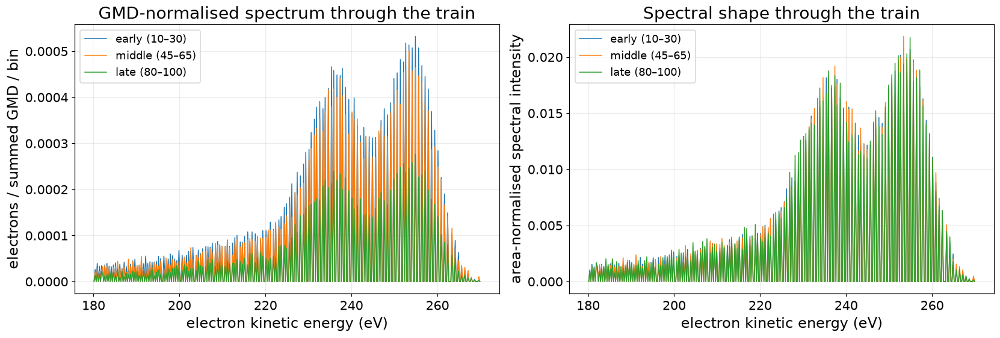

In [34]:
# --- Electron spectrum versus bunch position at fixed moderate GMD ---

SPECTRAL_GMD_RANGE = (3.0,6.0)
SPECTRAL_KE_EDGES = np.arange(180.0,270.25,0.25)
SPECTRAL_KE_CENTRES = 0.5*(SPECTRAL_KE_EDGES[:-1]+SPECTRAL_KE_EDGES[1:])
spectral_selected = current_mask & (gmd >= SPECTRAL_GMD_RANGE[0]) & (gmd < SPECTRAL_GMD_RANGE[1])

def load_ke_hist_by_bunch(path,selected):
    hist = np.zeros((n_bunch,len(SPECTRAL_KE_EDGES)-1),dtype=np.int64)
    with h5py.File(path,"r") as handle:
        for start in range(0,n_trains,INDEP_CHUNK_TRAINS):
            stop = min(start+INDEP_CHUNK_TRAINS,n_trains)
            tof = handle["tofs_e"][start:stop]
            valid = (tof > 0) & selected[start:stop,:,None]
            if not np.any(valid): continue
            flat = np.flatnonzero(valid)
            shot_index = flat//tof.shape[-1]
            bunch_index = shot_index % n_bunch
            ke = tof_to_ke(tof.reshape(-1)[flat])
            good = np.isfinite(ke)
            h,_,_ = np.histogram2d(bunch_index[good],ke[good],
                                   bins=[np.arange(-0.5,n_bunch+0.5,1),SPECTRAL_KE_EDGES])
            hist += h.astype(np.int64)
    return hist

ke_hist_bunch = load_ke_hist_by_bunch(source_h5,spectral_selected)
spectral_gmd_sum = np.sum(np.where(spectral_selected,gmd,0),axis=0)

BUNCH_GROUPS = {"early (10–30)":(10,30),"middle (45–65)":(45,65),"late (80–100)":(80,100)}

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)

for label,(lo,hi) in BUNCH_GROUPS.items():
    idx = np.arange(lo,hi+1)
    spectrum = ke_hist_bunch[idx].sum(axis=0)/spectral_gmd_sum[idx].sum()
    axes[0].plot(SPECTRAL_KE_CENTRES,spectrum,lw=1,label=label)
    area = spectrum.sum()
    axes[1].plot(SPECTRAL_KE_CENTRES,spectrum/area if area > 0 else spectrum,lw=1,label=label)

axes[0].set(xlabel="electron kinetic energy (eV)",ylabel="electrons / summed GMD / bin",title="GMD-normalised spectrum through the train")
axes[1].set(xlabel="electron kinetic energy (eV)",ylabel="area-normalised spectral intensity",title="Spectral shape through the train")
for ax in axes: ax.grid(alpha=0.25); ax.legend()
plt.show()

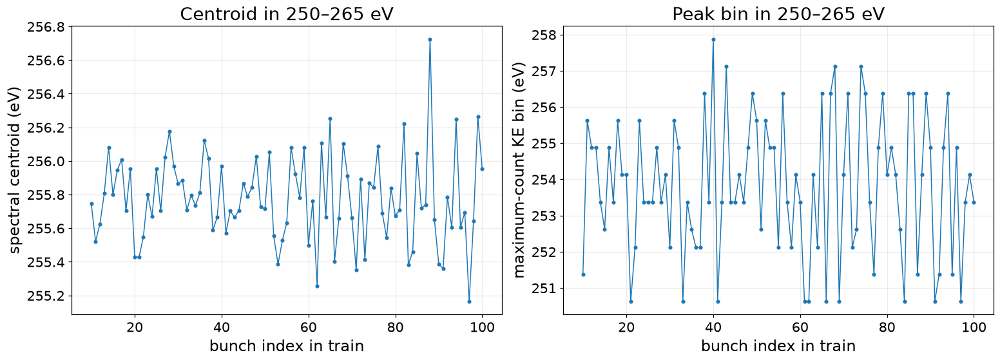

In [35]:
# --- Track a direct-photoelectron feature through the pulse train ---

TRACK_KE_RANGE = (250.0,265.0)
track = (SPECTRAL_KE_CENTRES >= TRACK_KE_RANGE[0]) & (SPECTRAL_KE_CENTRES < TRACK_KE_RANGE[1])

centroid = np.full(n_bunch,np.nan)
peak_bin = np.full(n_bunch,np.nan)

for b in bunches_local:
    y = ke_hist_bunch[b,track].astype(float)
    x = SPECTRAL_KE_CENTRES[track]
    if y.sum() <= 0: continue
    centroid[b] = np.sum(x*y)/np.sum(y)
    peak_bin[b] = x[np.argmax(y)]

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
axes[0].plot(bunches_local,centroid[bunches_local],"o-",ms=3,lw=1)
axes[0].set(xlabel="bunch index in train",ylabel="spectral centroid (eV)",title=f"Centroid in {TRACK_KE_RANGE[0]:g}–{TRACK_KE_RANGE[1]:g} eV")
axes[0].grid(alpha=0.25)

axes[1].plot(bunches_local,peak_bin[bunches_local],"o-",ms=3,lw=1)
axes[1].set(xlabel="bunch index in train",ylabel="maximum-count KE bin (eV)",title=f"Peak bin in {TRACK_KE_RANGE[0]:g}–{TRACK_KE_RANGE[1]:g} eV")
axes[1].grid(alpha=0.25)
plt.show()

In [36]:
# --- Inspect metadata for additional beam and detector diagnostics ---

with h5py.File(source_h5,"r") as handle:
    for name in ["hor_pos","ver_pos","mpe","z","z_std","tofs_e","tofs_i","between_tdc_files","tID"]:
        if name not in handle: continue
        ds = handle[name]
        print(f"\n{name}: shape={ds.shape}, dtype={ds.dtype}")
        if ds.attrs:
            for key,value in ds.attrs.items(): print(f"  {key}: {value}")
        else:
            print("  no dataset attributes")


hor_pos: shape=(35439,), dtype=float32
  no dataset attributes

ver_pos: shape=(35439,), dtype=float32
  no dataset attributes

mpe: shape=(35439,), dtype=float32
  no dataset attributes

z: shape=(35439, 101), dtype=float32
  no dataset attributes

z_std: shape=(35439, 101), dtype=float32
  no dataset attributes

tofs_e: shape=(35439, 101, 50), dtype=uint32
  no dataset attributes

tofs_i: shape=(35439, 101, 120), dtype=uint32
  no dataset attributes

between_tdc_files: shape=(35439,), dtype=bool
  no dataset attributes

tID: shape=(35439,), dtype=float64
  no dataset attributes


### Detector dead time

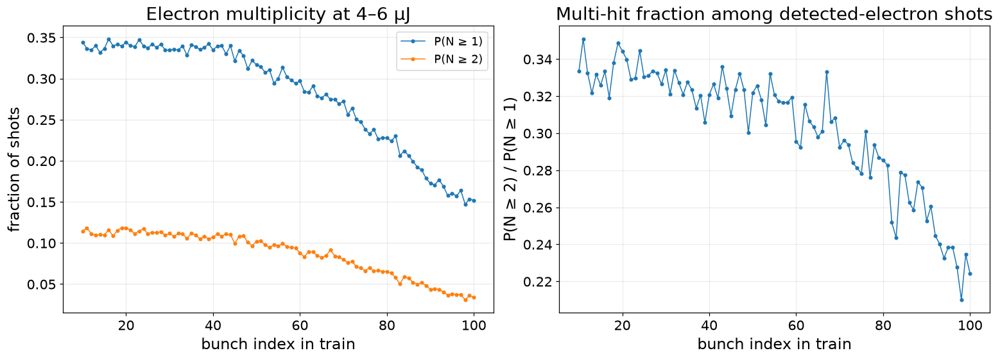

In [37]:
# --- Electron multiplicity and multi-hit response through the train ---

MULTIHIT_GMD_RANGE = (4.0,6.0)
multihit_mask = current_mask & (gmd >= MULTIHIT_GMD_RANGE[0]) & (gmd < MULTIHIT_GMD_RANGE[1])
Ne = data["total_electrons"]

p_any = np.full(n_bunch,np.nan)
p_multi = np.full(n_bunch,np.nan)
p_multi_given_any = np.full(n_bunch,np.nan)
mean_mult = np.full(n_bunch,np.nan)

for b in bunches_local:
    use = multihit_mask[:,b]
    if not np.any(use): continue
    n = Ne[use,b]
    p_any[b] = np.mean(n >= 1)
    p_multi[b] = np.mean(n >= 2)
    p_multi_given_any[b] = np.mean(n >= 2)/np.mean(n >= 1) if np.mean(n >= 1) > 0 else np.nan
    mean_mult[b] = np.mean(n)

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

axes[0].plot(bunches_local,p_any[bunches_local],"o-",ms=3,lw=1,label="P(N ≥ 1)")
axes[0].plot(bunches_local,p_multi[bunches_local],"o-",ms=3,lw=1,label="P(N ≥ 2)")
axes[0].set(xlabel="bunch index in train",ylabel="fraction of shots",title=f"Electron multiplicity at {MULTIHIT_GMD_RANGE[0]:g}–{MULTIHIT_GMD_RANGE[1]:g} µJ")
axes[0].grid(alpha=0.25); axes[0].legend()

axes[1].plot(bunches_local,p_multi_given_any[bunches_local],"o-",ms=3,lw=1)
axes[1].set(xlabel="bunch index in train",ylabel="P(N ≥ 2) / P(N ≥ 1)",title="Multi-hit fraction among detected-electron shots")
axes[1].grid(alpha=0.25)

plt.show()

### Is the observed multi-hit fraction lower than what we expect purely from the measured occupancy?

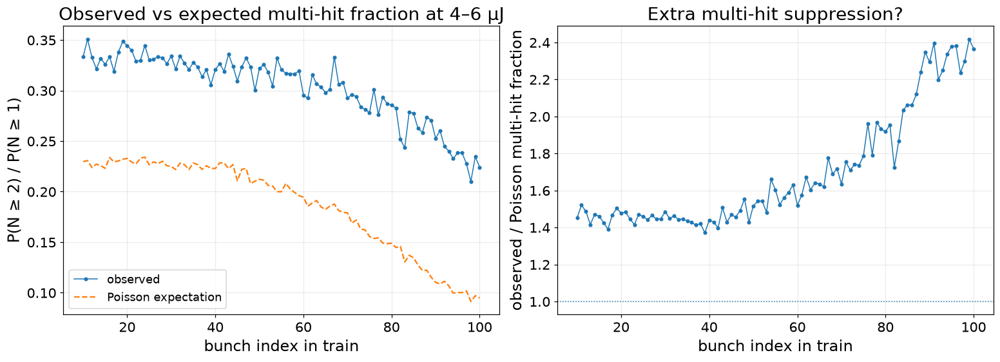

In [38]:
# --- Does the multi-hit fraction show an extra loss beyond lower occupancy? ---

MULTIHIT_GMD_RANGE = (4.0,6.0)
multihit_mask = current_mask & (gmd >= MULTIHIT_GMD_RANGE[0]) & (gmd < MULTIHIT_GMD_RANGE[1])
Ne = data["total_electrons"]

mean_n = np.full(n_bunch,np.nan)
p_any = np.full(n_bunch,np.nan)
p_multi = np.full(n_bunch,np.nan)
p_multi_given_any = np.full(n_bunch,np.nan)
poisson_multi_given_any = np.full(n_bunch,np.nan)

for b in bunches_local:
    use = multihit_mask[:,b]
    if not np.any(use): continue
    n = Ne[use,b].astype(float)
    mean_n[b] = np.mean(n)
    p_any[b] = np.mean(n >= 1)
    p_multi[b] = np.mean(n >= 2)
    p_multi_given_any[b] = p_multi[b]/p_any[b] if p_any[b] > 0 else np.nan

    lam = mean_n[b]
    p1p = 1-np.exp(-lam)
    p2p = 1-np.exp(-lam)*(1+lam)
    poisson_multi_given_any[b] = p2p/p1p if p1p > 0 else np.nan

ratio_to_poisson = p_multi_given_any/poisson_multi_given_any

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

axes[0].plot(bunches_local,p_multi_given_any[bunches_local],"o-",ms=3,lw=1,label="observed")
axes[0].plot(bunches_local,poisson_multi_given_any[bunches_local],"--",lw=1.5,label="Poisson expectation")
axes[0].set(xlabel="bunch index in train",ylabel="P(N ≥ 2) / P(N ≥ 1)",title=f"Observed vs expected multi-hit fraction at {MULTIHIT_GMD_RANGE[0]:g}–{MULTIHIT_GMD_RANGE[1]:g} µJ")
axes[0].grid(alpha=0.25); axes[0].legend()

axes[1].plot(bunches_local,ratio_to_poisson[bunches_local],"o-",ms=3,lw=1)
axes[1].axhline(1,ls=":",lw=1)
axes[1].set(xlabel="bunch index in train",ylabel="observed / Poisson multi-hit fraction",title="Extra multi-hit suppression?")
axes[1].grid(alpha=0.25)

plt.show()

/tmp/ipykernel_2232469/2119934695.py:7: RuntimeWarning: Mean of empty slice
  z_mean = np.array([np.nanmean(z_diag[current_mask[:,b],b]) for b in range(n_bunch)])
/tmp/ipykernel_2232469/2119934695.py:8: RuntimeWarning: Mean of empty slice
  zstd_mean = np.array([np.nanmean(zstd_diag[current_mask[:,b],b]) for b in range(n_bunch)])


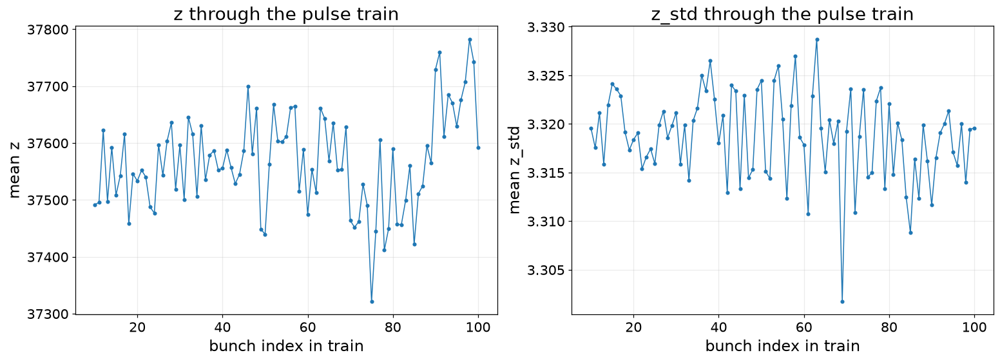

In [39]:
# --- Unidentified bunch-resolved diagnostics: z and z_std ---

with h5py.File(source_h5,"r") as handle:
    z_diag = handle["z"][:n_trains]
    zstd_diag = handle["z_std"][:n_trains]

z_mean = np.array([np.nanmean(z_diag[current_mask[:,b],b]) for b in range(n_bunch)])
zstd_mean = np.array([np.nanmean(zstd_diag[current_mask[:,b],b]) for b in range(n_bunch)])

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
axes[0].plot(bunches_local,z_mean[bunches_local],"o-",ms=3,lw=1)
axes[0].set(xlabel="bunch index in train",ylabel="mean z",title="z through the pulse train")
axes[0].grid(alpha=0.25)

axes[1].plot(bunches_local,zstd_mean[bunches_local],"o-",ms=3,lw=1)
axes[1].set(xlabel="bunch index in train",ylabel="mean z_std",title="z_std through the pulse train")
axes[1].grid(alpha=0.25)
plt.show()

### Deriving a Cb factor from ions and apply it to electrons

In [40]:
# --- Cross-detector test: learn the bunch correction from ions and apply it to electrons ---

def learn_bunch_correction(counts,train_rows):
    """Relative counts/GMD response versus bunch position, learned on training rows only."""
    c = counts[train_rows].astype(float)
    g = gmd[train_rows]
    valid = current_mask[train_rows]

    num = np.sum(np.where(valid,c,0),axis=0)
    den = np.sum(np.where(valid,g,0),axis=0)
    rate = np.divide(num,den,out=np.full(n_bunch,np.nan),where=den > 0)

    use = (np.arange(n_bunch) >= INDEP_BUNCH_START) & np.isfinite(rate) & (rate > 0)
    scale = np.nanmean(rate[use])

    cb = np.ones(n_bunch,dtype=float)
    cb[use] = rate[use]/scale
    return cb

shape = (INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch)
target_cv = np.zeros(shape)
shots_cv = np.zeros(shape)
gmd_cv = np.zeros(shape)
ion_cb_cv = np.zeros(shape)
electron_cb_cv = np.zeros(shape)

ion_cb_folds = np.ones((INDEP_CV_MOD,n_bunch))
electron_cb_folds = np.ones((INDEP_CV_MOD,n_bunch))

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    cb_ion = learn_bunch_correction(ion_counts,train_rows)
    cb_electron = learn_bunch_correction(data["ref_counts"],train_rows)
    ion_cb_folds[off] = cb_ion
    electron_cb_folds[off] = cb_electron

    g_test = gmd[test_rows]
    selected = current_mask[test_rows]
    target = data["target_counts"][test_rows].astype(float)

    target_cv[off] = band_sums(target,g_test,selected)
    shots_cv[off] = band_sums(np.ones_like(g_test),g_test,selected)
    gmd_cv[off] = band_sums(g_test,g_test,selected)
    ion_cb_cv[off] = band_sums(g_test*cb_ion[None,:],g_test,selected)
    electron_cb_cv[off] = band_sums(g_test*cb_electron[None,:],g_test,selected)

obs = target_cv.sum(axis=0)
shots = shots_cv.sum(axis=0)

m_gmd = bunch_metrics(obs,gmd_cv.sum(axis=0),shots)
m_ion_cb = bunch_metrics(obs,ion_cb_cv.sum(axis=0),shots)
m_electron_cb = bunch_metrics(obs,electron_cb_cv.sum(axis=0),shots)

fig,axes = plt.subplots(2,2,figsize=(15,10),constrained_layout=True)

plot_bunch_response(m_gmd,f"GMD only: slope {m_gmd['slope']:+.2f}% / 10 bunches",axes[0,0])
plot_bunch_response(m_ion_cb,f"Ion-derived Cb: slope {m_ion_cb['slope']:+.2f}% / 10 bunches",axes[0,1])
plot_bunch_response(m_electron_cb,f"Electron-derived Cb: slope {m_electron_cb['slope']:+.2f}% / 10 bunches",axes[1,0])
axes[0,0].legend(ncol=2,fontsize=9)

b = np.arange(INDEP_BUNCH_START,n_bunch)
ion_cb_mean = np.mean(ion_cb_folds,axis=0)
ion_cb_sd = np.std(ion_cb_folds,axis=0,ddof=1)
electron_cb_mean = np.mean(electron_cb_folds,axis=0)
electron_cb_sd = np.std(electron_cb_folds,axis=0,ddof=1)

axes[1,1].errorbar(b,ion_cb_mean[b],yerr=ion_cb_sd[b],fmt="o-",ms=3,lw=1,capsize=2,label="ion-derived Cb")
axes[1,1].errorbar(b,electron_cb_mean[b],yerr=electron_cb_sd[b],fmt="o-",ms=3,lw=1,capsize=2,label="electron-derived Cb")
axes[1,1].axhline(1,ls=":",lw=1)
axes[1,1].set(xlabel="bunch index in train",ylabel="relative bunch response",title="Independent ion and electron bunch corrections")
axes[1,1].grid(alpha=0.25); axes[1,1].legend()

plt.show()

use = np.isfinite(ion_cb_mean[b]) & np.isfinite(electron_cb_mean[b])
r_cb = np.corrcoef(ion_cb_mean[b][use],electron_cb_mean[b][use])[0,1]

print(f"GMD only:           slope={m_gmd['slope']:+.3f}% / 10 bunches, flatness={m_gmd['flatness']:.5f}")
print(f"Ion-derived Cb:     slope={m_ion_cb['slope']:+.3f}% / 10 bunches, flatness={m_ion_cb['flatness']:.5f}")
print(f"Electron-derived Cb: slope={m_electron_cb['slope']:+.3f}% / 10 bunches, flatness={m_electron_cb['flatness']:.5f}")
print(f"Ion/electron Cb correlation: r={r_cb:+.4f}")

NameError: name 'ion_counts' is not defined

## Neighbour electron behaviour

### Fit S(H) after using bunch-specific GMD fitting

In [ ]:
# --- Persistent-state model S(H): can previous total-electron load predict current residual response? ---

from scipy.optimize import minimize

HISTORY_SHOTS = 5

# H_total[:,b] = ALL detected electrons in the previous HISTORY_SHOTS shots.
H_total = np.full_like(gmd,np.nan,dtype=float)
for b in range(HISTORY_SHOTS,n_bunch): H_total[:,b] = data["total_electrons"][:,b-HISTORY_SHOTS:b].sum(axis=1)

def state_response(H,p):
    """Positive multiplicative response: jump at H>0 + gradual log-load dependence."""
    c,b_jump,b_load = p
    return np.exp(c+b_jump*(H > 0)+b_load*np.log1p(H))

def poisson_nll(p,y,mu,H):
    lam = mu*state_response(H,p)
    return np.sum(lam-y*np.log(np.clip(lam,1e-12,None)))

def poisson_deviance(y,mu):
    y = np.asarray(y,dtype=float)
    mu = np.clip(np.asarray(mu,dtype=float),1e-12,None)
    term = np.empty_like(mu)
    zero = y <= 0
    pos = ~zero
    term[zero] = mu[zero]
    term[pos] = y[pos]*np.log(y[pos]/mu[pos])-(y[pos]-mu[pos])
    return 2*np.sum(term)

state_fits = []
ref_obs_cv = np.full_like(gmd,np.nan,dtype=float)
ref_base_cv = np.full_like(gmd,np.nan,dtype=float)
ref_state_cv = np.full_like(gmd,np.nan,dtype=float)
target_obs_cv = np.full_like(gmd,np.nan,dtype=float)
target_base_cv = np.full_like(gmd,np.nan,dtype=float)
target_state_cv = np.full_like(gmd,np.nan,dtype=float)

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    g_train,g_test = gmd[train_rows],gmd[test_rows]
    sel_train,sel_test = current_mask[train_rows],current_mask[test_rows]

    # Independent bunch-specific GMD baselines for reference and target regions.
    ref_base_train,ref_beta = fit_bunch_baseline(g_train,data["ref_counts"][train_rows],sel_train)
    ref_base_test = apply_bunch_baseline(g_test,ref_beta)

    target_base_train,target_beta = fit_bunch_baseline(g_train,data["target_counts"][train_rows],sel_train)
    target_base_test = apply_bunch_baseline(g_test,target_beta)

    H_train,H_test = H_total[train_rows],H_total[test_rows]
    y_train = data["ref_counts"][train_rows].astype(float)

    fit_mask = sel_train & np.isfinite(H_train) & np.isfinite(ref_base_train) & (ref_base_train > 0)
    result = minimize(poisson_nll,x0=np.zeros(3),args=(y_train[fit_mask],ref_base_train[fit_mask],H_train[fit_mask]),
                      method="L-BFGS-B",bounds=[(-2,2),(-2,2),(-2,2)])
    p = result.x
    state_fits.append({"fold":off,"c":p[0],"beta_jump":p[1],"beta_load":p[2],"success":result.success})

    ref_obs_cv[test_rows] = data["ref_counts"][test_rows]
    ref_base_cv[test_rows] = ref_base_test
    ref_state_cv[test_rows] = ref_base_test*state_response(H_test,p)

    target_obs_cv[test_rows] = data["target_counts"][test_rows]
    target_base_cv[test_rows] = target_base_test
    target_state_cv[test_rows] = target_base_test*state_response(H_test,p)

state_table = pd.DataFrame(state_fits).set_index("fold")
display(state_table.round(5))

valid_ref = current_mask & np.isfinite(H_total) & np.isfinite(ref_base_cv) & (ref_base_cv > 0) & np.isfinite(ref_state_cv) & (ref_state_cv > 0)
valid_target = current_mask & np.isfinite(H_total) & np.isfinite(target_base_cv) & (target_base_cv > 0) & np.isfinite(target_state_cv) & (target_state_cv > 0)

ref_dev0 = poisson_deviance(ref_obs_cv[valid_ref],ref_base_cv[valid_ref])
ref_dev1 = poisson_deviance(ref_obs_cv[valid_ref],ref_state_cv[valid_ref])
target_dev0 = poisson_deviance(target_obs_cv[valid_target],target_base_cv[valid_target])
target_dev1 = poisson_deviance(target_obs_cv[valid_target],target_state_cv[valid_target])

print(f"Reference held-out deviance: {ref_dev0:.2f} -> {ref_dev1:.2f}  ({100*(1-ref_dev1/ref_dev0):+.3f}% improvement)")
print(f"Target held-out deviance:    {target_dev0:.2f} -> {target_dev1:.2f}  ({100*(1-target_dev1/target_dev0):+.3f}% improvement)")

,c,beta_jump,beta_load,success
fold,,,,
0,-0.04436,-0.03714,0.06676,True
1,-0.04697,-0.03145,0.06475,True
2,-0.04259,-0.02808,0.05843,True
3,-0.04213,-0.04429,0.07011,True
4,-0.03985,-0.02349,0.05257,True


Reference held-out deviance: 353618.95 -> 353577.41  (+0.012% improvement)
Target held-out deviance:    1114284.87 -> 1114090.97  (+0.017% improvement)


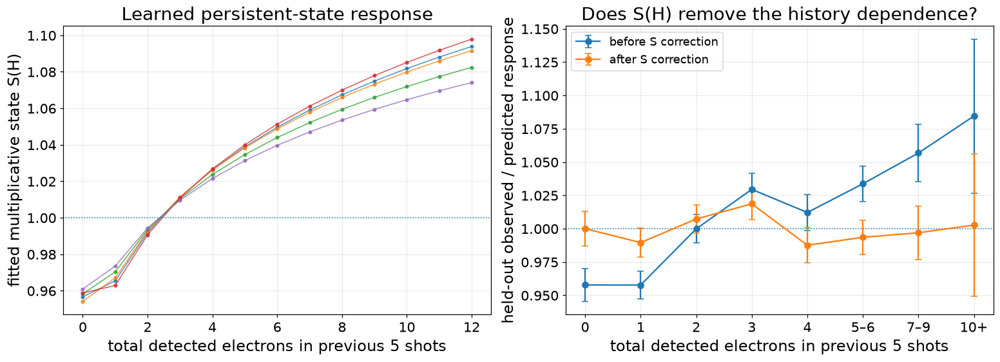

In [ ]:
# --- Diagnostic: learned S(H) and held-out dose-response before/after correction ---

H_PLOT_MAX = 12
h_plot = np.arange(H_PLOT_MAX+1)

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

for _,fit in state_table.iterrows():
    p = np.array([fit["c"],fit["beta_jump"],fit["beta_load"]])
    axes[0].plot(h_plot,state_response(h_plot,p),"o-",ms=3,lw=1,alpha=0.8)
axes[0].axhline(1,ls=":",lw=1)
axes[0].set(xlabel=f"total detected electrons in previous {HISTORY_SHOTS} shots",ylabel="fitted multiplicative state S(H)",title="Learned persistent-state response")
axes[0].grid(alpha=0.25)

HISTORY_BINS = [(0,0),(1,1),(2,2),(3,3),(4,4),(5,6),(7,9),(10,np.inf)]
labels = ["0","1","2","3","4","5–6","7–9","10+"]
before,after,before_err,after_err = [],[],[],[]

for lo,hi in HISTORY_BINS:
    use = valid_ref & (H_total >= lo) & (H_total <= hi)
    y = ref_obs_cv[use]
    mu0 = ref_base_cv[use]
    mu1 = ref_state_cv[use]
    before.append(y.sum()/mu0.sum())
    after.append(y.sum()/mu1.sum())
    before_err.append(np.sqrt(y.sum())/mu0.sum())
    after_err.append(np.sqrt(y.sum())/mu1.sum())

x = np.arange(len(labels))
axes[1].errorbar(x,before,yerr=before_err,fmt="o-",capsize=3,label="before S correction")
axes[1].errorbar(x,after,yerr=after_err,fmt="o-",capsize=3,label="after S correction")
axes[1].axhline(1,ls=":",lw=1)
axes[1].set_xticks(x,labels)
axes[1].set(xlabel=f"total detected electrons in previous {HISTORY_SHOTS} shots",ylabel="held-out observed / predicted response",title="Does S(H) remove the history dependence?")
axes[1].grid(alpha=0.25); axes[1].legend()

plt.show()

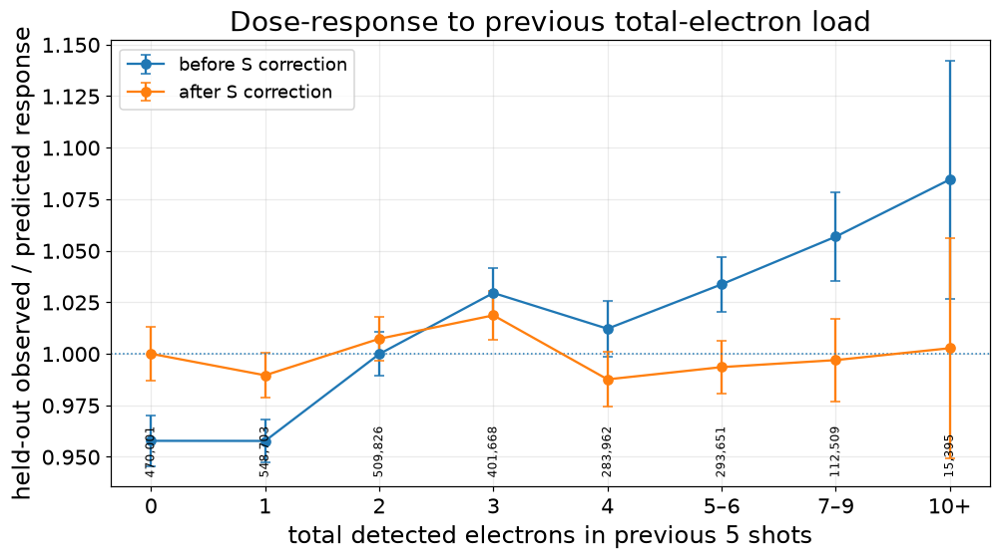

In [ ]:
# --- Before/after S-correction dose-response vs previous total-electron load ---

HISTORY_BINS = [(0,0),(1,1),(2,2),(3,3),(4,4),(5,6),(7,9),(10,np.inf)]
HISTORY_LABELS = ["0","1","2","3","4","5–6","7–9","10+"]

valid = current_mask & np.isfinite(H_total) & np.isfinite(ref_base_cv) & (ref_base_cv > 0) & np.isfinite(ref_state_cv) & (ref_state_cv > 0)
before,after,before_err,after_err,counts = [],[],[],[],[]

for lo,hi in HISTORY_BINS:
    use = valid & (H_total >= lo) & (H_total <= hi)
    y = ref_obs_cv[use]
    mu0 = ref_base_cv[use]
    mu1 = ref_state_cv[use]
    before.append(y.sum()/mu0.sum())
    after.append(y.sum()/mu1.sum())
    before_err.append(np.sqrt(y.sum())/mu0.sum())
    after_err.append(np.sqrt(y.sum())/mu1.sum())
    counts.append(use.sum())

x = np.arange(len(HISTORY_LABELS))
fig,ax = plt.subplots(figsize=(9,5),constrained_layout=True)
ax.errorbar(x,before,yerr=before_err,fmt="o-",capsize=3,label="before S correction")
ax.errorbar(x,after,yerr=after_err,fmt="o-",capsize=3,label="after S correction")
ax.axhline(1,ls=":",lw=1)
ax.set_xticks(x,HISTORY_LABELS)
ax.set_xlabel("total detected electrons in previous 5 shots")
ax.set_ylabel("held-out observed / predicted response")
ax.set_title("Dose-response to previous total-electron load")
ax.grid(alpha=0.25)
ax.legend()

for xi,c in zip(x,counts): ax.text(xi,ax.get_ylim()[0]+0.02*(ax.get_ylim()[1]-ax.get_ylim()[0]),f"{c:,}",ha="center",va="bottom",fontsize=8,rotation=90)
plt.show()

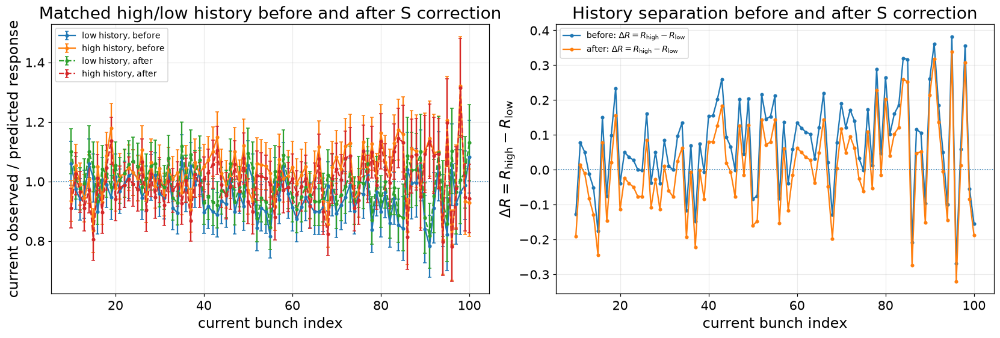

Mean ΔR before S correction: +0.0762
Mean ΔR after S correction:  +0.0084


In [ ]:
# --- Matched high/low total-electron history, before vs after S correction ---

GMD_BIN_WIDTH = 0.5
MIN_PER_GROUP = 5

valid = current_mask & np.isfinite(H_total) & np.isfinite(ref_base_cv) & (ref_base_cv > 0) & np.isfinite(ref_state_cv) & (ref_state_cv > 0)
gmd_bin = np.floor(gmd/GMD_BIN_WIDTH).astype(int)

low_before,high_before,low_after,high_after = [],[],[],[]
low_before_err,high_before_err,low_after_err,high_after_err = [],[],[],[]
delta_before,delta_after = [],[]

for b in range(10,n_bunch):
    use_b = valid[:,b]
    if use_b.sum() == 0:
        low_before.append(np.nan); high_before.append(np.nan); low_after.append(np.nan); high_after.append(np.nan)
        low_before_err.append(np.nan); high_before_err.append(np.nan); low_after_err.append(np.nan); high_after_err.append(np.nan)
        delta_before.append(np.nan); delta_after.append(np.nan)
        continue

    h = H_total[:,b][use_b]
    gb = gmd_bin[:,b][use_b]
    y = ref_obs_cv[:,b][use_b]
    mu0 = ref_base_cv[:,b][use_b]
    mu1 = ref_state_cv[:,b][use_b]

    q1,q3 = np.quantile(h,[0.25,0.75])
    low_sel = h <= q1
    high_sel = h >= q3

    low_y0 = low_mu0 = low_y1 = low_mu1 = 0.0
    high_y0 = high_mu0 = high_y1 = high_mu1 = 0.0

    for g in np.intersect1d(np.unique(gb[low_sel]),np.unique(gb[high_sel])):
        il = np.where(low_sel & (gb == g))[0]
        ih = np.where(high_sel & (gb == g))[0]
        m = min(len(il),len(ih))
        if m < MIN_PER_GROUP: continue
        il = il[:m]; ih = ih[:m]
        low_y0 += y[il].sum(); low_mu0 += mu0[il].sum(); low_y1 += y[il].sum(); low_mu1 += mu1[il].sum()
        high_y0 += y[ih].sum(); high_mu0 += mu0[ih].sum(); high_y1 += y[ih].sum(); high_mu1 += mu1[ih].sum()

    if min(low_mu0,high_mu0,low_mu1,high_mu1) <= 0:
        low_before.append(np.nan); high_before.append(np.nan); low_after.append(np.nan); high_after.append(np.nan)
        low_before_err.append(np.nan); high_before_err.append(np.nan); low_after_err.append(np.nan); high_after_err.append(np.nan)
        delta_before.append(np.nan); delta_after.append(np.nan)
        continue

    rlb = low_y0/low_mu0
    rhb = high_y0/high_mu0
    rla = low_y1/low_mu1
    rha = high_y1/high_mu1

    low_before.append(rlb); high_before.append(rhb); low_after.append(rla); high_after.append(rha)
    low_before_err.append(np.sqrt(low_y0)/low_mu0); high_before_err.append(np.sqrt(high_y0)/high_mu0)
    low_after_err.append(np.sqrt(low_y1)/low_mu1); high_after_err.append(np.sqrt(high_y1)/high_mu1)
    delta_before.append(rhb-rlb); delta_after.append(rha-rla)

bunch_axis = np.arange(10,n_bunch)

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)

axes[0].errorbar(bunch_axis,low_before,yerr=low_before_err,fmt="o-",ms=3,capsize=2,label="low history, before")
axes[0].errorbar(bunch_axis,high_before,yerr=high_before_err,fmt="o-",ms=3,capsize=2,label="high history, before")
axes[0].errorbar(bunch_axis,low_after,yerr=low_after_err,fmt="o--",ms=3,capsize=2,label="low history, after")
axes[0].errorbar(bunch_axis,high_after,yerr=high_after_err,fmt="o--",ms=3,capsize=2,label="high history, after")
axes[0].axhline(1,ls=":",lw=1)
axes[0].set_xlabel("current bunch index")
axes[0].set_ylabel("current observed / predicted response")
axes[0].set_title("Matched high/low history before and after S correction")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=9)

axes[1].plot(bunch_axis,delta_before,"o-",ms=3,label=r"before: $\Delta R = R_{\rm high}-R_{\rm low}$")
axes[1].plot(bunch_axis,delta_after,"o-",ms=3,label=r"after: $\Delta R = R_{\rm high}-R_{\rm low}$")
axes[1].axhline(0,ls=":",lw=1)
axes[1].set_xlabel("current bunch index")
axes[1].set_ylabel(r"$\Delta R = R_{\rm high}-R_{\rm low}$")
axes[1].set_title("History separation before and after S correction")
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=9)

plt.show()

print(f"Mean ΔR before S correction: {np.nanmean(delta_before):+.4f}")
print(f"Mean ΔR after S correction:  {np.nanmean(delta_after):+.4f}")

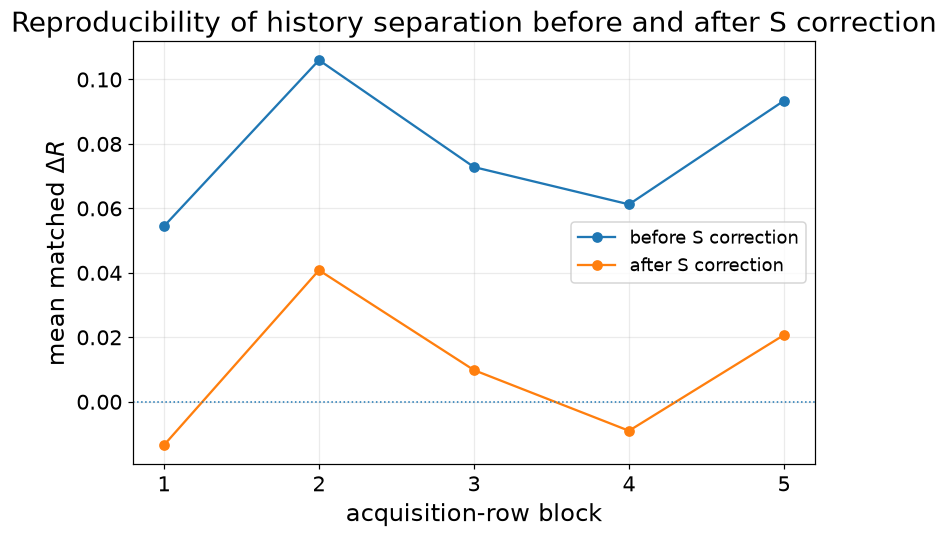

Before: [0.0544 0.1059 0.0728 0.0612 0.0933]
After:  [-0.0135  0.0408  0.0098 -0.0091  0.0207]


In [ ]:
# --- Reproducibility of matched history separation across acquisition-row blocks ---

N_BLOCKS = 5
GMD_BIN_WIDTH = 0.5
MIN_PER_GROUP = 5

order = np.arange(gmd.shape[0])
block_id = np.empty(gmd.shape[0],dtype=int)
for k,idx in enumerate(np.array_split(order,N_BLOCKS)): block_id[idx] = k

def matched_delta_for_block(block):
    deltas_before,deltas_after = [],[]

    for b in range(10,n_bunch):
        valid = (block_id == block) & current_mask[:,b] & np.isfinite(H_total[:,b]) & np.isfinite(ref_base_cv[:,b]) & (ref_base_cv[:,b] > 0) & np.isfinite(ref_state_cv[:,b]) & (ref_state_cv[:,b] > 0)
        idx = np.flatnonzero(valid)
        if idx.size < 20: continue

        h = H_total[idx,b]
        q1,q3 = np.quantile(h,[0.25,0.75])
        low = idx[h <= q1]
        high = idx[h >= q3]

        obs_lo_b = pred_lo_b = state_lo_b = 0.0
        obs_hi_b = pred_hi_b = state_hi_b = 0.0

        for lo,hi in zip(np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1],GMD_BIN_WIDTH),
                         np.arange(INDEP_GMD_RANGE[0]+GMD_BIN_WIDTH,INDEP_GMD_RANGE[1]+GMD_BIN_WIDTH,GMD_BIN_WIDTH)):
            il = low[(gmd[low,b] >= lo) & (gmd[low,b] < hi)]
            ih = high[(gmd[high,b] >= lo) & (gmd[high,b] < hi)]
            m = min(il.size,ih.size)
            if m < MIN_PER_GROUP: continue

            wlo,whi = m/il.size,m/ih.size
            obs_lo_b += wlo*ref_obs_cv[il,b].sum()
            pred_lo_b += wlo*ref_base_cv[il,b].sum()
            state_lo_b += wlo*ref_state_cv[il,b].sum()
            obs_hi_b += whi*ref_obs_cv[ih,b].sum()
            pred_hi_b += whi*ref_base_cv[ih,b].sum()
            state_hi_b += whi*ref_state_cv[ih,b].sum()

        if min(pred_lo_b,pred_hi_b,state_lo_b,state_hi_b) <= 0: continue

        deltas_before.append(obs_hi_b/pred_hi_b-obs_lo_b/pred_lo_b)
        deltas_after.append(obs_hi_b/state_hi_b-obs_lo_b/state_lo_b)

    return np.nanmean(deltas_before),np.nanmean(deltas_after)

block_before,block_after = [],[]
for block in range(N_BLOCKS):
    db,da = matched_delta_for_block(block)
    block_before.append(db); block_after.append(da)

fig,ax = plt.subplots(figsize=(8,5))
ax.plot(np.arange(1,N_BLOCKS+1),block_before,"o-",label="before S correction")
ax.plot(np.arange(1,N_BLOCKS+1),block_after,"o-",label="after S correction")
ax.axhline(0,ls=":",lw=1)
ax.set_xticks(np.arange(1,N_BLOCKS+1))
ax.set_xlabel("acquisition-row block")
ax.set_ylabel(r"mean matched $\Delta R$")
ax.set_title("Reproducibility of history separation before and after S correction")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

print("Before:",np.round(block_before,4))
print("After: ",np.round(block_after,4))

### Testing the model in unseen data

,c,beta_jump,beta_load,ref deviance improvement (%),target deviance improvement (%),matched ΔR before,matched ΔR after,fit success
held-out block,,,,,,,,
1,-0.04210,-0.04912,0.07128,0.00253,0.01517,0.05440,-0.01728,True
2,-0.03417,-0.02688,0.05614,0.01562,0.01058,0.10594,0.04585,True
3,-0.02215,-0.04509,0.06411,-0.00145,-0.00412,0.07275,0.01319,True
4,-0.05281,-0.02061,0.05968,0.00927,0.02535,0.06118,-0.01146,True
5,-0.06506,-0.02306,0.06150,-0.01338,-0.02885,0.09334,0.01745,True


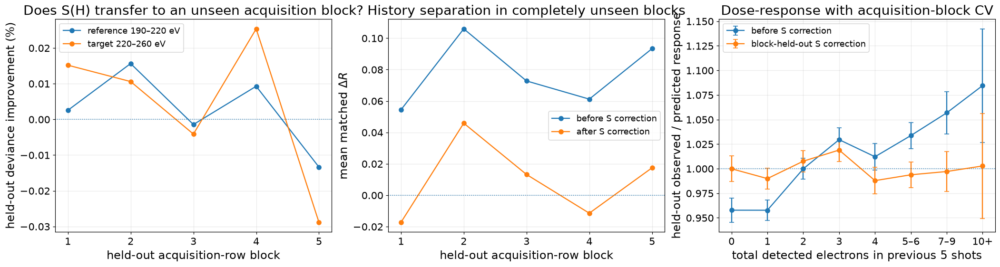


Mean across held-out acquisition blocks:
Reference deviance improvement: +0.003%
Target deviance improvement:    +0.004%
Matched ΔR before:              +0.0775
Matched ΔR after:               +0.0096


In [ ]:
# --- Acquisition-block CV of S(H): train S on 4 blocks, test on the unseen 5th block ---

from scipy.optimize import minimize

N_BLOCKS = 5
MATCH_GMD_STEP = 0.5
MIN_PER_GROUP = 5

# Stored row order only: tID is not globally monotonic, so call these acquisition-row blocks.
block_id = np.empty(n_trains,dtype=int)
for k,idx in enumerate(np.array_split(np.arange(n_trains),N_BLOCKS)): block_id[idx] = k

def state_response_blocked(H,p):
    c,b_jump,b_load = p
    return np.exp(c+b_jump*(H > 0)+b_load*np.log1p(H))

def poisson_nll_blocked(p,y,mu,H):
    lam = np.clip(mu*state_response_blocked(H,p),1e-12,None)
    return np.sum(lam-y*np.log(lam))

def poisson_deviance_safe(y,mu):
    y = np.asarray(y,dtype=float)
    mu = np.clip(np.asarray(mu,dtype=float),1e-12,None)
    term = np.empty_like(mu)
    zero = y <= 0
    term[zero] = mu[zero]
    term[~zero] = y[~zero]*np.log(y[~zero]/mu[~zero])-(y[~zero]-mu[~zero])
    return 2*np.sum(term)

def matched_delta_rows(rows,base_pred,state_pred):
    delta_before,delta_after = [],[]
    gmd_edges = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+MATCH_GMD_STEP,MATCH_GMD_STEP)

    for b in range(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch):
        valid = rows & current_mask[:,b] & np.isfinite(H_total[:,b]) & np.isfinite(base_pred[:,b]) & (base_pred[:,b] > 0) & np.isfinite(state_pred[:,b]) & (state_pred[:,b] > 0)
        idx = np.flatnonzero(valid)
        if idx.size < 20: continue

        h = H_total[idx,b]
        q1,q3 = np.quantile(h,[0.25,0.75])
        if q1 >= q3: continue
        low = idx[h <= q1]
        high = idx[h >= q3]

        obs_lo = pred_lo = state_lo = 0.0
        obs_hi = pred_hi = state_hi = 0.0

        for lo,hi in zip(gmd_edges[:-1],gmd_edges[1:]):
            il = low[(gmd[low,b] >= lo) & (gmd[low,b] < hi)]
            ih = high[(gmd[high,b] >= lo) & (gmd[high,b] < hi)]
            m = min(il.size,ih.size)
            if m < MIN_PER_GROUP: continue

            wlo,whi = m/il.size,m/ih.size
            obs_lo += wlo*data["ref_counts"][il,b].sum()
            pred_lo += wlo*base_pred[il,b].sum()
            state_lo += wlo*state_pred[il,b].sum()
            obs_hi += whi*data["ref_counts"][ih,b].sum()
            pred_hi += whi*base_pred[ih,b].sum()
            state_hi += whi*state_pred[ih,b].sum()

        if min(pred_lo,pred_hi,state_lo,state_hi) <= 0: continue
        delta_before.append(obs_hi/pred_hi-obs_lo/pred_lo)
        delta_after.append(obs_hi/state_hi-obs_lo/state_lo)

    return np.nanmean(delta_before),np.nanmean(delta_after)

# Every row receives an S prediction from a model that never saw its acquisition block.
ref_state_blockcv = np.full_like(gmd,np.nan,dtype=float)
target_state_blockcv = np.full_like(gmd,np.nan,dtype=float)
block_rows = []

for held_block in range(N_BLOCKS):
    train_rows = block_id != held_block
    test_rows = block_id == held_block

    fit_mask = train_rows[:,None] & current_mask & np.isfinite(H_total) & np.isfinite(ref_base_cv) & (ref_base_cv > 0)
    result = minimize(poisson_nll_blocked,x0=np.zeros(3),
                      args=(data["ref_counts"][fit_mask].astype(float),ref_base_cv[fit_mask],H_total[fit_mask]),
                      method="L-BFGS-B",bounds=[(-2,2),(-2,2),(-2,2)])
    p = result.x

    ref_state_blockcv[test_rows] = ref_base_cv[test_rows]*state_response_blocked(H_total[test_rows],p)
    target_state_blockcv[test_rows] = target_base_cv[test_rows]*state_response_blocked(H_total[test_rows],p)

    ref_valid = test_rows[:,None] & current_mask & np.isfinite(H_total) & np.isfinite(ref_base_cv) & (ref_base_cv > 0) & np.isfinite(ref_state_blockcv) & (ref_state_blockcv > 0)
    target_valid = test_rows[:,None] & current_mask & np.isfinite(H_total) & np.isfinite(target_base_cv) & (target_base_cv > 0) & np.isfinite(target_state_blockcv) & (target_state_blockcv > 0)

    ref_d0 = poisson_deviance_safe(data["ref_counts"][ref_valid],ref_base_cv[ref_valid])
    ref_d1 = poisson_deviance_safe(data["ref_counts"][ref_valid],ref_state_blockcv[ref_valid])
    target_d0 = poisson_deviance_safe(data["target_counts"][target_valid],target_base_cv[target_valid])
    target_d1 = poisson_deviance_safe(data["target_counts"][target_valid],target_state_blockcv[target_valid])

    db,da = matched_delta_rows(test_rows,ref_base_cv,ref_state_blockcv)

    block_rows.append({"held-out block":held_block+1,"c":p[0],"beta_jump":p[1],"beta_load":p[2],
                       "ref deviance improvement (%)":100*(1-ref_d1/ref_d0),
                       "target deviance improvement (%)":100*(1-target_d1/target_d0),
                       "matched ΔR before":db,"matched ΔR after":da,"fit success":result.success})

block_cv_table = pd.DataFrame(block_rows).set_index("held-out block")
display(block_cv_table.round(5))

# Pooled dose-response, but every point uses S learned without its own acquisition block.
valid = current_mask & np.isfinite(H_total) & np.isfinite(ref_base_cv) & (ref_base_cv > 0) & np.isfinite(ref_state_blockcv) & (ref_state_blockcv > 0)
HISTORY_BINS = [(0,0),(1,1),(2,2),(3,3),(4,4),(5,6),(7,9),(10,np.inf)]
labels = ["0","1","2","3","4","5–6","7–9","10+"]
before,after,before_err,after_err = [],[],[],[]

for lo,hi in HISTORY_BINS:
    use = valid & (H_total >= lo) & (H_total <= hi)
    y = data["ref_counts"][use].astype(float)
    mu0 = ref_base_cv[use]
    mu1 = ref_state_blockcv[use]
    before.append(y.sum()/mu0.sum())
    after.append(y.sum()/mu1.sum())
    before_err.append(np.sqrt(y.sum())/mu0.sum())
    after_err.append(np.sqrt(y.sum())/mu1.sum())

x = np.arange(len(labels))
fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)

axes[0].plot(block_cv_table.index,block_cv_table["ref deviance improvement (%)"],"o-",label="reference 190–220 eV")
axes[0].plot(block_cv_table.index,block_cv_table["target deviance improvement (%)"],"o-",label="target 220–260 eV")
axes[0].axhline(0,ls=":",lw=1)
axes[0].set_xticks(np.arange(1,N_BLOCKS+1))
axes[0].set(xlabel="held-out acquisition-row block",ylabel="held-out deviance improvement (%)",title="Does S(H) transfer to an unseen acquisition block?")
axes[0].grid(alpha=0.25); axes[0].legend()

axes[1].plot(block_cv_table.index,block_cv_table["matched ΔR before"],"o-",label="before S correction")
axes[1].plot(block_cv_table.index,block_cv_table["matched ΔR after"],"o-",label="after S correction")
axes[1].axhline(0,ls=":",lw=1)
axes[1].set_xticks(np.arange(1,N_BLOCKS+1))
axes[1].set(xlabel="held-out acquisition-row block",ylabel=r"mean matched $\Delta R$",title="History separation in completely unseen blocks")
axes[1].grid(alpha=0.25); axes[1].legend()

axes[2].errorbar(x,before,yerr=before_err,fmt="o-",capsize=3,label="before S correction")
axes[2].errorbar(x,after,yerr=after_err,fmt="o-",capsize=3,label="block-held-out S correction")
axes[2].axhline(1,ls=":",lw=1)
axes[2].set_xticks(x,labels)
axes[2].set(xlabel=f"total detected electrons in previous {HISTORY_SHOTS} shots",ylabel="held-out observed / predicted response",title="Dose-response with acquisition-block CV")
axes[2].grid(alpha=0.25); axes[2].legend()

plt.show()

print("\nMean across held-out acquisition blocks:")
print(f"Reference deviance improvement: {block_cv_table['ref deviance improvement (%)'].mean():+.3f}%")
print(f"Target deviance improvement:    {block_cv_table['target deviance improvement (%)'].mean():+.3f}%")
print(f"Matched ΔR before:              {block_cv_table['matched ΔR before'].mean():+.4f}")
print(f"Matched ΔR after:               {block_cv_table['matched ΔR after'].mean():+.4f}")

### What is the difference between group 2 and the rest? 

In [ ]:
# --- Acquisition-state diagnostics: what distinguishes the five row blocks? ---

from scipy.stats import pearsonr, spearmanr

with h5py.File(source_h5,"r") as handle:
    hor_pos = handle["hor_pos"][:n_trains].astype(float)
    ver_pos = handle["ver_pos"][:n_trains].astype(float)
    mpe = handle["mpe"][:n_trains].astype(float)
    between_tdc = handle["between_tdc_files"][:n_trains].astype(bool)

N_STATE_BLOCKS = 5
state_block = np.empty(n_trains,dtype=int)
for k,idx in enumerate(np.array_split(np.arange(n_trains),N_STATE_BLOCKS)): state_block[idx] = k

n_current = current_mask.sum(axis=1)
gmd_sum_train = np.sum(np.where(current_mask,gmd,0),axis=1)
mean_gmd_train = np.divide(gmd_sum_train,n_current,out=np.full(n_trains,np.nan),where=n_current > 0)
mean_e_train = np.divide(np.sum(np.where(current_mask,data["total_electrons"],0),axis=1),n_current,out=np.full(n_trains,np.nan),where=n_current > 0)
mean_i_train = np.divide(np.sum(np.where(current_mask,ion_counts,0),axis=1),n_current,out=np.full(n_trains,np.nan),where=n_current > 0)
ref_per_gmd_train = np.divide(np.sum(np.where(current_mask,data["ref_counts"],0),axis=1),gmd_sum_train,out=np.full(n_trains,np.nan),where=gmd_sum_train > 0)

diagnostics = {"hor_pos":hor_pos,"ver_pos":ver_pos,"mpe":mpe,"mean GMD":mean_gmd_train,
               "mean electrons/shot":mean_e_train,"mean ions/shot":mean_i_train,"reference electrons/GMD":ref_per_gmd_train}

rows = []
for k in range(N_STATE_BLOCKS):
    use = state_block == k
    row = {"block":k+1,"trains":use.sum(),"between_tdc fraction":np.mean(between_tdc[use])}
    for name,x in diagnostics.items():
        row[f"{name} mean"] = np.nanmean(x[use])
        row[f"{name} SD"] = np.nanstd(x[use],ddof=1)
    rows.append(row)

state_summary = pd.DataFrame(rows).set_index("block")
display(state_summary.round(5))

fig,axes = plt.subplots(2,2,figsize=(14,9),constrained_layout=True)
for ax,(name,x) in zip(axes.flat,[("hor_pos",hor_pos),("ver_pos",ver_pos),("mpe",mpe),("mean GMD",mean_gmd_train)]):
    values = [x[state_block == k][np.isfinite(x[state_block == k])] for k in range(N_STATE_BLOCKS)]
    ax.boxplot(values,showfliers=False)
    ax.set_xticks(np.arange(1,N_STATE_BLOCKS+1))
    ax.set(xlabel="acquisition-row block",ylabel=name,title=f"{name} by acquisition block")
    ax.grid(alpha=0.25)
plt.show()

NameError: name 'ion_counts' is not defined

/tmp/ipykernel_3211535/1084421003.py:19: RuntimeWarning: Mean of empty slice
  mean_g = np.nanmean(np.where(current_mask[rows_k],gmd[rows_k],np.nan),axis=0)


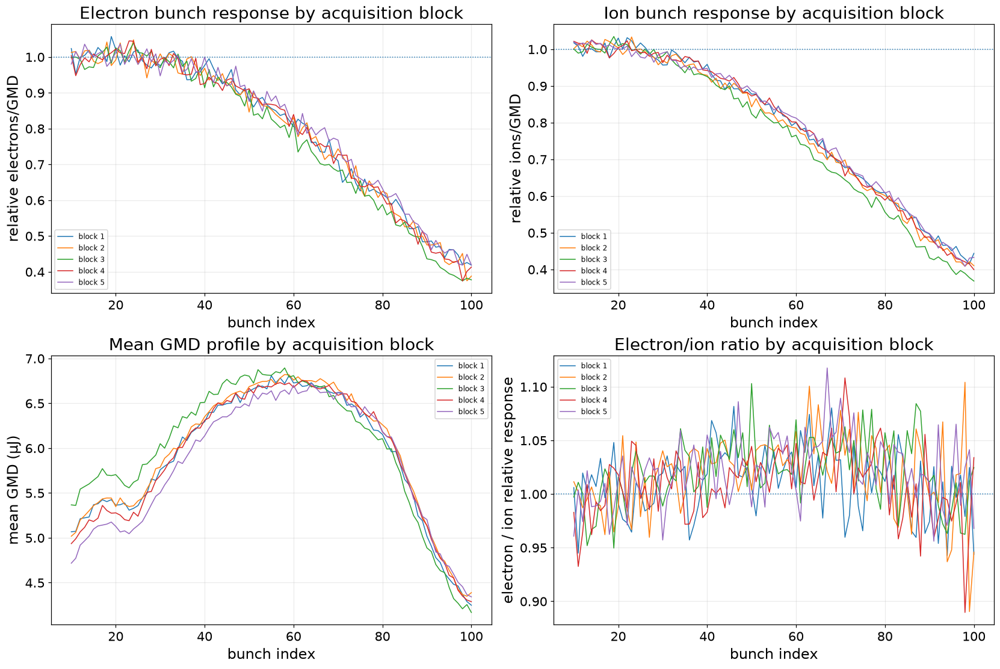

In [ ]:
# --- Bunch-response profiles separately for each acquisition block ---

bunch_axis = np.arange(INDEP_BUNCH_START,n_bunch)

def block_gmd_profile(counts,rows):
    valid = current_mask[rows]
    obs = np.sum(np.where(valid,counts[rows],0),axis=0)
    den = np.sum(np.where(valid,gmd[rows],0),axis=0)
    rate = np.divide(obs,den,out=np.full(n_bunch,np.nan),where=den > 0)
    norm = np.nanmean(rate[(np.arange(n_bunch) >= 10) & (np.arange(n_bunch) <= 30)])
    return rate/norm

fig,axes = plt.subplots(2,2,figsize=(15,10),constrained_layout=True)

for k in range(N_STATE_BLOCKS):
    rows_k = state_block == k
    e_prof = block_gmd_profile(data["total_electrons"],rows_k)
    i_prof = block_gmd_profile(ion_counts,rows_k)
    mean_g = np.nanmean(np.where(current_mask[rows_k],gmd[rows_k],np.nan),axis=0)
    ei = e_prof/i_prof

    axes[0,0].plot(bunch_axis,e_prof[bunch_axis],lw=1,label=f"block {k+1}")
    axes[0,1].plot(bunch_axis,i_prof[bunch_axis],lw=1,label=f"block {k+1}")
    axes[1,0].plot(bunch_axis,mean_g[bunch_axis],lw=1,label=f"block {k+1}")
    axes[1,1].plot(bunch_axis,ei[bunch_axis],lw=1,label=f"block {k+1}")

axes[0,0].axhline(1,ls=":",lw=1); axes[0,0].set(xlabel="bunch index",ylabel="relative electrons/GMD",title="Electron bunch response by acquisition block")
axes[0,1].axhline(1,ls=":",lw=1); axes[0,1].set(xlabel="bunch index",ylabel="relative ions/GMD",title="Ion bunch response by acquisition block")
axes[1,0].set(xlabel="bunch index",ylabel="mean GMD (µJ)",title="Mean GMD profile by acquisition block")
axes[1,1].axhline(1,ls=":",lw=1); axes[1,1].set(xlabel="bunch index",ylabel="electron / ion relative response",title="Electron/ion ratio by acquisition block")

for ax in axes.flat: ax.grid(alpha=0.25); ax.legend(fontsize=8)
plt.show()

,row start,row stop,row centre,history ΔR,effective matched,bunches used,H mean,H=0 fraction,H<=1 fraction,H>=3 fraction,hor_pos,ver_pos,mpe,mean GMD,mean electrons,mean ions,reference/GMD,between_tdc fraction
window,,,,,,,,,,,,,,,,,,
1,0,1771,885.5,0.10359,43439,91,2.33553,0.18675,0.40360,0.39560,-0.09581,-0.94162,275.02714,5.73383,0.44525,1.02919,0.00301,0.00000
2,1772,3543,2657.5,0.01781,40374,91,2.41428,0.18299,0.39569,0.40911,-0.04169,-0.88096,274.27348,5.92142,0.45513,1.01842,0.00284,0.00000
3,3544,5315,4429.5,0.09684,38256,91,2.51577,0.17193,0.37873,0.42908,-0.02042,-0.85639,274.01541,5.99568,0.46706,1.02816,0.00289,0.00000
4,5316,7087,6201.5,0.62639,42567,91,1.81735,0.41026,0.55200,0.31221,-0.00902,-0.83854,274.43167,5.98337,0.33813,0.72390,0.00203,0.29684
5,7088,8859,7973.5,1.07922,11130,89,0.53746,0.80944,0.86240,0.09000,-0.04636,-0.94476,274.03075,5.86777,0.09870,0.22756,0.00060,0.76693
6,8860,10631,9745.5,0.24097,38819,91,2.38829,0.19220,0.40328,0.40154,-0.01697,-0.88600,273.76698,6.10224,0.43828,1.00795,0.00280,0.00000
7,10632,12403,11517.5,0.16975,41950,91,2.38361,0.18634,0.40057,0.40329,-0.05265,-0.88754,273.86195,5.84584,0.44818,1.00363,0.00280,0.00000
8,12404,14175,13289.5,0.06072,39738,91,2.53140,0.17242,0.37868,0.43080,-0.01751,-0.85350,274.41006,6.03869,0.47353,1.03118,0.00278,0.00000
9,14176,15947,15061.5,0.36859,41158,91,2.26575,0.25080,0.44307,0.38283,-0.01603,-0.88330,274.09713,6.03977,0.42010,0.92422,0.00255,0.07844


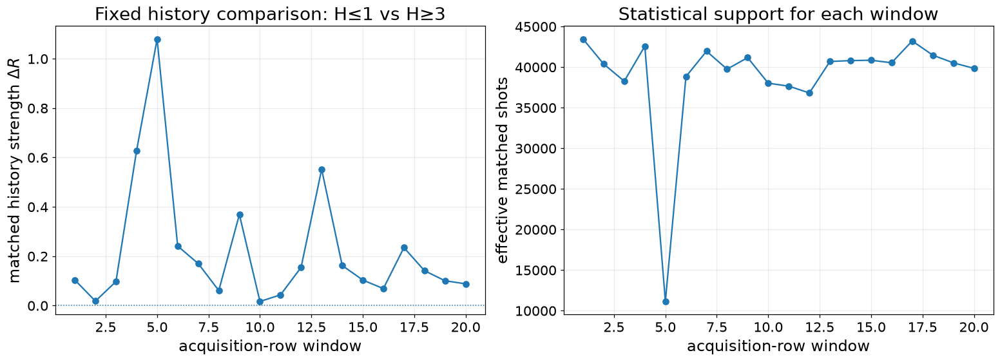

In [ ]:
# --- Fixed-definition history strength in smaller acquisition windows ---
# Use the SAME history categories everywhere so different windows are directly comparable.

N_STATE_WINDOWS = 20
HISTORY_LOW_MAX = 1
HISTORY_HIGH_MIN = 3
MATCH_GMD_STEP = 0.5
MIN_PER_GROUP = 5

gmd_edges_state = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+MATCH_GMD_STEP,MATCH_GMD_STEP)
window_indices = np.array_split(np.arange(n_trains),N_STATE_WINDOWS)
window_id = np.empty(n_trains,dtype=int)
for k,idx in enumerate(window_indices): window_id[idx] = k

def matched_history_delta_fixed(rows):
    deltas = []
    effective = 0

    for b in range(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch):
        valid = rows & current_mask[:,b] & np.isfinite(H_total[:,b]) & np.isfinite(ref_base_cv[:,b]) & (ref_base_cv[:,b] > 0)
        low = np.flatnonzero(valid & (H_total[:,b] <= HISTORY_LOW_MAX))
        high = np.flatnonzero(valid & (H_total[:,b] >= HISTORY_HIGH_MIN))
        if low.size < MIN_PER_GROUP or high.size < MIN_PER_GROUP: continue

        obs_lo = pred_lo = obs_hi = pred_hi = 0.0
        matched_b = 0

        for g_lo,g_hi in zip(gmd_edges_state[:-1],gmd_edges_state[1:]):
            il = low[(gmd[low,b] >= g_lo) & (gmd[low,b] < g_hi)]
            ih = high[(gmd[high,b] >= g_lo) & (gmd[high,b] < g_hi)]
            m = min(il.size,ih.size)
            if m < MIN_PER_GROUP: continue

            wlo,whi = m/il.size,m/ih.size
            obs_lo += wlo*data["ref_counts"][il,b].sum()
            pred_lo += wlo*ref_base_cv[il,b].sum()
            obs_hi += whi*data["ref_counts"][ih,b].sum()
            pred_hi += whi*ref_base_cv[ih,b].sum()
            matched_b += m

        if min(pred_lo,pred_hi) <= 0: continue
        deltas.append(obs_hi/pred_hi-obs_lo/pred_lo)
        effective += matched_b

    return (np.nanmean(deltas) if deltas else np.nan,effective,len(deltas))

window_rows = []

for k,idx in enumerate(window_indices):
    rows_k = np.zeros(n_trains,dtype=bool)
    rows_k[idx] = True

    delta,effective,n_bunch_used = matched_history_delta_fixed(rows_k)

    history_valid = rows_k[:,None] & current_mask & np.isfinite(H_total)
    h_values = H_total[history_valid]

    window_rows.append({
        "window":k+1,
        "row start":idx[0],
        "row stop":idx[-1],
        "row centre":np.mean(idx),
        "history ΔR":delta,
        "effective matched":effective,
        "bunches used":n_bunch_used,
        "H mean":np.nanmean(h_values),
        "H=0 fraction":np.mean(h_values == 0),
        "H<=1 fraction":np.mean(h_values <= HISTORY_LOW_MAX),
        "H>=3 fraction":np.mean(h_values >= HISTORY_HIGH_MIN),
        "hor_pos":np.nanmean(hor_pos[idx]),
        "ver_pos":np.nanmean(ver_pos[idx]),
        "mpe":np.nanmean(mpe[idx]),
        "mean GMD":np.nanmean(mean_gmd_train[idx]),
        "mean electrons":np.nanmean(mean_e_train[idx]),
        "mean ions":np.nanmean(mean_i_train[idx]),
        "reference/GMD":np.nanmean(ref_per_gmd_train[idx]),
        "between_tdc fraction":np.mean(between_tdc[idx])
    })

window_table_fixed = pd.DataFrame(window_rows).set_index("window")
display(window_table_fixed.round(5))

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

axes[0].plot(window_table_fixed.index,window_table_fixed["history ΔR"],"o-")
axes[0].axhline(0,ls=":",lw=1)
axes[0].set(xlabel="acquisition-row window",ylabel=r"matched history strength $\Delta R$",title=f"Fixed history comparison: H≤{HISTORY_LOW_MAX} vs H≥{HISTORY_HIGH_MIN}")
axes[0].grid(alpha=0.25)

axes[1].plot(window_table_fixed.index,window_table_fixed["effective matched"],"o-",label="effective matched shots")
axes[1].set(xlabel="acquisition-row window",ylabel="effective matched shots",title="Statistical support for each window")
axes[1].grid(alpha=0.25)

plt.show()

NameError: name 'window_table_fixed' is not defined

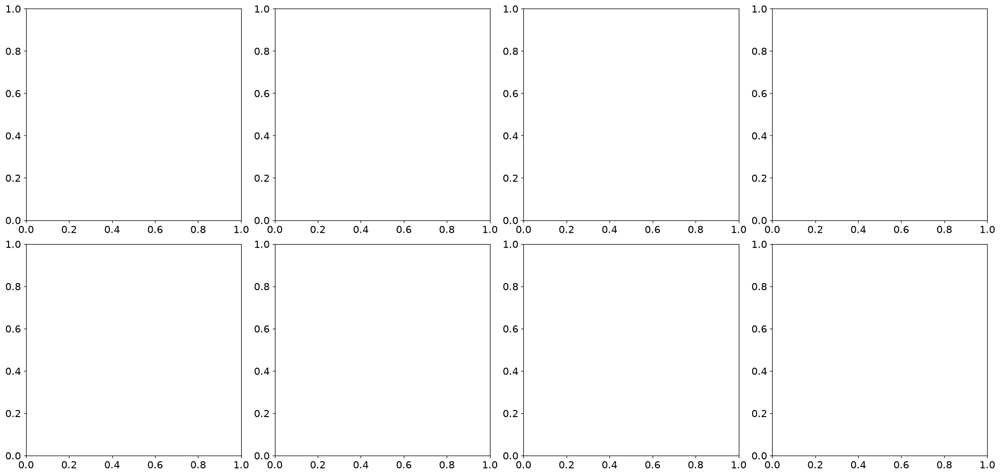

In [ ]:
# --- Correlate FIXED history-effect strength with candidate acquisition-state variables ---

from scipy.stats import pearsonr,spearmanr

CANDIDATES = ["row centre","hor_pos","ver_pos","mpe","mean GMD","mean electrons","mean ions","reference/GMD"]
corr_rows = []

fig,axes = plt.subplots(2,4,figsize=(19,9),constrained_layout=True)

for ax,name in zip(axes.flat,CANDIDATES):
    x = window_table_fixed[name].to_numpy(dtype=float)
    y = window_table_fixed["history ΔR"].to_numpy(dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)

    rp,pp = pearsonr(x[valid],y[valid]) if np.count_nonzero(valid) >= 3 else (np.nan,np.nan)
    rs,ps = spearmanr(x[valid],y[valid]) if np.count_nonzero(valid) >= 3 else (np.nan,np.nan)

    corr_rows.append({"variable":name,"Pearson r":rp,"Pearson p":pp,"Spearman rho":rs,"Spearman p":ps})

    ax.scatter(x[valid],y[valid],s=35)
    if np.count_nonzero(valid) >= 2:
        m,c = np.polyfit(x[valid],y[valid],1)
        xx = np.array([x[valid].min(),x[valid].max()])
        ax.plot(xx,m*xx+c,"--",lw=1)

    ax.axhline(0,ls=":",lw=1)
    ax.set_xlabel(name)
    ax.set_ylabel(r"fixed matched history strength $\Delta R$")
    ax.set_title(f"{name}\nPearson r={rp:+.2f}, Spearman ρ={rs:+.2f}")
    ax.grid(alpha=0.25)

plt.show()

corr_table_fixed = pd.DataFrame(corr_rows).set_index("variable")
display(corr_table_fixed.round(4))

,full Pearson r,LOO Pearson min,LOO Pearson max,full Spearman rho,LOO Spearman min,LOO Spearman max
variable,,,,,,
hor_pos,0.2107,0.1292,0.3957,0.1068,-0.0158,0.2421
mean GMD,0.1148,0.0273,0.3136,0.0586,-0.0561,0.1860
mean electrons,-0.9484,-0.9626,-0.8769,-0.6902,-0.8246,-0.6386
mean ions,-0.9633,-0.9709,-0.9297,-0.6451,-0.7719,-0.5860
reference/GMD,-0.9424,-0.9567,-0.8539,-0.4060,-0.5175,-0.3070


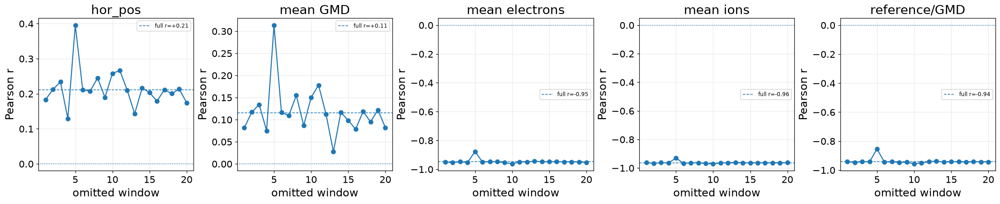

In [ ]:
# --- Leave-one-window-out robustness of acquisition-state correlations ---

ROBUSTNESS_VARS = ["hor_pos","mean GMD","mean electrons","mean ions","reference/GMD"]
loo_rows = []

for name in ROBUSTNESS_VARS:
    x = window_table_fixed[name].to_numpy(dtype=float)
    y = window_table_fixed["history ΔR"].to_numpy(dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    valid_idx = np.flatnonzero(valid)

    full_r = pearsonr(x[valid],y[valid])[0]
    full_rho = spearmanr(x[valid],y[valid])[0]

    loo_r,loo_rho,omitted = [],[],[]
    for drop in valid_idx:
        keep = valid.copy()
        keep[drop] = False
        if np.count_nonzero(keep) < 3: continue
        loo_r.append(pearsonr(x[keep],y[keep])[0])
        loo_rho.append(spearmanr(x[keep],y[keep])[0])
        omitted.append(window_table_fixed.index[drop])

    loo_rows.append({"variable":name,"full Pearson r":full_r,"LOO Pearson min":np.min(loo_r),"LOO Pearson max":np.max(loo_r),
                     "full Spearman rho":full_rho,"LOO Spearman min":np.min(loo_rho),"LOO Spearman max":np.max(loo_rho)})

robustness_table = pd.DataFrame(loo_rows).set_index("variable")
display(robustness_table.round(4))

fig,axes = plt.subplots(1,len(ROBUSTNESS_VARS),figsize=(20,4),constrained_layout=True)

for ax,name in zip(axes,ROBUSTNESS_VARS):
    x = window_table_fixed[name].to_numpy(dtype=float)
    y = window_table_fixed["history ΔR"].to_numpy(dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    valid_idx = np.flatnonzero(valid)
    full_r = pearsonr(x[valid],y[valid])[0]

    omitted,loo_r = [],[]
    for drop in valid_idx:
        keep = valid.copy()
        keep[drop] = False
        omitted.append(window_table_fixed.index[drop])
        loo_r.append(pearsonr(x[keep],y[keep])[0])

    ax.plot(omitted,loo_r,"o-")
    ax.axhline(full_r,ls="--",lw=1,label=f"full r={full_r:+.2f}")
    ax.axhline(0,ls=":",lw=1)
    ax.set(xlabel="omitted window",ylabel="Pearson r",title=name)
    ax.grid(alpha=0.25); ax.legend(fontsize=8)

plt.show()

,row start,row stop,history ΔR,effective matched,mean GMD,mean electrons,mean ions,reference/GMD,mean H,H=0 fraction,H<=1 fraction,H>=3 fraction,between_tdc fraction,DAQ-running fraction,hor_pos,ver_pos,mpe
window,,,,,,,,,,,,,,,,,
3,3544,5315,0.09684,38256,5.99568,0.46706,1.02816,0.00289,2.51577,0.17193,0.37873,0.42908,0.00000,1.00000,-0.02042,-0.85639,274.01541
4,5316,7087,0.62639,42567,5.98337,0.33813,0.72390,0.00203,1.81735,0.41026,0.55200,0.31221,0.29684,0.70372,-0.00902,-0.83854,274.43167
5,7088,8859,1.07922,11130,5.86777,0.09870,0.22756,0.00060,0.53746,0.80944,0.86240,0.09000,0.76693,0.23420,-0.04636,-0.94476,274.03075
12,19492,21263,0.15434,36808,5.90132,0.46874,1.02024,0.00283,2.52992,0.17783,0.37960,0.43158,0.00000,1.00000,-0.04337,-0.94631,274.40768
13,21264,23035,0.55153,40683,6.07215,0.32457,0.72600,0.00198,1.76713,0.41471,0.56564,0.29927,0.27822,0.72348,-0.00817,-0.87861,274.53401
14,23036,24807,0.16194,40789,5.93434,0.45002,1.02828,0.00298,2.41383,0.18034,0.39363,0.40890,0.00000,1.00000,-0.03086,-0.85799,274.14168


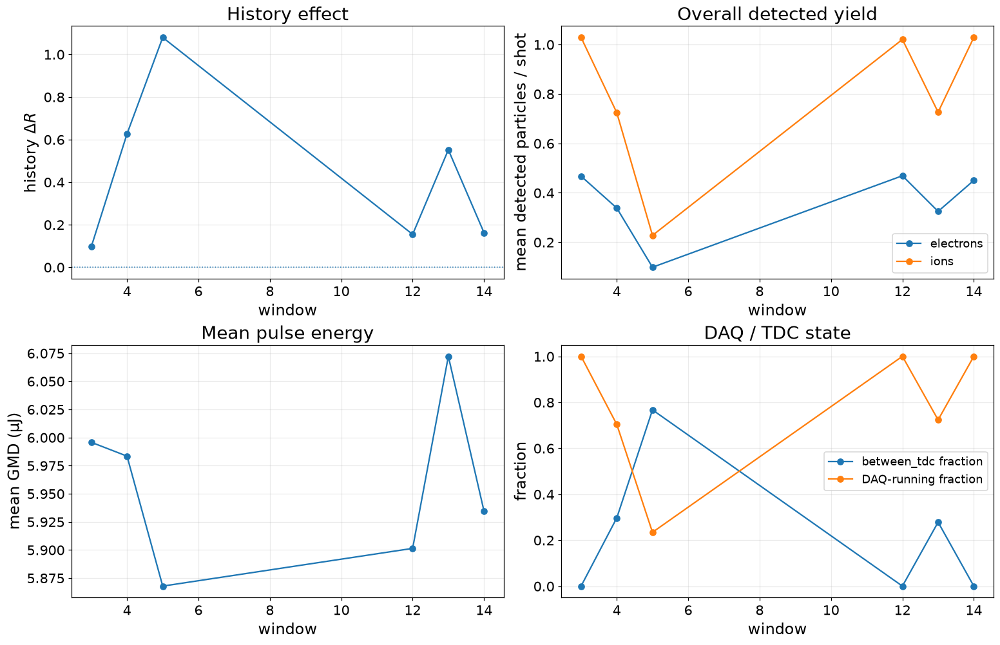

In [ ]:
# --- Inspect unusual acquisition windows in detail ---

WINDOWS_TO_INSPECT = [3,4,5,12,13,14]

with h5py.File(source_h5,"r") as handle:
    local_daq = handle["local_DAQ_running"][:n_trains].astype(bool) if "local_DAQ_running" in handle else np.ones(n_trains,dtype=bool)

inspect_rows = []

for w in WINDOWS_TO_INSPECT:
    idx = window_indices[w-1]
    hmask = np.zeros(n_trains,dtype=bool)
    hmask[idx] = True
    valid_h = hmask[:,None] & current_mask & np.isfinite(H_total)
    h = H_total[valid_h]

    inspect_rows.append({
        "window":w,
        "row start":idx[0],
        "row stop":idx[-1],
        "history ΔR":window_table_fixed.loc[w,"history ΔR"],
        "effective matched":window_table_fixed.loc[w,"effective matched"],
        "mean GMD":np.nanmean(mean_gmd_train[idx]),
        "mean electrons":np.nanmean(mean_e_train[idx]),
        "mean ions":np.nanmean(mean_i_train[idx]),
        "reference/GMD":np.nanmean(ref_per_gmd_train[idx]),
        "mean H":np.nanmean(h),
        "H=0 fraction":np.mean(h == 0),
        "H<=1 fraction":np.mean(h <= HISTORY_LOW_MAX),
        "H>=3 fraction":np.mean(h >= HISTORY_HIGH_MIN),
        "between_tdc fraction":np.mean(between_tdc[idx]),
        "DAQ-running fraction":np.mean(local_daq[idx]),
        "hor_pos":np.nanmean(hor_pos[idx]),
        "ver_pos":np.nanmean(ver_pos[idx]),
        "mpe":np.nanmean(mpe[idx])
    })

inspect_table = pd.DataFrame(inspect_rows).set_index("window")
display(inspect_table.round(5))

fig,axes = plt.subplots(2,2,figsize=(14,9),constrained_layout=True)
x = inspect_table.index

axes[0,0].plot(x,inspect_table["history ΔR"],"o-")
axes[0,0].axhline(0,ls=":",lw=1)
axes[0,0].set(xlabel="window",ylabel=r"history $\Delta R$",title="History effect")
axes[0,0].grid(alpha=0.25)

axes[0,1].plot(x,inspect_table["mean electrons"],"o-",label="electrons")
axes[0,1].plot(x,inspect_table["mean ions"],"o-",label="ions")
axes[0,1].set(xlabel="window",ylabel="mean detected particles / shot",title="Overall detected yield")
axes[0,1].grid(alpha=0.25); axes[0,1].legend()

axes[1,0].plot(x,inspect_table["mean GMD"],"o-")
axes[1,0].set(xlabel="window",ylabel="mean GMD (µJ)",title="Mean pulse energy")
axes[1,0].grid(alpha=0.25)

axes[1,1].plot(x,inspect_table["between_tdc fraction"],"o-",label="between_tdc fraction")
axes[1,1].plot(x,inspect_table["DAQ-running fraction"],"o-",label="DAQ-running fraction")
axes[1,1].set(xlabel="window",ylabel="fraction",title="DAQ / TDC state")
axes[1,1].grid(alpha=0.25); axes[1,1].legend()

plt.show()

### Further tuning/comparison of the model

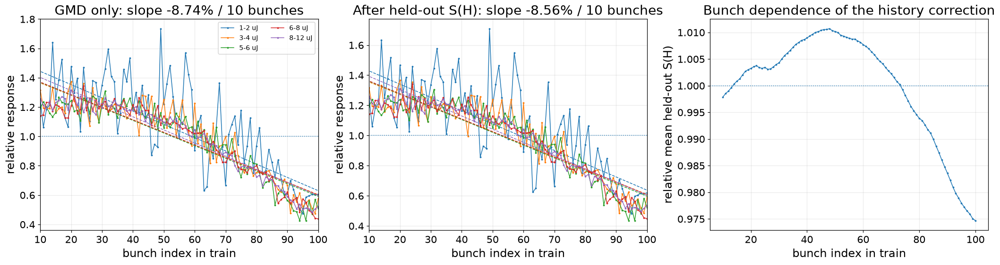

GMD only:             slope=-8.740% / 10 bunches, flatness=0.24765
After held-out S(H):  slope=-8.559% / 10 bunches, flatness=0.24174
Slope change:         +0.181% / 10 bunches
Change in |slope|:    +2.07%


In [ ]:
# --- Direct test: does removing held-out S(H) change the bunch-position dependence? ---

# target_state_blockcv / target_base_cv is exactly the S(H) factor predicted by a model
# that was trained without the acquisition block containing the current shot.
state_factor_blockcv = np.divide(target_state_blockcv,target_base_cv,out=np.full_like(gmd,np.nan,dtype=float),
                                 where=np.isfinite(target_state_blockcv) & np.isfinite(target_base_cv) & (target_base_cv > 0))

# Use exactly the same target shots before and after S correction.
state_test_mask = current_mask & np.isfinite(H_total) & np.isfinite(state_factor_blockcv) & (state_factor_blockcv > 0)

target_obs = band_sums(data["target_counts"].astype(float),gmd,state_test_mask)
target_shots = band_sums(np.ones_like(gmd),gmd,state_test_mask)
target_gmd_norm = band_sums(gmd,gmd,state_test_mask)
target_state_norm = band_sums(gmd*state_factor_blockcv,gmd,state_test_mask)

m_target_gmd = bunch_metrics(target_obs,target_gmd_norm,target_shots)
m_target_state = bunch_metrics(target_obs,target_state_norm,target_shots)

mean_state = np.array([np.nanmean(state_factor_blockcv[state_test_mask[:,b],b]) if np.any(state_test_mask[:,b]) else np.nan for b in range(n_bunch)])
mean_state /= np.nanmean(mean_state[INDEP_BUNCH_START:])

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)
plot_bunch_response(m_target_gmd,f"GMD only: slope {m_target_gmd['slope']:+.2f}% / 10 bunches",axes[0])
plot_bunch_response(m_target_state,f"After held-out S(H): slope {m_target_state['slope']:+.2f}% / 10 bunches",axes[1])
axes[0].legend(ncol=2,fontsize=9)

b = np.arange(INDEP_BUNCH_START,n_bunch)
axes[2].plot(b,mean_state[b],".-",ms=3,lw=1)
axes[2].axhline(1,ls=":",lw=1)
axes[2].set(xlabel="bunch index in train",ylabel="relative mean held-out S(H)",title="Bunch dependence of the history correction")
axes[2].grid(alpha=0.25)
plt.show()

slope_change = m_target_state["slope"]-m_target_gmd["slope"]
magnitude_change = 100*(abs(m_target_gmd["slope"])-abs(m_target_state["slope"]))/abs(m_target_gmd["slope"])

print(f"GMD only:             slope={m_target_gmd['slope']:+.3f}% / 10 bunches, flatness={m_target_gmd['flatness']:.5f}")
print(f"After held-out S(H):  slope={m_target_state['slope']:+.3f}% / 10 bunches, flatness={m_target_state['flatness']:.5f}")
print(f"Slope change:         {slope_change:+.3f}% / 10 bunches")
print(f"Change in |slope|:    {magnitude_change:+.2f}%")

## Testing DAQ

In [ ]:
# --- DAQ/TDC sanity check: flag relation and detected yield ---

with h5py.File(source_h5,"r") as handle:
    local_daq = handle["local_DAQ_running"][:n_trains].astype(bool)
    between_tdc = handle["between_tdc_files"][:n_trains].astype(bool)

daq_valid_rows = local_daq & ~between_tdc
flag_agreement = np.mean(between_tdc == ~local_daq)

groups = {"valid: DAQ running, not between TDC files":daq_valid_rows,"DAQ not running":~local_daq,"between TDC files":between_tdc}
rows = []
for name,row_mask in groups.items():
    shot_mask = row_mask[:,None] & current_mask_base
    rows.append({"state":name,"trains":row_mask.sum(),"fraction of trains":row_mask.mean(),"mean GMD":np.nanmean(gmd[shot_mask]),"mean electrons / shot":data["total_electrons"][shot_mask].mean(),"mean ions / shot":ion_counts[shot_mask].mean(),"reference / GMD":data["ref_counts"][shot_mask].sum()/gmd[shot_mask].sum()})
daq_state_table = pd.DataFrame(rows).set_index("state")
display(daq_state_table.round(5))

flag_table = pd.crosstab(pd.Series(local_daq,name="local_DAQ_running"),pd.Series(between_tdc,name="between_tdc_files"))
display(flag_table)

print(f"between_tdc_files == ~local_DAQ_running: {flag_agreement:.3%}")
print(f"Conservative valid-train fraction:       {daq_valid_rows.mean():.3%}")

fig,ax = plt.subplots(figsize=(9,5))
x = np.arange(len(daq_state_table))
ax.plot(x,daq_state_table["mean electrons / shot"],"o-",label="electrons")
ax.plot(x,daq_state_table["mean ions / shot"],"o-",label="ions")
ax.set_xticks(x,["valid","DAQ not running","between TDC files"])
ax.set(xlabel="acquisition state",ylabel="mean detected particles / shot",title="Detected yield by DAQ/TDC state")
ax.grid(alpha=0.25); ax.legend()
plt.show()

NameError: name 'ion_counts' is not defined

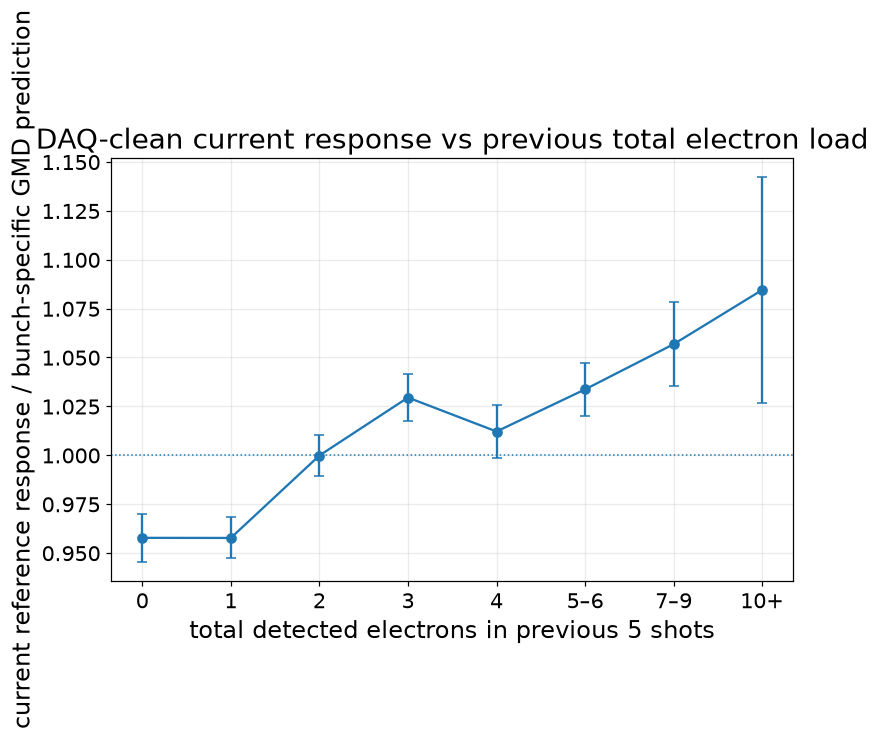

history   0: response=0.9577 ± 0.0124, shots=470,001
history   1: response=0.9577 ± 0.0105, shots=548,703
history   2: response=0.9998 ± 0.0107, shots=509,826
history   3: response=1.0295 ± 0.0119, shots=401,668
history   4: response=1.0121 ± 0.0137, shots=283,962
history 5–6: response=1.0337 ± 0.0134, shots=293,651
history 7–9: response=1.0568 ± 0.0214, shots=112,509
history 10+: response=1.0845 ± 0.0577, shots=15,395


In [ ]:
# --- DAQ-clean bunch-specific GMD baseline and raw history dose-response ---

HISTORY_SHOTS = 5
H_total_clean = np.full_like(gmd,np.nan,dtype=float)
for b in range(HISTORY_SHOTS,n_bunch): H_total_clean[:,b] = data["total_electrons"][:,b-HISTORY_SHOTS:b].sum(axis=1)

ref_base_clean_cv = np.full_like(gmd,np.nan,dtype=float)
target_base_clean_cv = np.full_like(gmd,np.nan,dtype=float)

for off in INDEP_CV_OFFSETS:
    train_rows = daq_valid_rows & (train_ids % INDEP_CV_MOD != off)
    test_rows = daq_valid_rows & (train_ids % INDEP_CV_MOD == off)
    _,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],current_mask[train_rows])
    _,target_beta = fit_bunch_baseline(gmd[train_rows],data["target_counts"][train_rows],current_mask[train_rows])
    ref_base_clean_cv[test_rows] = apply_bunch_baseline(gmd[test_rows],ref_beta)
    target_base_clean_cv[test_rows] = apply_bunch_baseline(gmd[test_rows],target_beta)

HISTORY_BINS = [(0,0),(1,1),(2,2),(3,3),(4,4),(5,6),(7,9),(10,np.inf)]
HISTORY_LABELS = ["0","1","2","3","4","5–6","7–9","10+"]
response_clean,response_err_clean,n_shots_clean = [],[],[]
valid_clean = daq_valid_rows[:,None] & current_mask & np.isfinite(H_total_clean) & np.isfinite(ref_base_clean_cv) & (ref_base_clean_cv > 0)

for lo,hi in HISTORY_BINS:
    use = valid_clean & (H_total_clean >= lo) & (H_total_clean <= hi)
    obs = data["ref_counts"][use].sum()
    pred = ref_base_clean_cv[use].sum()
    response_clean.append(obs/pred if pred > 0 else np.nan)
    response_err_clean.append(np.sqrt(obs)/pred if obs > 0 and pred > 0 else np.nan)
    n_shots_clean.append(np.count_nonzero(use))

fig,ax = plt.subplots(figsize=(8,5))
x = np.arange(len(HISTORY_LABELS))
ax.errorbar(x,response_clean,yerr=response_err_clean,fmt="o-",capsize=3)
ax.axhline(1,ls=":",lw=1)
ax.set_xticks(x,HISTORY_LABELS)
ax.set(xlabel=f"total detected electrons in previous {HISTORY_SHOTS} shots",ylabel="current reference response / bunch-specific GMD prediction",title="DAQ-clean current response vs previous total electron load")
ax.grid(alpha=0.25)
plt.show()

for label,r,e,n in zip(HISTORY_LABELS,response_clean,response_err_clean,n_shots_clean): print(f"history {label:>3s}: response={r:.4f} ± {e:.4f}, shots={n:,}")

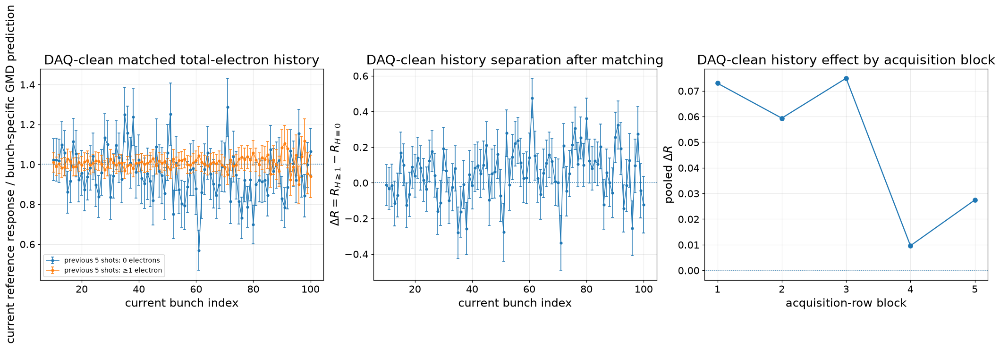

Overall matched H=0 response:  0.9580
Overall matched H>=1 response: 1.0070
Overall matched ΔR:            +0.0490 ± 0.0139
Effective matched shots/group: 461,930
Block ΔR: [0.073  0.0594 0.0749 0.0096 0.0274]


In [ ]:
# --- DAQ-clean matched total-electron history ---

N_CLEAN_BLOCKS = 5
MATCH_GMD_STEP = 1.0
MIN_PER_GROUP = 5
clean_block_id = np.empty(n_trains,dtype=int)
for k,idx in enumerate(np.array_split(np.arange(n_trains),N_CLEAN_BLOCKS)): clean_block_id[idx] = k

gmd_edges_clean = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+MATCH_GMD_STEP,MATCH_GMD_STEP)
bunches_clean_hist = np.arange(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch)

def matched_total_history_clean(blocks=None):
    if blocks is None: blocks = np.arange(N_CLEAN_BLOCKS)
    obs0 = np.zeros(n_bunch); pred0 = np.zeros(n_bunch); var0 = np.zeros(n_bunch)
    obs1 = np.zeros(n_bunch); pred1 = np.zeros(n_bunch); var1 = np.zeros(n_bunch); effective = np.zeros(n_bunch)
    for b in bunches_clean_hist:
        base_valid = daq_valid_rows & current_mask[:,b] & np.isfinite(H_total_clean[:,b]) & np.isfinite(ref_base_clean_cv[:,b]) & (ref_base_clean_cv[:,b] > 0)
        for block in blocks:
            for lo,hi in zip(gmd_edges_clean[:-1],gmd_edges_clean[1:]):
                use = base_valid & (clean_block_id == block) & (gmd[:,b] >= lo) & (gmd[:,b] < hi)
                idx0 = np.flatnonzero(use & (H_total_clean[:,b] == 0))
                idx1 = np.flatnonzero(use & (H_total_clean[:,b] >= 1))
                m = min(idx0.size,idx1.size)
                if m < MIN_PER_GROUP: continue
                w0,w1 = m/idx0.size,m/idx1.size
                y0 = data["ref_counts"][idx0,b].astype(float); y1 = data["ref_counts"][idx1,b].astype(float)
                obs0[b] += w0*y0.sum(); pred0[b] += w0*ref_base_clean_cv[idx0,b].sum(); var0[b] += w0**2*y0.sum()
                obs1[b] += w1*y1.sum(); pred1[b] += w1*ref_base_clean_cv[idx1,b].sum(); var1[b] += w1**2*y1.sum(); effective[b] += m
    R0 = np.divide(obs0,pred0,out=np.full(n_bunch,np.nan),where=pred0 > 0); R1 = np.divide(obs1,pred1,out=np.full(n_bunch,np.nan),where=pred1 > 0)
    E0 = np.divide(np.sqrt(var0),pred0,out=np.full(n_bunch,np.nan),where=pred0 > 0); E1 = np.divide(np.sqrt(var1),pred1,out=np.full(n_bunch,np.nan),where=pred1 > 0)
    pooled0 = obs0.sum()/pred0.sum(); pooled1 = obs1.sum()/pred1.sum()
    pooled_e0 = np.sqrt(var0.sum())/pred0.sum(); pooled_e1 = np.sqrt(var1.sum())/pred1.sum()
    return {"R0":R0,"R1":R1,"E0":E0,"E1":E1,"delta":R1-R0,"delta_err":np.sqrt(E0**2+E1**2),"effective":effective,"pooled0":pooled0,"pooled1":pooled1,"pooled_delta":pooled1-pooled0,"pooled_delta_err":np.sqrt(pooled_e0**2+pooled_e1**2)}

matched_clean = matched_total_history_clean()
block_delta_clean = [matched_total_history_clean([block])["pooled_delta"] for block in range(N_CLEAN_BLOCKS)]

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)
axes[0].errorbar(bunches_clean_hist,matched_clean["R0"][bunches_clean_hist],yerr=matched_clean["E0"][bunches_clean_hist],fmt="o-",ms=3,lw=1,capsize=2,label=f"previous {HISTORY_SHOTS} shots: 0 electrons")
axes[0].errorbar(bunches_clean_hist,matched_clean["R1"][bunches_clean_hist],yerr=matched_clean["E1"][bunches_clean_hist],fmt="o-",ms=3,lw=1,capsize=2,label=f"previous {HISTORY_SHOTS} shots: ≥1 electron")
axes[0].axhline(1,ls=":",lw=1); axes[0].set(xlabel="current bunch index",ylabel="current reference response / bunch-specific GMD prediction",title="DAQ-clean matched total-electron history"); axes[0].grid(alpha=0.25); axes[0].legend(fontsize=9)
axes[1].errorbar(bunches_clean_hist,matched_clean["delta"][bunches_clean_hist],yerr=matched_clean["delta_err"][bunches_clean_hist],fmt="o-",ms=3,lw=1,capsize=2)
axes[1].axhline(0,ls=":",lw=1); axes[1].set(xlabel="current bunch index",ylabel=r"$\Delta R=R_{H\geq1}-R_{H=0}$",title="DAQ-clean history separation after matching"); axes[1].grid(alpha=0.25)
axes[2].plot(np.arange(1,N_CLEAN_BLOCKS+1),block_delta_clean,"o-")
axes[2].axhline(0,ls=":",lw=1); axes[2].set_xticks(np.arange(1,N_CLEAN_BLOCKS+1)); axes[2].set(xlabel="acquisition-row block",ylabel=r"pooled $\Delta R$",title="DAQ-clean history effect by acquisition block"); axes[2].grid(alpha=0.25)
plt.show()

print(f"Overall matched H=0 response:  {matched_clean['pooled0']:.4f}")
print(f"Overall matched H>=1 response: {matched_clean['pooled1']:.4f}")
print(f"Overall matched ΔR:            {matched_clean['pooled_delta']:+.4f} ± {matched_clean['pooled_delta_err']:.4f}")
print(f"Effective matched shots/group: {matched_clean['effective'].sum():,.0f}")
print("Block ΔR:",np.round(block_delta_clean,4))

,c,beta_jump,beta_load,success
fold,,,,
0,-0.04436,-0.03714,0.06676,True
1,-0.04697,-0.03145,0.06475,True
2,-0.04259,-0.02808,0.05843,True
3,-0.04213,-0.04429,0.07011,True
4,-0.03985,-0.02349,0.05257,True


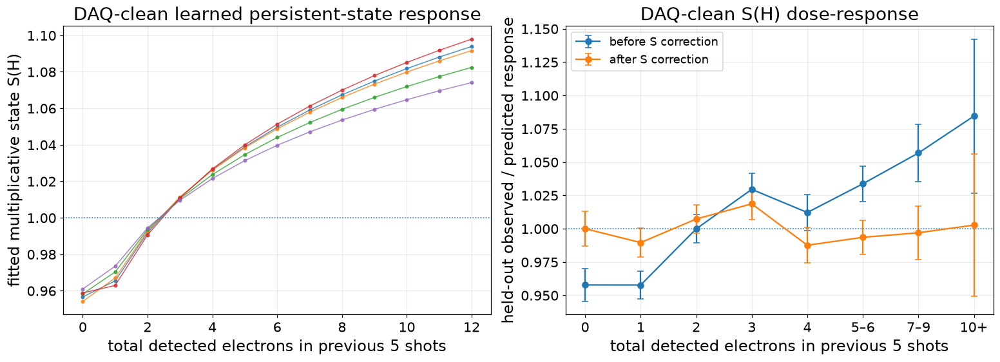

Reference held-out deviance: 353618.95 -> 353577.41 (+0.012% improvement)
Target held-out deviance:    1114284.87 -> 1114090.97 (+0.017% improvement)


In [ ]:
# --- DAQ-clean S(H) fit with held-out train folds ---

state_fits_clean = []
ref_state_clean_cv = np.full_like(gmd,np.nan,dtype=float)
target_state_clean_cv = np.full_like(gmd,np.nan,dtype=float)

for off in INDEP_CV_OFFSETS:
    train_rows = daq_valid_rows & (train_ids % INDEP_CV_MOD != off)
    test_rows = daq_valid_rows & (train_ids % INDEP_CV_MOD == off)
    ref_base_train,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],current_mask[train_rows])
    target_base_train,target_beta = fit_bunch_baseline(gmd[train_rows],data["target_counts"][train_rows],current_mask[train_rows])
    ref_base_test = apply_bunch_baseline(gmd[test_rows],ref_beta)
    target_base_test = apply_bunch_baseline(gmd[test_rows],target_beta)
    H_train,H_test = H_total_clean[train_rows],H_total_clean[test_rows]
    y_train = data["ref_counts"][train_rows].astype(float)
    fit_mask = current_mask[train_rows] & np.isfinite(H_train) & np.isfinite(ref_base_train) & (ref_base_train > 0)
    result = minimize(poisson_nll,x0=np.zeros(3),args=(y_train[fit_mask],ref_base_train[fit_mask],H_train[fit_mask]),method="L-BFGS-B",bounds=[(-2,2),(-2,2),(-2,2)])
    p = result.x
    state_fits_clean.append({"fold":off,"c":p[0],"beta_jump":p[1],"beta_load":p[2],"success":result.success})
    ref_base_clean_cv[test_rows] = ref_base_test
    target_base_clean_cv[test_rows] = target_base_test
    ref_state_clean_cv[test_rows] = ref_base_test*state_response(H_test,p)
    target_state_clean_cv[test_rows] = target_base_test*state_response(H_test,p)

state_table_clean = pd.DataFrame(state_fits_clean).set_index("fold")
display(state_table_clean.round(5))

valid_ref_clean = daq_valid_rows[:,None] & current_mask & np.isfinite(H_total_clean) & np.isfinite(ref_base_clean_cv) & (ref_base_clean_cv > 0) & np.isfinite(ref_state_clean_cv) & (ref_state_clean_cv > 0)
valid_target_clean = daq_valid_rows[:,None] & current_mask & np.isfinite(H_total_clean) & np.isfinite(target_base_clean_cv) & (target_base_clean_cv > 0) & np.isfinite(target_state_clean_cv) & (target_state_clean_cv > 0)

ref_dev0_clean = poisson_deviance(data["ref_counts"][valid_ref_clean],ref_base_clean_cv[valid_ref_clean])
ref_dev1_clean = poisson_deviance(data["ref_counts"][valid_ref_clean],ref_state_clean_cv[valid_ref_clean])
target_dev0_clean = poisson_deviance(data["target_counts"][valid_target_clean],target_base_clean_cv[valid_target_clean])
target_dev1_clean = poisson_deviance(data["target_counts"][valid_target_clean],target_state_clean_cv[valid_target_clean])

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
h_plot = np.arange(13)
for _,fit in state_table_clean.iterrows():
    p = np.array([fit["c"],fit["beta_jump"],fit["beta_load"]])
    axes[0].plot(h_plot,state_response(h_plot,p),"o-",ms=3,lw=1,alpha=0.8)
axes[0].axhline(1,ls=":",lw=1); axes[0].set(xlabel=f"total detected electrons in previous {HISTORY_SHOTS} shots",ylabel="fitted multiplicative state S(H)",title="DAQ-clean learned persistent-state response"); axes[0].grid(alpha=0.25)

before_clean,after_clean,before_err_clean,after_err_clean = [],[],[],[]
for lo,hi in HISTORY_BINS:
    use = valid_ref_clean & (H_total_clean >= lo) & (H_total_clean <= hi)
    y = data["ref_counts"][use].astype(float); mu0 = ref_base_clean_cv[use]; mu1 = ref_state_clean_cv[use]
    before_clean.append(y.sum()/mu0.sum()); after_clean.append(y.sum()/mu1.sum())
    before_err_clean.append(np.sqrt(y.sum())/mu0.sum()); after_err_clean.append(np.sqrt(y.sum())/mu1.sum())
x = np.arange(len(HISTORY_LABELS))
axes[1].errorbar(x,before_clean,yerr=before_err_clean,fmt="o-",capsize=3,label="before S correction")
axes[1].errorbar(x,after_clean,yerr=after_err_clean,fmt="o-",capsize=3,label="after S correction")
axes[1].axhline(1,ls=":",lw=1); axes[1].set_xticks(x,HISTORY_LABELS); axes[1].set(xlabel=f"total detected electrons in previous {HISTORY_SHOTS} shots",ylabel="held-out observed / predicted response",title="DAQ-clean S(H) dose-response"); axes[1].grid(alpha=0.25); axes[1].legend()
plt.show()

print(f"Reference held-out deviance: {ref_dev0_clean:.2f} -> {ref_dev1_clean:.2f} ({100*(1-ref_dev1_clean/ref_dev0_clean):+.3f}% improvement)")
print(f"Target held-out deviance:    {target_dev0_clean:.2f} -> {target_dev1_clean:.2f} ({100*(1-target_dev1_clean/target_dev0_clean):+.3f}% improvement)")

,c,beta_jump,beta_load,ref deviance improvement (%),target deviance improvement (%),matched ΔR before,matched ΔR after
held-out block,,,,,,,
1,-0.03779,-0.05010,0.07066,0.00310,0.01592,0.06326,-0.00417
2,-0.04218,-0.02691,0.05700,0.02301,0.01831,0.12575,0.06837
3,-0.03743,-0.04426,0.06620,0.01694,0.02426,0.07287,0.01374
4,-0.05054,-0.02045,0.05955,0.00980,0.02685,0.08020,0.01330
5,-0.04755,-0.02311,0.05908,0.00799,0.00411,0.10115,0.03169


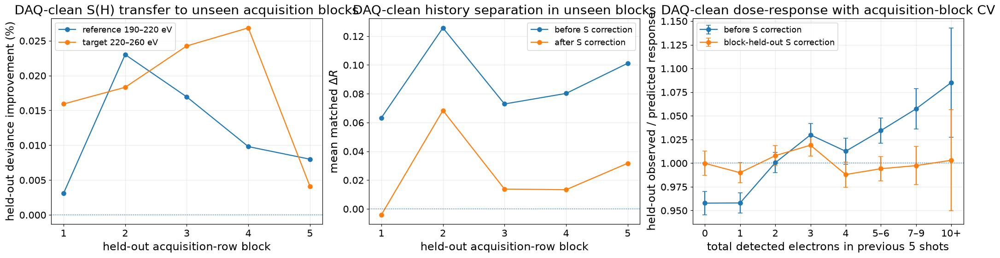

In [ ]:
# --- Strict DAQ-clean acquisition-block CV of S(H) ---

MATCH_GMD_STEP = 0.5
MIN_PER_GROUP = 5
ref_base_clean_blockcv = np.full_like(gmd,np.nan,dtype=float)
target_base_clean_blockcv = np.full_like(gmd,np.nan,dtype=float)
ref_state_clean_blockcv = np.full_like(gmd,np.nan,dtype=float)
target_state_clean_blockcv = np.full_like(gmd,np.nan,dtype=float)
clean_block_rows = []

def matched_delta_clean(rows,base_pred,state_pred):
    before,after = [],[]
    edges = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+MATCH_GMD_STEP,MATCH_GMD_STEP)
    for b in range(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch):
        valid = rows & daq_valid_rows & current_mask[:,b] & np.isfinite(H_total_clean[:,b]) & np.isfinite(base_pred[:,b]) & (base_pred[:,b] > 0) & np.isfinite(state_pred[:,b]) & (state_pred[:,b] > 0)
        low = np.flatnonzero(valid & (H_total_clean[:,b] <= 1))
        high = np.flatnonzero(valid & (H_total_clean[:,b] >= 3))
        if low.size < MIN_PER_GROUP or high.size < MIN_PER_GROUP: continue
        obs_lo = pred_lo = state_lo = obs_hi = pred_hi = state_hi = 0.0
        for lo,hi in zip(edges[:-1],edges[1:]):
            il = low[(gmd[low,b] >= lo) & (gmd[low,b] < hi)]; ih = high[(gmd[high,b] >= lo) & (gmd[high,b] < hi)]
            m = min(il.size,ih.size)
            if m < MIN_PER_GROUP: continue
            wlo,whi = m/il.size,m/ih.size
            obs_lo += wlo*data["ref_counts"][il,b].sum(); pred_lo += wlo*base_pred[il,b].sum(); state_lo += wlo*state_pred[il,b].sum()
            obs_hi += whi*data["ref_counts"][ih,b].sum(); pred_hi += whi*base_pred[ih,b].sum(); state_hi += whi*state_pred[ih,b].sum()
        if min(pred_lo,pred_hi,state_lo,state_hi) <= 0: continue
        before.append(obs_hi/pred_hi-obs_lo/pred_lo); after.append(obs_hi/state_hi-obs_lo/state_lo)
    return np.nanmean(before),np.nanmean(after)

for held_block in range(N_CLEAN_BLOCKS):
    train_rows = daq_valid_rows & (clean_block_id != held_block)
    test_rows = daq_valid_rows & (clean_block_id == held_block)
    ref_base_train,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],current_mask[train_rows])
    target_base_train,target_beta = fit_bunch_baseline(gmd[train_rows],data["target_counts"][train_rows],current_mask[train_rows])
    ref_base_clean_blockcv[test_rows] = apply_bunch_baseline(gmd[test_rows],ref_beta)
    target_base_clean_blockcv[test_rows] = apply_bunch_baseline(gmd[test_rows],target_beta)
    H_train = H_total_clean[train_rows]
    fit_mask = current_mask[train_rows] & np.isfinite(H_train) & np.isfinite(ref_base_train) & (ref_base_train > 0)
    result = minimize(poisson_nll,x0=np.zeros(3),args=(data["ref_counts"][train_rows][fit_mask].astype(float),ref_base_train[fit_mask],H_train[fit_mask]),method="L-BFGS-B",bounds=[(-2,2),(-2,2),(-2,2)])
    p = result.x
    ref_state_clean_blockcv[test_rows] = ref_base_clean_blockcv[test_rows]*state_response(H_total_clean[test_rows],p)
    target_state_clean_blockcv[test_rows] = target_base_clean_blockcv[test_rows]*state_response(H_total_clean[test_rows],p)
    ref_valid = test_rows[:,None] & current_mask & np.isfinite(H_total_clean) & np.isfinite(ref_base_clean_blockcv) & (ref_base_clean_blockcv > 0) & np.isfinite(ref_state_clean_blockcv) & (ref_state_clean_blockcv > 0)
    target_valid = test_rows[:,None] & current_mask & np.isfinite(H_total_clean) & np.isfinite(target_base_clean_blockcv) & (target_base_clean_blockcv > 0) & np.isfinite(target_state_clean_blockcv) & (target_state_clean_blockcv > 0)
    ref_d0 = poisson_deviance(data["ref_counts"][ref_valid],ref_base_clean_blockcv[ref_valid]); ref_d1 = poisson_deviance(data["ref_counts"][ref_valid],ref_state_clean_blockcv[ref_valid])
    target_d0 = poisson_deviance(data["target_counts"][target_valid],target_base_clean_blockcv[target_valid]); target_d1 = poisson_deviance(data["target_counts"][target_valid],target_state_clean_blockcv[target_valid])
    db,da = matched_delta_clean(test_rows,ref_base_clean_blockcv,ref_state_clean_blockcv)
    clean_block_rows.append({"held-out block":held_block+1,"c":p[0],"beta_jump":p[1],"beta_load":p[2],"ref deviance improvement (%)":100*(1-ref_d1/ref_d0),"target deviance improvement (%)":100*(1-target_d1/target_d0),"matched ΔR before":db,"matched ΔR after":da})

clean_block_cv_table = pd.DataFrame(clean_block_rows).set_index("held-out block")
display(clean_block_cv_table.round(5))

valid = daq_valid_rows[:,None] & current_mask & np.isfinite(H_total_clean) & np.isfinite(ref_base_clean_blockcv) & (ref_base_clean_blockcv > 0) & np.isfinite(ref_state_clean_blockcv) & (ref_state_clean_blockcv > 0)
before,after,before_err,after_err = [],[],[],[]
for lo,hi in HISTORY_BINS:
    use = valid & (H_total_clean >= lo) & (H_total_clean <= hi)
    y = data["ref_counts"][use].astype(float); mu0 = ref_base_clean_blockcv[use]; mu1 = ref_state_clean_blockcv[use]
    before.append(y.sum()/mu0.sum()); after.append(y.sum()/mu1.sum()); before_err.append(np.sqrt(y.sum())/mu0.sum()); after_err.append(np.sqrt(y.sum())/mu1.sum())

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)
axes[0].plot(clean_block_cv_table.index,clean_block_cv_table["ref deviance improvement (%)"],"o-",label="reference 190–220 eV")
axes[0].plot(clean_block_cv_table.index,clean_block_cv_table["target deviance improvement (%)"],"o-",label="target 220–260 eV")
axes[0].axhline(0,ls=":",lw=1); axes[0].set_xticks(np.arange(1,N_CLEAN_BLOCKS+1)); axes[0].set(xlabel="held-out acquisition-row block",ylabel="held-out deviance improvement (%)",title="DAQ-clean S(H) transfer to unseen acquisition blocks"); axes[0].grid(alpha=0.25); axes[0].legend()
axes[1].plot(clean_block_cv_table.index,clean_block_cv_table["matched ΔR before"],"o-",label="before S correction")
axes[1].plot(clean_block_cv_table.index,clean_block_cv_table["matched ΔR after"],"o-",label="after S correction")
axes[1].axhline(0,ls=":",lw=1); axes[1].set_xticks(np.arange(1,N_CLEAN_BLOCKS+1)); axes[1].set(xlabel="held-out acquisition-row block",ylabel=r"mean matched $\Delta R$",title="DAQ-clean history separation in unseen blocks"); axes[1].grid(alpha=0.25); axes[1].legend()
x = np.arange(len(HISTORY_LABELS))
axes[2].errorbar(x,before,yerr=before_err,fmt="o-",capsize=3,label="before S correction")
axes[2].errorbar(x,after,yerr=after_err,fmt="o-",capsize=3,label="block-held-out S correction")
axes[2].axhline(1,ls=":",lw=1); axes[2].set_xticks(x,HISTORY_LABELS); axes[2].set(xlabel=f"total detected electrons in previous {HISTORY_SHOTS} shots",ylabel="held-out observed / predicted response",title="DAQ-clean dose-response with acquisition-block CV"); axes[2].grid(alpha=0.25); axes[2].legend()
plt.show()

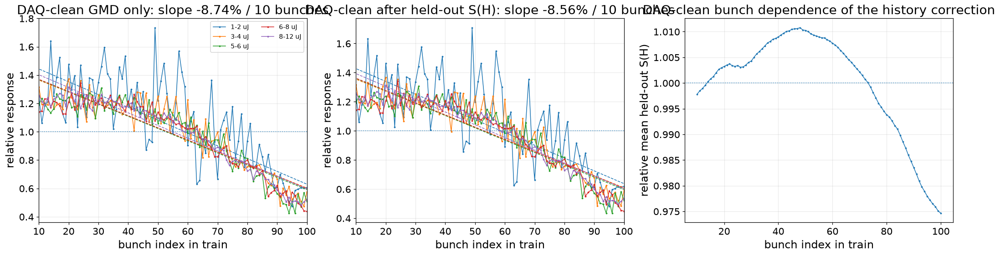

GMD only:             slope=-8.740% / 10 bunches, flatness=0.24765
After held-out S(H):  slope=-8.563% / 10 bunches, flatness=0.24177
Slope change:         +0.177% / 10 bunches
Change in |slope|:    +2.02%


In [ ]:
# --- Direct test after DAQ cleaning: does held-out S(H) explain the bunch slope? ---

state_factor_clean = np.divide(target_state_clean_blockcv,target_base_clean_blockcv,out=np.full_like(gmd,np.nan,dtype=float),where=np.isfinite(target_state_clean_blockcv) & np.isfinite(target_base_clean_blockcv) & (target_base_clean_blockcv > 0))
state_test_clean = daq_valid_rows[:,None] & current_mask & np.isfinite(H_total_clean) & np.isfinite(state_factor_clean) & (state_factor_clean > 0)

target_obs_clean = band_sums(data["target_counts"].astype(float),gmd,state_test_clean)
target_shots_clean = band_sums(np.ones_like(gmd),gmd,state_test_clean)
target_gmd_clean = band_sums(gmd,gmd,state_test_clean)
target_state_norm_clean = band_sums(gmd*state_factor_clean,gmd,state_test_clean)

m_target_gmd_clean = bunch_metrics(target_obs_clean,target_gmd_clean,target_shots_clean)
m_target_state_clean = bunch_metrics(target_obs_clean,target_state_norm_clean,target_shots_clean)

mean_state_clean = np.array([np.nanmean(state_factor_clean[state_test_clean[:,b],b]) if np.any(state_test_clean[:,b]) else np.nan for b in range(n_bunch)])
mean_state_clean /= np.nanmean(mean_state_clean[INDEP_BUNCH_START:])

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)
plot_bunch_response(m_target_gmd_clean,f"DAQ-clean GMD only: slope {m_target_gmd_clean['slope']:+.2f}% / 10 bunches",axes[0])
plot_bunch_response(m_target_state_clean,f"DAQ-clean after held-out S(H): slope {m_target_state_clean['slope']:+.2f}% / 10 bunches",axes[1])
axes[0].legend(ncol=2,fontsize=9)
b = np.arange(INDEP_BUNCH_START,n_bunch)
axes[2].plot(b,mean_state_clean[b],".-",ms=3,lw=1); axes[2].axhline(1,ls=":",lw=1)
axes[2].set(xlabel="bunch index in train",ylabel="relative mean held-out S(H)",title="DAQ-clean bunch dependence of the history correction"); axes[2].grid(alpha=0.25)
plt.show()

slope_change_clean = m_target_state_clean["slope"]-m_target_gmd_clean["slope"]
magnitude_change_clean = 100*(abs(m_target_gmd_clean["slope"])-abs(m_target_state_clean["slope"]))/abs(m_target_gmd_clean["slope"])
print(f"GMD only:             slope={m_target_gmd_clean['slope']:+.3f}% / 10 bunches, flatness={m_target_gmd_clean['flatness']:.5f}")
print(f"After held-out S(H):  slope={m_target_state_clean['slope']:+.3f}% / 10 bunches, flatness={m_target_state_clean['flatness']:.5f}")
print(f"Slope change:         {slope_change_clean:+.3f}% / 10 bunches")
print(f"Change in |slope|:    {magnitude_change_clean:+.2f}%")

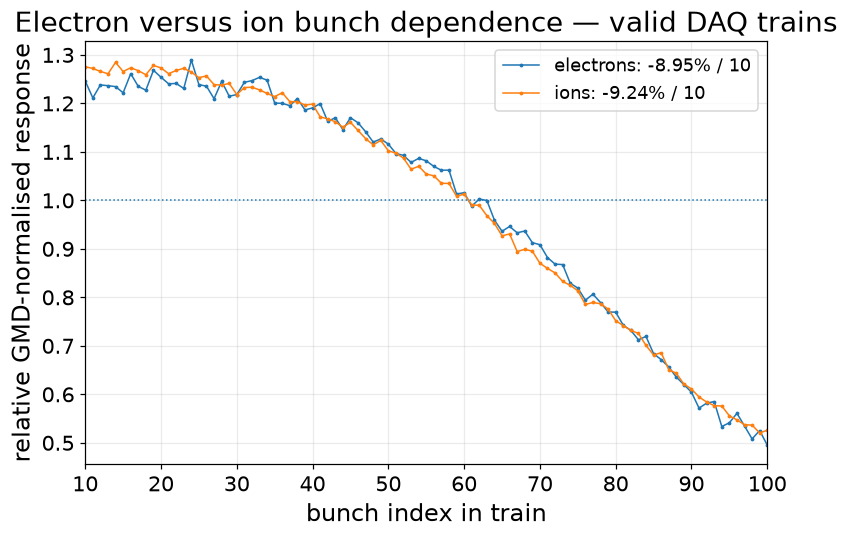

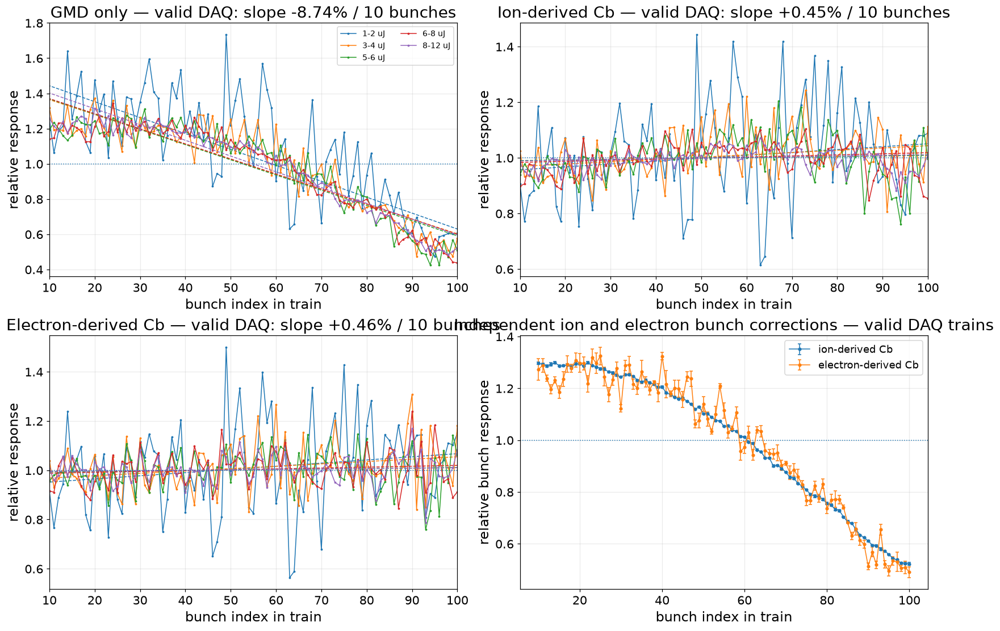

GMD only:            slope=-8.740% / 10 bunches, flatness=0.24765
Ion-derived Cb:      slope=+0.450% / 10 bunches, flatness=0.07554
Electron-derived Cb: slope=+0.460% / 10 bunches, flatness=0.08542
Ion/electron Cb correlation: r=+0.9816


In [ ]:
# --- DAQ-clean cross-detector validation of the bunch-position effect ---

def metrics_from_counts_clean(counts):
    selected = daq_valid_rows[:,None] & current_mask
    obs = band_sums(counts,gmd,selected); norm = band_sums(gmd,gmd,selected); shots = band_sums(np.ones_like(gmd),gmd,selected)
    return bunch_metrics(obs,norm,shots),shots

electron_metric_clean,electron_shots_clean = metrics_from_counts_clean(data["total_electrons"])
ion_metric_clean,ion_shots_clean = metrics_from_counts_clean(ion_counts)
electron_profile_clean = combined_relative_profile(electron_metric_clean,electron_shots_clean)
ion_profile_clean = combined_relative_profile(ion_metric_clean,ion_shots_clean)

fig,ax = plt.subplots(figsize=(8,5))
ax.plot(bunch,electron_profile_clean,".-",ms=3,lw=1,label=f"electrons: {electron_metric_clean['slope']:+.2f}% / 10")
ax.plot(bunch,ion_profile_clean,".-",ms=3,lw=1,label=f"ions: {ion_metric_clean['slope']:+.2f}% / 10")
ax.axhline(1,ls=":",lw=1); ax.set_xlim(INDEP_BUNCH_START,n_bunch-1)
ax.set(xlabel="bunch index in train",ylabel="relative GMD-normalised response",title="Electron versus ion bunch dependence — valid DAQ trains")
ax.grid(alpha=0.25); ax.legend()
plt.show()

shape = (INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch)
target_clean_cv = np.zeros(shape); shots_clean_cv = np.zeros(shape); gmd_clean_cv = np.zeros(shape); ion_cb_clean_cv = np.zeros(shape); electron_cb_clean_cv = np.zeros(shape)
ion_cb_clean_folds = np.ones((INDEP_CV_MOD,n_bunch)); electron_cb_clean_folds = np.ones((INDEP_CV_MOD,n_bunch))

for off in INDEP_CV_OFFSETS:
    train_rows = daq_valid_rows & (train_ids % INDEP_CV_MOD != off)
    test_rows = daq_valid_rows & (train_ids % INDEP_CV_MOD == off)
    cb_ion = learn_bunch_correction(ion_counts,train_rows); cb_electron = learn_bunch_correction(data["ref_counts"],train_rows)
    ion_cb_clean_folds[off] = cb_ion; electron_cb_clean_folds[off] = cb_electron
    g_test = gmd[test_rows]; selected = current_mask[test_rows]; target = data["target_counts"][test_rows].astype(float)
    target_clean_cv[off] = band_sums(target,g_test,selected); shots_clean_cv[off] = band_sums(np.ones_like(g_test),g_test,selected); gmd_clean_cv[off] = band_sums(g_test,g_test,selected)
    ion_cb_clean_cv[off] = band_sums(g_test*cb_ion[None,:],g_test,selected); electron_cb_clean_cv[off] = band_sums(g_test*cb_electron[None,:],g_test,selected)

obs = target_clean_cv.sum(axis=0); shots = shots_clean_cv.sum(axis=0)
m_gmd_clean = bunch_metrics(obs,gmd_clean_cv.sum(axis=0),shots)
m_ion_cb_clean = bunch_metrics(obs,ion_cb_clean_cv.sum(axis=0),shots)
m_electron_cb_clean = bunch_metrics(obs,electron_cb_clean_cv.sum(axis=0),shots)

fig,axes = plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
plot_bunch_response(m_gmd_clean,f"GMD only — valid DAQ: slope {m_gmd_clean['slope']:+.2f}% / 10 bunches",axes[0,0])
plot_bunch_response(m_ion_cb_clean,f"Ion-derived Cb — valid DAQ: slope {m_ion_cb_clean['slope']:+.2f}% / 10 bunches",axes[0,1])
plot_bunch_response(m_electron_cb_clean,f"Electron-derived Cb — valid DAQ: slope {m_electron_cb_clean['slope']:+.2f}% / 10 bunches",axes[1,0])
axes[0,0].legend(ncol=2,fontsize=9)

b = np.arange(INDEP_BUNCH_START,n_bunch)
ion_cb_clean_mean = np.mean(ion_cb_clean_folds,axis=0); ion_cb_clean_sd = np.std(ion_cb_clean_folds,axis=0,ddof=1)
electron_cb_clean_mean = np.mean(electron_cb_clean_folds,axis=0); electron_cb_clean_sd = np.std(electron_cb_clean_folds,axis=0,ddof=1)
axes[1,1].errorbar(b,ion_cb_clean_mean[b],yerr=ion_cb_clean_sd[b],fmt="o-",ms=3,lw=1,capsize=2,label="ion-derived Cb")
axes[1,1].errorbar(b,electron_cb_clean_mean[b],yerr=electron_cb_clean_sd[b],fmt="o-",ms=3,lw=1,capsize=2,label="electron-derived Cb")
axes[1,1].axhline(1,ls=":",lw=1); axes[1,1].set(xlabel="bunch index in train",ylabel="relative bunch response",title="Independent ion and electron bunch corrections — valid DAQ trains"); axes[1,1].grid(alpha=0.25); axes[1,1].legend()
plt.show()

use = np.isfinite(ion_cb_clean_mean[b]) & np.isfinite(electron_cb_clean_mean[b])
r_cb_clean = np.corrcoef(ion_cb_clean_mean[b][use],electron_cb_clean_mean[b][use])[0,1]
print(f"GMD only:            slope={m_gmd_clean['slope']:+.3f}% / 10 bunches, flatness={m_gmd_clean['flatness']:.5f}")
print(f"Ion-derived Cb:      slope={m_ion_cb_clean['slope']:+.3f}% / 10 bunches, flatness={m_ion_cb_clean['flatness']:.5f}")
print(f"Electron-derived Cb: slope={m_electron_cb_clean['slope']:+.3f}% / 10 bunches, flatness={m_electron_cb_clean['flatness']:.5f}")
print(f"Ion/electron Cb correlation: r={r_cb_clean:+.4f}")

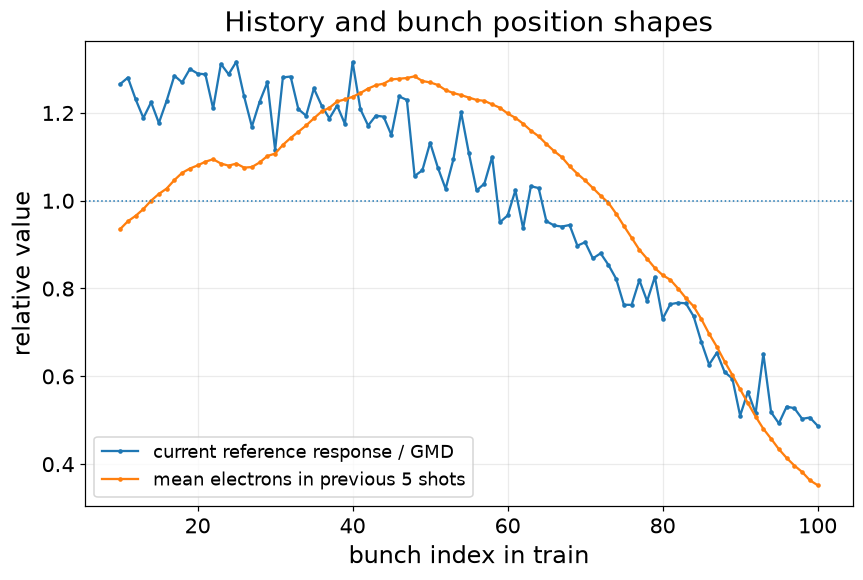

Correlation of the two bunch profiles: r=+0.8337


In [ ]:
# --- Why history and bunch position are confounded ---

CONFOUND_HISTORY_SHOTS = 5

H_conf = np.full_like(gmd,np.nan,dtype=float)
for b in range(CONFOUND_HISTORY_SHOTS,n_bunch):
    H_conf[:,b] = data["total_electrons"][:,b-CONFOUND_HISTORY_SHOTS:b].sum(axis=1)

bunches_conf = np.arange(max(INDEP_BUNCH_START,CONFOUND_HISTORY_SHOTS),n_bunch)
response_conf = np.full(n_bunch,np.nan)
history_conf = np.full(n_bunch,np.nan)
shots_conf = np.zeros(n_bunch,dtype=int)

for b in bunches_conf:
    use = current_mask[:,b] & np.isfinite(H_conf[:,b])
    shots_conf[b] = np.count_nonzero(use)
    if shots_conf[b] == 0:
        continue
    response_conf[b] = data["ref_counts"][use,b].sum()/gmd[use,b].sum()
    history_conf[b] = np.mean(H_conf[use,b])

valid = np.isfinite(response_conf[bunches_conf]) & np.isfinite(history_conf[bunches_conf])
b = bunches_conf[valid]

response_rel = response_conf[b]/np.average(response_conf[b],weights=shots_conf[b])
history_rel = history_conf[b]/np.average(history_conf[b],weights=shots_conf[b])
r = np.corrcoef(response_rel,history_rel)[0,1]

fig,ax = plt.subplots(figsize=(9,5.5))
ax.plot(b,response_rel,".-",ms=4,lw=1.5,label="current reference response / GMD")
ax.plot(b,history_rel,".-",ms=4,lw=1.5,label=f"mean electrons in previous {CONFOUND_HISTORY_SHOTS} shots")
ax.axhline(1,ls=":",lw=1)
ax.set(xlabel="bunch index in train",ylabel="relative value (shot-weighted mean = 1)",title="History and bunch position shapes")
# ax.set(xlabel="bunch index in train",ylabel="relative value",title="History and bunch position shapes")
ax.grid(alpha=0.25); ax.legend()
plt.show()

print(f"Correlation of the two bunch profiles: r={r:+.4f}")

## Model comparison

,H definition,response model,ref improvement (%),target improvement (%),beta mean,beta std,A mean
10,flat L=5,exponential multiplier,-0.004738,-0.005229,0.013532,0.001080,0.963810
25,exp tau=5,exponential multiplier,-0.005568,0.000610,0.016483,0.001459,0.958083
13,flat L=10,exponential multiplier,-0.006204,0.003408,0.008444,0.000649,0.954971
22,exp tau=3,exponential multiplier,-0.007280,-0.004070,0.018612,0.001841,0.966203
19,exp tau=2,exponential multiplier,-0.009479,-0.008679,0.018751,0.002140,0.974736
7,flat L=3,exponential multiplier,-0.009974,-0.011778,0.013194,0.001491,0.978872
4,flat L=2,exponential multiplier,-0.012800,-0.014939,0.011751,0.001574,0.987560
16,exp tau=1,exponential multiplier,-0.013037,-0.015230,0.015367,0.002584,0.987137
1,flat L=1,exponential multiplier,-0.015329,-0.020052,0.009086,0.003075,0.995386
9,flat L=5,linear multiplier,-0.004496,-0.005086,0.014601,0.001203,0.962177


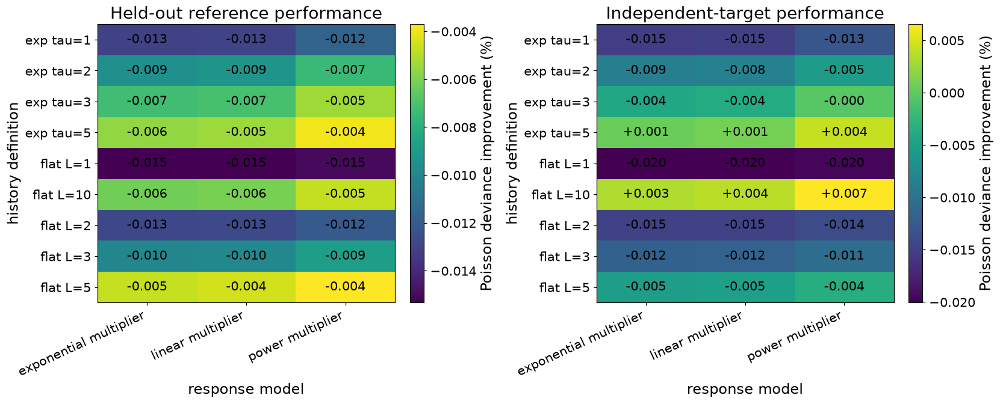

In [ ]:
# --- Systematic DAQ-clean history definition and response-model comparison ---

from scipy.optimize import minimize_scalar

EXPLORE_MAX_LAG = 10
EXPLORE_N_BLOCKS = 5
explore_block_id = np.empty(n_trains,dtype=int)
for k,idx in enumerate(np.array_split(np.arange(n_trains),EXPLORE_N_BLOCKS)): explore_block_id[idx] = k

def flat_history(total,L):
    H = np.full(total.shape,np.nan,dtype=np.float32)
    for b in range(L,n_bunch): H[:,b] = total[:,b-L:b].sum(axis=1)
    return H

def exp_history(total,tau,max_lag=EXPLORE_MAX_LAG):
    H = np.full(total.shape,np.nan,dtype=np.float32)
    w = np.exp(-np.arange(max_lag,dtype=float)/tau)
    for b in range(max_lag,n_bunch): H[:,b] = (total[:,b-max_lag:b][:,::-1]*w[None,:]).sum(axis=1)
    return H

H_CANDIDATES = {
    "flat L=1":flat_history(data["total_electrons"],1),
    "flat L=2":flat_history(data["total_electrons"],2),
    "flat L=3":flat_history(data["total_electrons"],3),
    "flat L=5":flat_history(data["total_electrons"],5),
    "flat L=10":flat_history(data["total_electrons"],10),
    "exp tau=1":exp_history(data["total_electrons"],1),
    "exp tau=2":exp_history(data["total_electrons"],2),
    "exp tau=3":exp_history(data["total_electrons"],3),
    "exp tau=5":exp_history(data["total_electrons"],5)
}

common_bunch_mask = np.zeros_like(current_mask,dtype=bool)
common_bunch_mask[:,max(INDEP_BUNCH_START,EXPLORE_MAX_LAG):] = True
explore_mask = current_mask & common_bunch_mask

ref_base_explore = np.full_like(gmd,np.nan,dtype=float)
target_base_explore = np.full_like(gmd,np.nan,dtype=float)

for held_block in range(EXPLORE_N_BLOCKS):
    train_rows = daq_valid_rows & (explore_block_id != held_block)
    test_rows = daq_valid_rows & (explore_block_id == held_block)
    _,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],explore_mask[train_rows])
    _,target_beta = fit_bunch_baseline(gmd[train_rows],data["target_counts"][train_rows],explore_mask[train_rows])
    ref_base_explore[test_rows] = apply_bunch_baseline(gmd[test_rows],ref_beta)
    target_base_explore[test_rows] = apply_bunch_baseline(gmd[test_rows],target_beta)

def history_factor(H,beta,model):
    if model == "linear multiplier": return 1+beta*H
    if model == "exponential multiplier": return np.exp(np.clip(beta*H,-50,50))
    if model == "power multiplier": return np.exp(np.clip(beta*np.log1p(H),-50,50))
    raise ValueError(model)

def fit_history_factor(y,mu,H,model):
    y = np.asarray(y,dtype=float); mu = np.asarray(mu,dtype=float); H = np.asarray(H,dtype=float)
    ysum = y.sum()
    if model == "linear multiplier":
        hmax = np.nanmax(H)
        bounds = (-0.999/hmax if hmax > 0 else -1,1)
    else: bounds = (-1,1)
    def objective(beta):
        f = history_factor(H,beta,model)
        if np.any(~np.isfinite(f)) or np.any(f <= 0): return np.inf
        A = ysum/np.sum(mu*f)
        return A*np.sum(mu*f)-ysum*np.log(A)-np.sum(y*np.log(f))
    result = minimize_scalar(objective,bounds=bounds,method="bounded",options={"xatol":1e-7})
    beta = result.x
    f = history_factor(H,beta,model)
    A = ysum/np.sum(mu*f)
    return A,beta,result.success

S_MODELS = ["linear multiplier","exponential multiplier","power multiplier"]
explore_rows = []

for h_name,H in H_CANDIDATES.items():
    for model in S_MODELS:
        ref_d0 = ref_d1 = target_d0 = target_d1 = 0.0
        betas,A_values = [],[]
        for held_block in range(EXPLORE_N_BLOCKS):
            train_rows = daq_valid_rows & (explore_block_id != held_block)
            test_rows = daq_valid_rows & (explore_block_id == held_block)
            fit_mask = train_rows[:,None] & explore_mask & np.isfinite(H) & np.isfinite(ref_base_explore) & (ref_base_explore > 0)
            A,beta,success = fit_history_factor(data["ref_counts"][fit_mask],ref_base_explore[fit_mask],H[fit_mask],model)
            betas.append(beta); A_values.append(A)
            ref_valid = test_rows[:,None] & explore_mask & np.isfinite(H) & np.isfinite(ref_base_explore) & (ref_base_explore > 0)
            target_valid = test_rows[:,None] & explore_mask & np.isfinite(H) & np.isfinite(target_base_explore) & (target_base_explore > 0)
            ref_mu0 = ref_base_explore[ref_valid]; ref_mu1 = ref_mu0*A*history_factor(H[ref_valid],beta,model)
            target_mu0 = target_base_explore[target_valid]; target_mu1 = target_mu0*A*history_factor(H[target_valid],beta,model)
            ref_d0 += poisson_deviance(data["ref_counts"][ref_valid],ref_mu0); ref_d1 += poisson_deviance(data["ref_counts"][ref_valid],ref_mu1)
            target_d0 += poisson_deviance(data["target_counts"][target_valid],target_mu0); target_d1 += poisson_deviance(data["target_counts"][target_valid],target_mu1)
        explore_rows.append({"H definition":h_name,"response model":model,"ref improvement (%)":100*(1-ref_d1/ref_d0),"target improvement (%)":100*(1-target_d1/target_d0),"beta mean":np.mean(betas),"beta std":np.std(betas,ddof=1),"A mean":np.mean(A_values)})

history_model_table = pd.DataFrame(explore_rows)
display(history_model_table.sort_values(["response model","ref improvement (%)"],ascending=[True,False]).round(6))

ref_pivot = history_model_table.pivot(index="H definition",columns="response model",values="ref improvement (%)")
target_pivot = history_model_table.pivot(index="H definition",columns="response model",values="target improvement (%)")

fig,axes = plt.subplots(1,2,figsize=(15,6),constrained_layout=True)
for ax,table,title in [(axes[0],ref_pivot,"Held-out reference performance"),(axes[1],target_pivot,"Independent-target performance")]:
    im = ax.imshow(table.values,aspect="auto")
    ax.set_xticks(np.arange(len(table.columns)),table.columns,rotation=25,ha="right")
    ax.set_yticks(np.arange(len(table.index)),table.index)
    ax.set(title=title,xlabel="response model",ylabel="history definition")
    for i in range(table.shape[0]):
        for j in range(table.shape[1]): ax.text(j,i,f"{table.iloc[i,j]:+.3f}",ha="center",va="center")
    fig.colorbar(im,ax=ax,label="Poisson deviance improvement (%)")
plt.show()

Preferred H definition: flat L=5


,H definition,response model,ref improvement (%),target improvement (%),beta mean,beta std,A mean
11,flat L=5,power multiplier,-0.003705,-0.003525,0.049695,0.003706,0.945032
9,flat L=5,linear multiplier,-0.004496,-0.005086,0.014601,0.001203,0.962177
10,flat L=5,exponential multiplier,-0.004738,-0.005229,0.013532,0.001080,0.963810


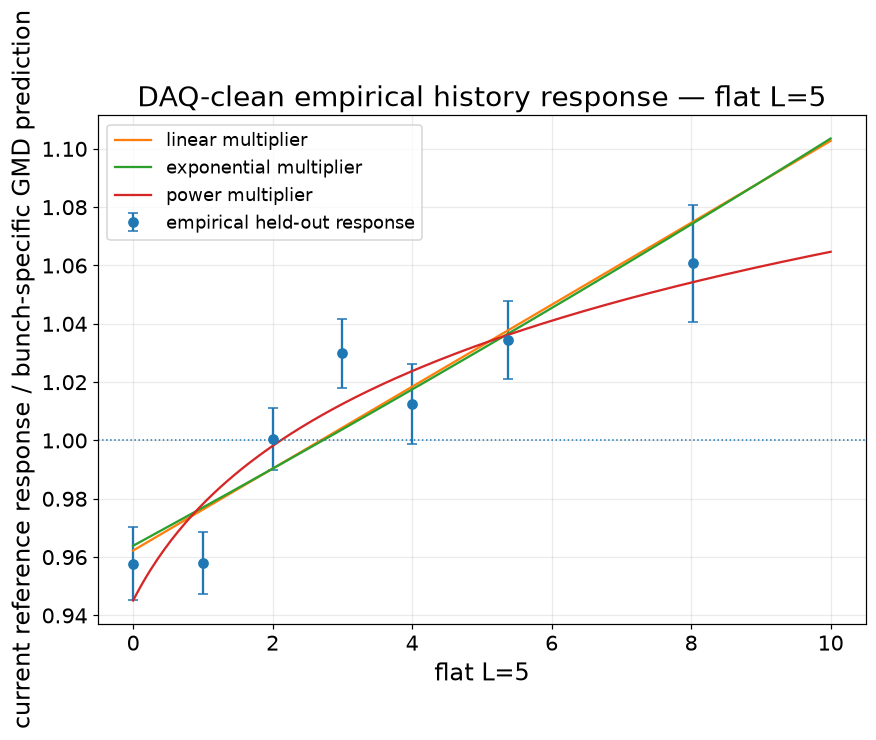

In [ ]:
# --- Empirical DAQ-clean response for the preferred history definition ---

selection_models = ["linear multiplier","exponential multiplier"]
h_score = history_model_table[history_model_table["response model"].isin(selection_models)].groupby("H definition")["ref improvement (%)"].mean()
BEST_H_NAME = h_score.idxmax()
BEST_H = H_CANDIDATES[BEST_H_NAME]
print(f"Preferred H definition: {BEST_H_NAME}")
display(history_model_table[history_model_table["H definition"] == BEST_H_NAME].sort_values("ref improvement (%)",ascending=False).round(6))

valid = daq_valid_rows[:,None] & explore_mask & np.isfinite(BEST_H) & np.isfinite(ref_base_explore) & (ref_base_explore > 0)
h_values = BEST_H[valid]
positive = h_values[np.isfinite(h_values)]
edges = np.unique(np.quantile(positive,[0,0.15,0.30,0.45,0.60,0.75,0.90,0.97,1]))
emp_x,emp_y,emp_err = [],[],[]

for lo,hi in zip(edges[:-1],edges[1:]):
    use = valid & (BEST_H >= lo) & (BEST_H <= hi if hi == edges[-1] else BEST_H < hi)
    y = data["ref_counts"][use].astype(float); mu = ref_base_explore[use]
    if y.size == 0 or mu.sum() <= 0: continue
    emp_x.append(np.average(BEST_H[use],weights=mu)); emp_y.append(y.sum()/mu.sum()); emp_err.append(np.sqrt(y.sum())/mu.sum())

model_curves = {}
h_grid = np.linspace(0,np.nanpercentile(h_values,99.5),200)
for model in S_MODELS:
    fit = history_model_table[(history_model_table["H definition"] == BEST_H_NAME) & (history_model_table["response model"] == model)].iloc[0]
    beta = fit["beta mean"]; A = fit["A mean"]
    model_curves[model] = A*history_factor(h_grid,beta,model)

fig,ax = plt.subplots(figsize=(9,6))
ax.errorbar(emp_x,emp_y,yerr=emp_err,fmt="o",capsize=3,label="empirical held-out response")
for model in S_MODELS: ax.plot(h_grid,model_curves[model],lw=1.5,label=model)
ax.axhline(1,ls=":",lw=1)
ax.set(xlabel=BEST_H_NAME,ylabel="current reference response / bunch-specific GMD prediction",title=f"DAQ-clean empirical history response — {BEST_H_NAME}")
ax.grid(alpha=0.25); ax.legend()
plt.show()

In [ ]:
5+5

10

,response model,baseline weighted RMS,model weighted RMS,RMS improvement (%),baseline weighted MAE,model weighted MAE,MAE improvement (%),mean beta,beta std,mean A
2,power multiplier,0.033617,0.013162,60.846136,0.028494,0.010971,61.497393,0.049695,0.003706,0.945032
0,linear multiplier,0.033617,0.014695,56.287030,0.028494,0.012324,56.747392,0.014601,0.001203,0.962177
1,exponential multiplier,0.033617,0.015079,55.143618,0.028494,0.012520,56.059932,0.013532,0.001080,0.963810


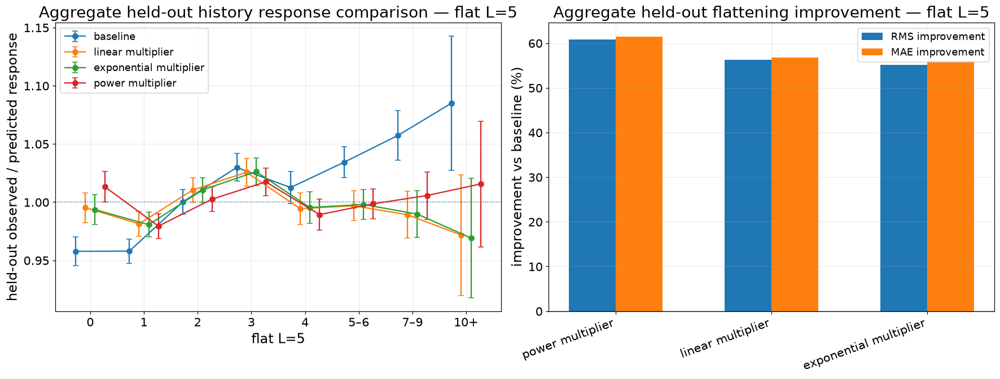


linear multiplier


,held-out block,A,beta,success
0,1,0.955744,0.015836,True
1,2,0.974567,0.012953,True
2,3,0.979155,0.013896,True
3,4,0.959281,0.014696,True
4,5,0.942138,0.015623,True



exponential multiplier


,held-out block,A,beta,success
0,1,0.957391,0.014684,True
1,2,0.976028,0.012054,True
2,3,0.980488,0.012993,True
3,4,0.961321,0.013470,True
4,5,0.943824,0.014458,True



power multiplier


,held-out block,A,beta,success
0,1,0.938917,0.052312,True
1,2,0.957627,0.045544,True
2,3,0.964244,0.045776,True
3,4,0.940073,0.051847,True
4,5,0.924298,0.052995,True


In [ ]:
# --- Compare history models in the aggregate held-out response picture ---

AGG_H_NAME = "flat L=5"
AGG_MODELS = ["linear multiplier","exponential multiplier","power multiplier"]
AGG_H = H_CANDIDATES[AGG_H_NAME]
AGG_BINS = [(0,0,"0"),(1,1,"1"),(2,2,"2"),(3,3,"3"),(4,4,"4"),(5,6,"5–6"),(7,9,"7–9"),(10,np.inf,"10+")]
agg_valid = daq_valid_rows[:,None] & explore_mask & np.isfinite(AGG_H) & np.isfinite(ref_base_explore) & (ref_base_explore > 0)

def heldout_prediction_for_model(H,model):
    mu1 = np.full_like(ref_base_explore,np.nan,dtype=float)
    fit_rows = []
    for held_block in range(EXPLORE_N_BLOCKS):
        train_rows = daq_valid_rows & (explore_block_id != held_block)
        test_rows = daq_valid_rows & (explore_block_id == held_block)
        fit_mask = train_rows[:,None] & explore_mask & np.isfinite(H) & np.isfinite(ref_base_explore) & (ref_base_explore > 0)
        A,beta,success = fit_history_factor(data["ref_counts"][fit_mask],ref_base_explore[fit_mask],H[fit_mask],model)
        test_mask = test_rows[:,None] & explore_mask & np.isfinite(H) & np.isfinite(ref_base_explore) & (ref_base_explore > 0)
        mu1[test_mask] = ref_base_explore[test_mask]*A*history_factor(H[test_mask],beta,model)
        fit_rows.append({"held-out block":held_block+1,"A":A,"beta":beta,"success":success})
    return mu1,pd.DataFrame(fit_rows)

def aggregate_curve(y,mu,H,valid,bins):
    rows = []
    for lo,hi,label in bins:
        use = valid & (H >= lo) & (H <= hi if np.isfinite(hi) else H >= lo)
        obs = y[use].sum()
        pred = mu[use].sum()
        n = np.count_nonzero(use)
        hbar = np.average(H[use],weights=mu[use]) if pred > 0 else np.nan
        rows.append({"label":label,"H mean":hbar,"shots":n,"obs":obs,"pred":pred,"response":obs/pred if pred > 0 else np.nan,"err":np.sqrt(obs)/pred if obs > 0 and pred > 0 else np.nan})
    return pd.DataFrame(rows)

base_curve = aggregate_curve(data["ref_counts"].astype(float),ref_base_explore,AGG_H,agg_valid,AGG_BINS)
compare_rows = []
model_curves = {}

base_rms = np.sqrt(np.sum(base_curve["pred"]*(base_curve["response"]-1)**2)/np.sum(base_curve["pred"]))
base_mae = np.sum(base_curve["pred"]*np.abs(base_curve["response"]-1))/np.sum(base_curve["pred"])

for model in AGG_MODELS:
    mu1,fit_table = heldout_prediction_for_model(AGG_H,model)
    curve = aggregate_curve(data["ref_counts"].astype(float),mu1,AGG_H,agg_valid & np.isfinite(mu1) & (mu1 > 0),AGG_BINS)
    model_curves[model] = {"curve":curve,"fit_table":fit_table}
    rms = np.sqrt(np.sum(curve["pred"]*(curve["response"]-1)**2)/np.sum(curve["pred"]))
    mae = np.sum(curve["pred"]*np.abs(curve["response"]-1))/np.sum(curve["pred"])
    compare_rows.append({"response model":model,"baseline weighted RMS":base_rms,"model weighted RMS":rms,"RMS improvement (%)":100*(1-rms/base_rms),"baseline weighted MAE":base_mae,"model weighted MAE":mae,"MAE improvement (%)":100*(1-mae/base_mae),"mean beta":fit_table["beta"].mean(),"beta std":fit_table["beta"].std(ddof=1),"mean A":fit_table["A"].mean()})

aggregate_model_table = pd.DataFrame(compare_rows).sort_values("RMS improvement (%)",ascending=False)
display(aggregate_model_table.round(6))

x = np.arange(len(base_curve))
fig,axes = plt.subplots(1,2,figsize=(16,6),constrained_layout=True)
axes[0].errorbar(x-0.18,base_curve["response"],yerr=base_curve["err"],fmt="o-",capsize=3,label="baseline")
for shift,model in zip([0.0,0.18,0.36],AGG_MODELS):
    curve = model_curves[model]["curve"]
    axes[0].errorbar(x+shift,curve["response"],yerr=curve["err"],fmt="o-",capsize=3,label=model)
axes[0].axhline(1,ls=":",lw=1)
axes[0].set_xticks(x+0.09,base_curve["label"])
axes[0].set(xlabel=AGG_H_NAME,ylabel="held-out observed / predicted response",title=f"Aggregate held-out history response comparison — {AGG_H_NAME}")
axes[0].grid(alpha=0.25); axes[0].legend()

bar_x = np.arange(len(AGG_MODELS))
axes[1].bar(bar_x-0.15,aggregate_model_table["RMS improvement (%)"],width=0.3,label="RMS improvement")
axes[1].bar(bar_x+0.15,aggregate_model_table["MAE improvement (%)"],width=0.3,label="MAE improvement")
axes[1].axhline(0,ls=":",lw=1)
axes[1].set_xticks(bar_x,aggregate_model_table["response model"],rotation=20,ha="right")
axes[1].set(ylabel="improvement vs baseline (%)",title=f"Aggregate held-out flattening improvement — {AGG_H_NAME}")
axes[1].grid(alpha=0.25); axes[1].legend()
plt.show()

for model in AGG_MODELS:
    print(f"\n{model}")
    display(model_curves[model]["fit_table"].round(6))

## Proper model comparison

In [ ]:
# --- Helpers for nested history-model comparison ---

def make_history(family,param):
    if family == "flat":
        return flat_history(TOTAL_E,int(param))
    if family == "exponential":
        return exp_history(TOTAL_E,float(param),max_lag=H_MAX_LAG)
    if family == "active":
        L = int(param)
        active = (TOTAL_E > 0).astype(np.float32)
        H = np.full(TOTAL_E.shape,np.nan,dtype=np.float32)
        cs = np.concatenate((np.zeros((n_trains,1),dtype=np.float32),np.cumsum(active,axis=1,dtype=np.float32)),axis=1)
        H[:,L:] = cs[:,L:n_bunch]-cs[:,:n_bunch-L]
        return H
    raise ValueError(f"Unknown history family: {family}")

def history_factor(H,beta,model):
    if model in ("linear","linear multiplier"):
        return 1+beta*H
    if model in ("exponential","exponential multiplier"):
        return np.exp(np.clip(beta*H,-50,50))
    if model in ("power","power multiplier"):
        return np.exp(np.clip(beta*np.log1p(H),-50,50))
    raise ValueError(model)

def fit_history_factor_fast(y,mu,H,model):
    y = np.asarray(y,dtype=float)
    mu = np.asarray(mu,dtype=float)
    H = np.asarray(H,dtype=float)
    ysum = y.sum()

    if model in ("linear","linear multiplier"):
        hmax = np.nanmax(H)
        bounds = (-0.999/hmax if hmax > 0 else -1,1)
    else:
        bounds = (-1,1)

    def objective(beta):
        f = history_factor(H,beta,model)
        if np.any(~np.isfinite(f)) or np.any(f <= 0):
            return np.inf
        den = np.sum(mu*f)
        if den <= 0:
            return np.inf
        A = ysum/den
        return A*den-ysum*np.log(A)-np.sum(y*np.log(f))

    result = minimize_scalar(objective,bounds=bounds,method="bounded",options={"xatol":1e-6})
    beta = result.x
    f = history_factor(H,beta,model)
    A = ysum/np.sum(mu*f)
    return A,beta

H parameter selected independently inside each outer fold:


H family,active,exponential,flat
outer block,,,
1,10,5,5
2,5,5,5
3,5,5,5
4,5,5,5
5,5,5,5


Final outer-held-out performance:


,H family,S(H),selected parameters,reference improvement (%),target improvement (%),beta mean,beta std
2,flat,power,"5, 5, 5, 5, 5",0.011899,0.019704,0.049387,0.002027
5,exponential,power,"5, 5, 5, 5, 5",0.011652,0.027372,0.061664,0.002627
0,flat,linear,"5, 5, 5, 5, 5",0.011092,0.018119,0.014514,0.000810
1,flat,exponential,"5, 5, 5, 5, 5",0.010845,0.017964,0.013462,0.000757
3,exponential,linear,"5, 5, 5, 5, 5",0.010247,0.024155,0.017665,0.001065
4,exponential,exponential,"5, 5, 5, 5, 5",0.010057,0.023750,0.016379,0.000986
6,active,linear,"10, 5, 5, 5, 5",0.009162,0.018689,0.025455,0.004459
7,active,exponential,"10, 5, 5, 5, 5",0.009131,0.018581,0.024025,0.004353
8,active,power,"10, 5, 5, 5, 5",0.008609,0.019464,0.063277,0.004630


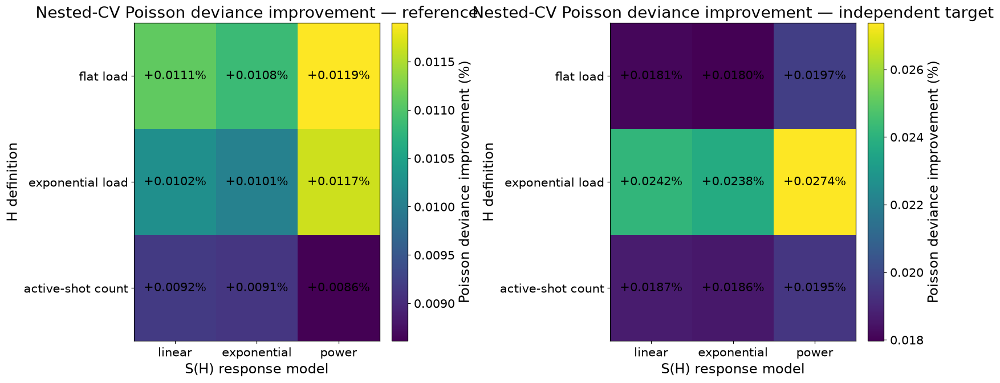

In [ ]:
# --- Nested CV: select H timescale internally, then compare all 9 H x S(H) models ---

NESTED_H_FAMILIES = {"flat":[1,2,3,5,10],"exponential":[1,2,3,5],"active":[1,2,3,5,10]}
# NESTED_H_FAMILIES = {
#     "flat":[1,2,3,4,5,6,7,8,10],
#     "exponential":[1,2,3,4,5,6,7],
#     "active":[1,2,3,4,5,6,7,8,10]
# }
NESTED_S_MODELS = ["linear","exponential","power"]
NESTED_SELECT_MODEL = "linear"
H_MAX_LAG = 10
TOTAL_E = data["total_electrons"].astype(np.float32)

nested_selection_rows = []
nested_fold_rows = []
nested_totals = {(family,model):{"ref_d0":0.0,"ref_d1":0.0,"target_d0":0.0,"target_d1":0.0} for family in NESTED_H_FAMILIES for model in NESTED_S_MODELS}

for outer_block in range(EXPLORE_N_BLOCKS):
    outer_train_rows = daq_valid_rows & (explore_block_id != outer_block)
    outer_test_rows = daq_valid_rows & (explore_block_id == outer_block)

    inner_cache = []
    for inner_block in range(EXPLORE_N_BLOCKS):
        if inner_block == outer_block: continue
        inner_train_rows = daq_valid_rows & (explore_block_id != outer_block) & (explore_block_id != inner_block)
        inner_val_rows = daq_valid_rows & (explore_block_id == inner_block)
        ref_base_inner_train,ref_beta_inner = fit_bunch_baseline(gmd[inner_train_rows],data["ref_counts"][inner_train_rows],explore_mask[inner_train_rows])
        ref_base_inner_val = apply_bunch_baseline(gmd[inner_val_rows],ref_beta_inner)
        inner_cache.append((inner_block,inner_train_rows,inner_val_rows,ref_base_inner_train.astype(np.float32),ref_base_inner_val.astype(np.float32)))

    selected_params = {}
    for family,params in NESTED_H_FAMILIES.items():
        family_scores = []
        for param in params:
            H = make_history(family,param)
            d0_total = d1_total = 0.0
            for inner_block,inner_train_rows,inner_val_rows,mu_train,mu_val in inner_cache:
                H_train = H[inner_train_rows]; H_val = H[inner_val_rows]
                train_mask = explore_mask[inner_train_rows] & np.isfinite(H_train) & np.isfinite(mu_train) & (mu_train > 0)
                val_mask = explore_mask[inner_val_rows] & np.isfinite(H_val) & np.isfinite(mu_val) & (mu_val > 0)
                y_train = data["ref_counts"][inner_train_rows][train_mask].astype(float)
                mu_train_use = mu_train[train_mask].astype(float)
                h_train = H_train[train_mask].astype(float)
                A0 = y_train.sum()/mu_train_use.sum()
                A,beta = fit_history_factor_fast(y_train,mu_train_use,h_train,NESTED_SELECT_MODEL)
                y_val = data["ref_counts"][inner_val_rows][val_mask].astype(float)
                mu0 = mu_val[val_mask].astype(float)*A0
                mu1 = mu_val[val_mask].astype(float)*A*history_factor(H_val[val_mask],beta,NESTED_SELECT_MODEL)
                d0_total += poisson_deviance(y_val,mu0)
                d1_total += poisson_deviance(y_val,mu1)
            improvement = 100*(1-d1_total/d0_total)
            family_scores.append((param,improvement))
            del H
        best_param,best_score = max(family_scores,key=lambda x:x[1])
        selected_params[family] = best_param
        nested_selection_rows.append({"outer block":outer_block+1,"H family":family,"selected parameter":best_param,"inner-CV improvement (%)":best_score})

    ref_base_outer_train,ref_beta_outer = fit_bunch_baseline(gmd[outer_train_rows],data["ref_counts"][outer_train_rows],explore_mask[outer_train_rows])
    ref_base_outer_test = apply_bunch_baseline(gmd[outer_test_rows],ref_beta_outer)
    target_base_outer_train,target_beta_outer = fit_bunch_baseline(gmd[outer_train_rows],data["target_counts"][outer_train_rows],explore_mask[outer_train_rows])
    target_base_outer_test = apply_bunch_baseline(gmd[outer_test_rows],target_beta_outer)

    for family,param in selected_params.items():
        H = make_history(family,param)
        H_train = H[outer_train_rows]; H_test = H[outer_test_rows]
        train_mask = explore_mask[outer_train_rows] & np.isfinite(H_train) & np.isfinite(ref_base_outer_train) & (ref_base_outer_train > 0)
        ref_test_mask = explore_mask[outer_test_rows] & np.isfinite(H_test) & np.isfinite(ref_base_outer_test) & (ref_base_outer_test > 0)
        target_test_mask = explore_mask[outer_test_rows] & np.isfinite(H_test) & np.isfinite(target_base_outer_test) & (target_base_outer_test > 0)
        y_train = data["ref_counts"][outer_train_rows][train_mask].astype(float)
        mu_train = ref_base_outer_train[train_mask].astype(float)
        h_train = H_train[train_mask].astype(float)
        A0 = y_train.sum()/mu_train.sum()

        for model in NESTED_S_MODELS:
            A,beta = fit_history_factor_fast(y_train,mu_train,h_train,model)
            y_ref = data["ref_counts"][outer_test_rows][ref_test_mask].astype(float)
            ref_mu0 = ref_base_outer_test[ref_test_mask].astype(float)*A0
            ref_mu1 = ref_base_outer_test[ref_test_mask].astype(float)*A*history_factor(H_test[ref_test_mask],beta,model)
            y_target = data["target_counts"][outer_test_rows][target_test_mask].astype(float)
            target_mu0 = target_base_outer_test[target_test_mask].astype(float)*A0
            target_mu1 = target_base_outer_test[target_test_mask].astype(float)*A*history_factor(H_test[target_test_mask],beta,model)
            ref_d0 = poisson_deviance(y_ref,ref_mu0); ref_d1 = poisson_deviance(y_ref,ref_mu1)
            target_d0 = poisson_deviance(y_target,target_mu0); target_d1 = poisson_deviance(y_target,target_mu1)
            nested_totals[(family,model)]["ref_d0"] += ref_d0
            nested_totals[(family,model)]["ref_d1"] += ref_d1
            nested_totals[(family,model)]["target_d0"] += target_d0
            nested_totals[(family,model)]["target_d1"] += target_d1
            nested_fold_rows.append({"outer block":outer_block+1,"H family":family,"selected parameter":param,"S(H)":model,"beta":beta,"reference improvement (%)":100*(1-ref_d1/ref_d0),"target improvement (%)":100*(1-target_d1/target_d0)})
        del H

    del inner_cache,ref_base_outer_train,ref_base_outer_test,target_base_outer_train,target_base_outer_test

nested_selection_table = pd.DataFrame(nested_selection_rows)
nested_fold_table = pd.DataFrame(nested_fold_rows)

summary_rows = []
for family in NESTED_H_FAMILIES:
    params = nested_selection_table[nested_selection_table["H family"] == family]["selected parameter"].tolist()
    for model in NESTED_S_MODELS:
        t = nested_totals[(family,model)]
        sub = nested_fold_table[(nested_fold_table["H family"] == family) & (nested_fold_table["S(H)"] == model)]
        summary_rows.append({"H family":family,"S(H)":model,"selected parameters":", ".join(f"{p:g}" for p in params),"reference improvement (%)":100*(1-t["ref_d1"]/t["ref_d0"]),"target improvement (%)":100*(1-t["target_d1"]/t["target_d0"]),"beta mean":sub["beta"].mean(),"beta std":sub["beta"].std(ddof=1)})

nested_summary_table = pd.DataFrame(summary_rows)
print("H parameter selected independently inside each outer fold:")
display(nested_selection_table.pivot(index="outer block",columns="H family",values="selected parameter"))
print("Final outer-held-out performance:")
display(nested_summary_table.sort_values("reference improvement (%)",ascending=False).round(6))

ref_matrix = nested_summary_table.pivot(index="H family",columns="S(H)",values="reference improvement (%)").reindex(index=["flat","exponential","active"],columns=NESTED_S_MODELS)
target_matrix = nested_summary_table.pivot(index="H family",columns="S(H)",values="target improvement (%)").reindex(index=["flat","exponential","active"],columns=NESTED_S_MODELS)

fig,axes = plt.subplots(1,2,figsize=(15,6),constrained_layout=True)
for ax,matrix,title in [(axes[0],ref_matrix,"Nested-CV Poisson deviance improvement — reference"),(axes[1],target_matrix,"Nested-CV Poisson deviance improvement — independent target")]:
    im = ax.imshow(matrix.values,aspect="auto")
    ax.set_xticks(np.arange(len(NESTED_S_MODELS)),NESTED_S_MODELS)
    ax.set_yticks(np.arange(3),["flat load","exponential load","active-shot count"])
    ax.set(xlabel="S(H) response model",ylabel="H definition",title=title)
    for i in range(3):
        for j in range(3): ax.text(j,i,f"{matrix.iloc[i,j]:+.4f}%",ha="center",va="center")
    fig.colorbar(im,ax=ax,label="Poisson deviance improvement (%)")
plt.show()

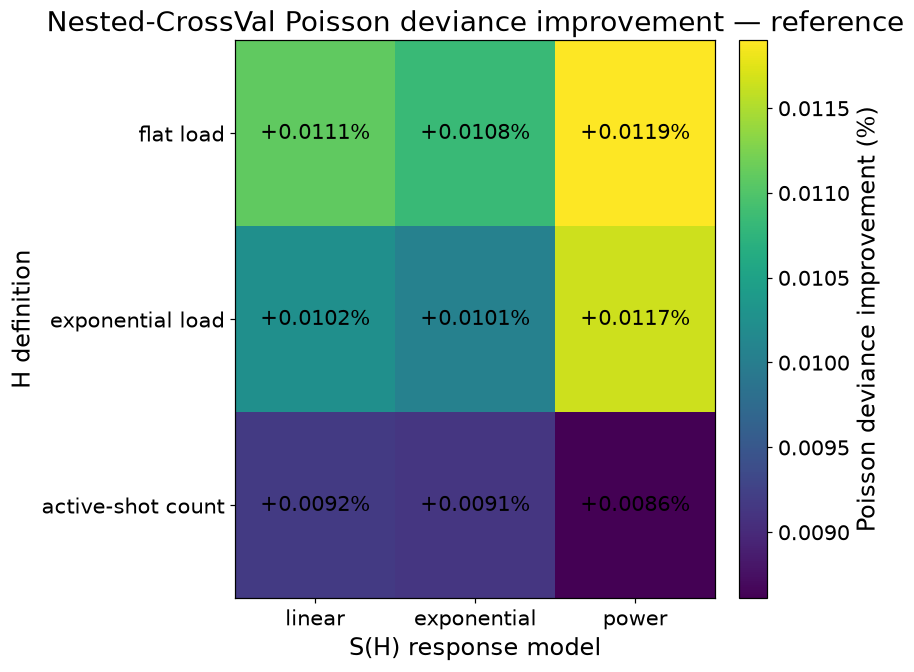

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Reconstruct summary table from raw data
summary_data = [
    {"H family": "flat", "S(H)": "power", "reference improvement (%)": 0.011899, "target improvement (%)": 0.019704},
    {"H family": "exponential", "S(H)": "power", "reference improvement (%)": 0.011652, "target improvement (%)": 0.027372},
    {"H family": "flat", "S(H)": "linear", "reference improvement (%)": 0.011092, "target improvement (%)": 0.018119},
    {"H family": "flat", "S(H)": "exponential", "reference improvement (%)": 0.010845, "target improvement (%)": 0.017964},
    {"H family": "exponential", "S(H)": "linear", "reference improvement (%)": 0.010247, "target improvement (%)": 0.024155},
    {"H family": "exponential", "S(H)": "exponential", "reference improvement (%)": 0.010057, "target improvement (%)": 0.023750},
    {"H family": "active", "S(H)": "linear", "reference improvement (%)": 0.009162, "target improvement (%)": 0.018689},
    {"H family": "active", "S(H)": "exponential", "reference improvement (%)": 0.009131, "target improvement (%)": 0.018581},
    {"H family": "active", "S(H)": "power", "reference improvement (%)": 0.008609, "target improvement (%)": 0.019464},
]

nested_summary_table = pd.DataFrame(summary_data)

# Reconstruct reference matrix for the heatmap
NESTED_S_MODELS = ["linear", "exponential", "power"]
ref_matrix = nested_summary_table.pivot(
    index="H family", columns="S(H)", values="reference improvement (%)"
).reindex(index=["flat", "exponential", "active"], columns=NESTED_S_MODELS)

# Plot left panel
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
im = ax.imshow(ref_matrix.values, aspect="auto")

ax.set_xticks(np.arange(len(NESTED_S_MODELS)), NESTED_S_MODELS)
ax.set_yticks(np.arange(3), ["flat load", "exponential load", "active-shot count"])
ax.set(
    xlabel="S(H) response model",
    ylabel="H definition",
    title="Nested-CrossVal Poisson deviance improvement — reference",
)

for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{ref_matrix.iloc[i, j]:+.4f}%", ha="center", va="center")

fig.colorbar(im, ax=ax, label="Poisson deviance improvement (%)")
plt.show()

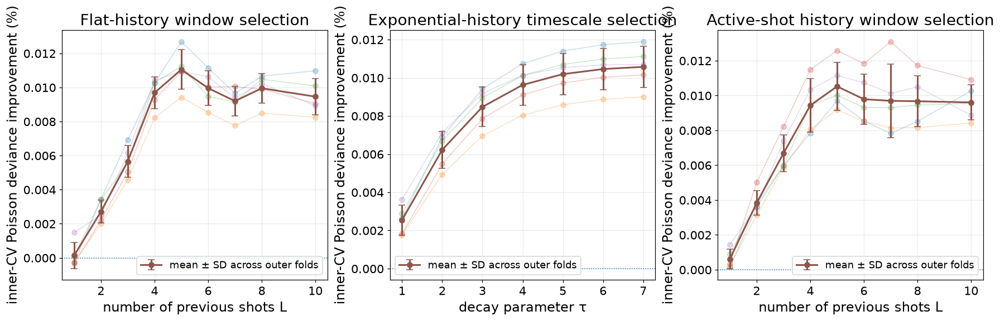

In [ ]:
# --- Nested-CV history-timescale scan with fold-to-fold uncertainty ---

H_SCAN_FAMILIES = {
    "flat":[1,2,3,4,5,6,7,8,10],
    "exponential":[1,2,3,4,5,6,7],
    "active":[1,2,3,4,5,6,7,8,10]
}
H_SCAN_MODEL = "linear"

h_scan_rows = []

for outer_block in range(EXPLORE_N_BLOCKS):
    for family,params in H_SCAN_FAMILIES.items():
        for param in params:
            H = make_history(family,param)
            d0_total = d1_total = 0.0

            for inner_block in range(EXPLORE_N_BLOCKS):
                if inner_block == outer_block: continue

                inner_train_rows = daq_valid_rows & (explore_block_id != outer_block) & (explore_block_id != inner_block)
                inner_val_rows = daq_valid_rows & (explore_block_id == inner_block)

                base_train,beta_base = fit_bunch_baseline(
                    gmd[inner_train_rows],
                    data["ref_counts"][inner_train_rows],
                    explore_mask[inner_train_rows]
                )
                base_val = apply_bunch_baseline(gmd[inner_val_rows],beta_base)

                H_train = H[inner_train_rows]
                H_val = H[inner_val_rows]

                train_mask = explore_mask[inner_train_rows] & np.isfinite(H_train) & np.isfinite(base_train) & (base_train > 0)
                val_mask = explore_mask[inner_val_rows] & np.isfinite(H_val) & np.isfinite(base_val) & (base_val > 0)

                y_train = data["ref_counts"][inner_train_rows][train_mask].astype(float)
                mu_train = base_train[train_mask].astype(float)
                h_train = H_train[train_mask].astype(float)

                A0 = y_train.sum()/mu_train.sum()
                A,beta = fit_history_factor_fast(y_train,mu_train,h_train,H_SCAN_MODEL)

                y_val = data["ref_counts"][inner_val_rows][val_mask].astype(float)
                mu0 = base_val[val_mask].astype(float)*A0
                mu1 = base_val[val_mask].astype(float)*A*history_factor(H_val[val_mask],beta,H_SCAN_MODEL)

                d0_total += poisson_deviance(y_val,mu0)
                d1_total += poisson_deviance(y_val,mu1)

            h_scan_rows.append({
                "outer block":outer_block+1,
                "H family":family,
                "parameter":param,
                "improvement (%)":100*(1-d1_total/d0_total)
            })

            del H

h_scan_table = pd.DataFrame(h_scan_rows)

fig,axes = plt.subplots(1,3,figsize=(16,5),constrained_layout=True)

for ax,family,title,xlabel in [
    (axes[0],"flat","Flat-history window selection","number of previous shots L"),
    (axes[1],"exponential","Exponential-history timescale selection","decay parameter τ"),
    (axes[2],"active","Active-shot history window selection","number of previous shots L")
]:
    sub = h_scan_table[h_scan_table["H family"] == family]
    params = np.array(sorted(sub["parameter"].unique()),dtype=float)

    for outer_block in range(1,EXPLORE_N_BLOCKS+1):
        fold = sub[sub["outer block"] == outer_block].set_index("parameter").loc[params]
        ax.plot(params,fold["improvement (%)"].to_numpy(),"-o",alpha=0.25,lw=1)

    grouped = sub.groupby("parameter")["improvement (%)"]
    mean = grouped.mean().reindex(params).to_numpy()
    std = grouped.std(ddof=1).reindex(params).to_numpy()

    ax.errorbar(params,mean,yerr=std,fmt="o-",capsize=4,lw=2,label="mean ± SD across outer folds")
    ax.axhline(0,ls=":",lw=1)
    ax.set(xlabel=xlabel,ylabel="inner-CV Poisson deviance improvement (%)",title=title)
    ax.grid(alpha=0.25)
    ax.legend()

plt.show()

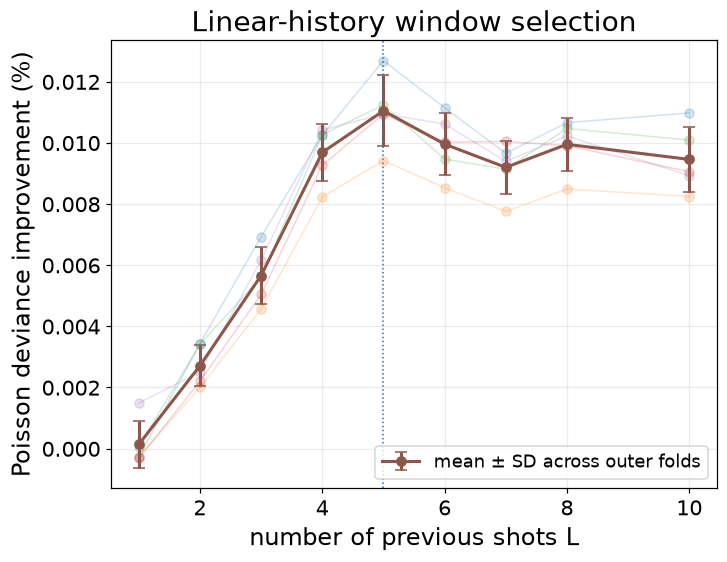

In [ ]:
# --- Condensed meeting figure: flat-history window selection ---

fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)

# Flat-history L selection
sub = h_scan_table[h_scan_table["H family"] == "flat"]
params = np.array(sorted(sub["parameter"].unique()), dtype=float)

for outer_block in range(1, EXPLORE_N_BLOCKS + 1):
    fold = sub[sub["outer block"] == outer_block].set_index("parameter").loc[params]
    ax.plot(params, fold["improvement (%)"].to_numpy(), "-o", alpha=0.20, lw=1)

grouped = sub.groupby("parameter")["improvement (%)"]
mean = grouped.mean().reindex(params).to_numpy()
std = grouped.std(ddof=1).reindex(params).to_numpy()

ax.errorbar(params, mean, yerr=std, fmt="o-", capsize=4, lw=2, label="mean ± SD across outer folds")
ax.axvline(5, ls=":", lw=1)
ax.set(
    xlabel="number of previous shots L",
    # ylabel="inner-CV Poisson deviance improvement (%)",
    ylabel="Poisson deviance improvement (%)",
    title="Linear-history window selection"
)
ax.grid(alpha=0.25)
ax.legend()

plt.show()

,weighted RMS,flattening improvement (%)
model,,
baseline,0.03360,0.00000
linear,0.01466,56.37310
exponential,0.01505,55.22869
power,0.01325,60.57924


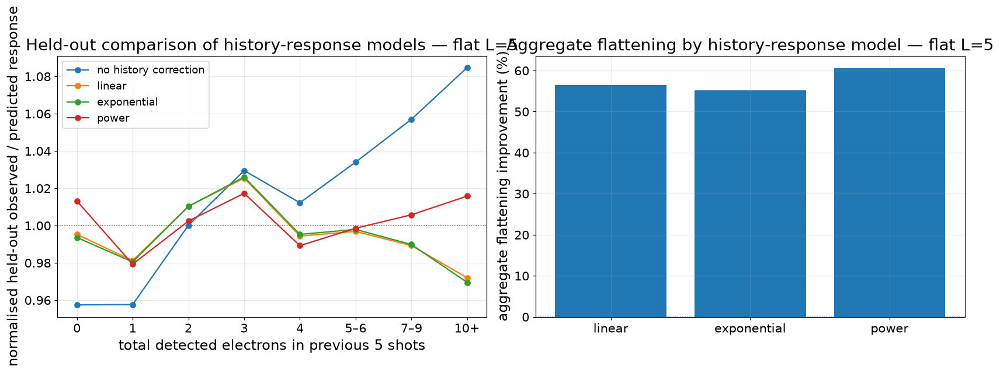

In [ ]:
# --- Direct held-out comparison of S(H) models for flat L=5 ---

COMPARE_H = make_history("flat",5)
COMPARE_MODELS = ["linear","exponential","power"]
COMPARE_BINS = [(0,0,"0"),(1,1,"1"),(2,2,"2"),(3,3,"3"),(4,4,"4"),(5,6,"5–6"),(7,9,"7–9"),(10,np.inf,"10+")]
compare_base = np.full_like(ref_base_explore,np.nan,dtype=float)
compare_pred = {model:np.full_like(ref_base_explore,np.nan,dtype=float) for model in COMPARE_MODELS}

for outer_block in range(EXPLORE_N_BLOCKS):
    train_rows = daq_valid_rows & (explore_block_id != outer_block)
    test_rows = daq_valid_rows & (explore_block_id == outer_block)
    ref_base_train,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],explore_mask[train_rows])
    ref_base_test = apply_bunch_baseline(gmd[test_rows],ref_beta)
    H_train = COMPARE_H[train_rows]; H_test = COMPARE_H[test_rows]
    train_mask = explore_mask[train_rows] & np.isfinite(H_train) & np.isfinite(ref_base_train) & (ref_base_train > 0)
    test_mask = explore_mask[test_rows] & np.isfinite(H_test) & np.isfinite(ref_base_test) & (ref_base_test > 0)
    y_train = data["ref_counts"][train_rows][train_mask].astype(float); mu_train = ref_base_train[train_mask].astype(float); h_train = H_train[train_mask].astype(float)
    A0 = y_train.sum()/mu_train.sum()
    tmp0 = np.full_like(ref_base_test,np.nan,dtype=float); tmp0[test_mask] = ref_base_test[test_mask]*A0; compare_base[test_rows] = tmp0
    for model in COMPARE_MODELS:
        A,beta = fit_history_factor_fast(y_train,mu_train,h_train,model)
        tmp = np.full_like(ref_base_test,np.nan,dtype=float)
        tmp[test_mask] = ref_base_test[test_mask]*A*history_factor(H_test[test_mask],beta,model)
        compare_pred[model][test_rows] = tmp

valid = daq_valid_rows[:,None] & explore_mask & np.isfinite(COMPARE_H) & np.isfinite(compare_base) & (compare_base > 0)
obs_bin,base_bin,weights_bin = [],[],[]
model_bins = {model:[] for model in COMPARE_MODELS}
labels = [x[2] for x in COMPARE_BINS]

for lo,hi,label in COMPARE_BINS:
    use = valid & (COMPARE_H >= lo) & (COMPARE_H <= hi if np.isfinite(hi) else COMPARE_H >= lo)
    obs_bin.append(data["ref_counts"][use].sum())
    base_bin.append(compare_base[use].sum())
    weights_bin.append(compare_base[use].sum())
    for model in COMPARE_MODELS: model_bins[model].append(compare_pred[model][use].sum())

obs_bin = np.asarray(obs_bin,dtype=float); base_bin = np.asarray(base_bin,dtype=float); weights_bin = np.asarray(weights_bin,dtype=float)
base_response = obs_bin/base_bin
base_response /= obs_bin.sum()/base_bin.sum()
model_response = {}
model_rms = {}

for model in COMPARE_MODELS:
    pred = np.asarray(model_bins[model],dtype=float)
    r = obs_bin/pred
    r /= obs_bin.sum()/pred.sum()
    model_response[model] = r
    model_rms[model] = np.sqrt(np.sum(weights_bin*(r-1)**2)/np.sum(weights_bin))

base_rms = np.sqrt(np.sum(weights_bin*(base_response-1)**2)/np.sum(weights_bin))
compare_table = pd.DataFrame([{"model":"baseline","weighted RMS":base_rms,"flattening improvement (%)":0.0}]+[{"model":model,"weighted RMS":model_rms[model],"flattening improvement (%)":100*(1-model_rms[model]/base_rms)} for model in COMPARE_MODELS]).set_index("model")
display(compare_table.round(5))

x = np.arange(len(labels))
fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)
axes[0].plot(x,base_response,"o-",label="no history correction")
for model in COMPARE_MODELS: axes[0].plot(x,model_response[model],"o-",label=model)
axes[0].axhline(1,ls=":",lw=1); axes[0].set_xticks(x,labels); axes[0].set(xlabel="total detected electrons in previous 5 shots",ylabel="normalised held-out observed / predicted response",title="Held-out comparison of history-response models — flat L=5"); axes[0].grid(alpha=0.25); axes[0].legend()

axes[1].bar(np.arange(len(COMPARE_MODELS)),[100*(1-model_rms[m]/base_rms) for m in COMPARE_MODELS])
axes[1].axhline(0,ls=":",lw=1); axes[1].set_xticks(np.arange(len(COMPARE_MODELS)),COMPARE_MODELS); axes[1].set(ylabel="aggregate flattening improvement (%)",title="Aggregate flattening by history-response model — flat L=5"); axes[1].grid(alpha=0.25)
plt.show()

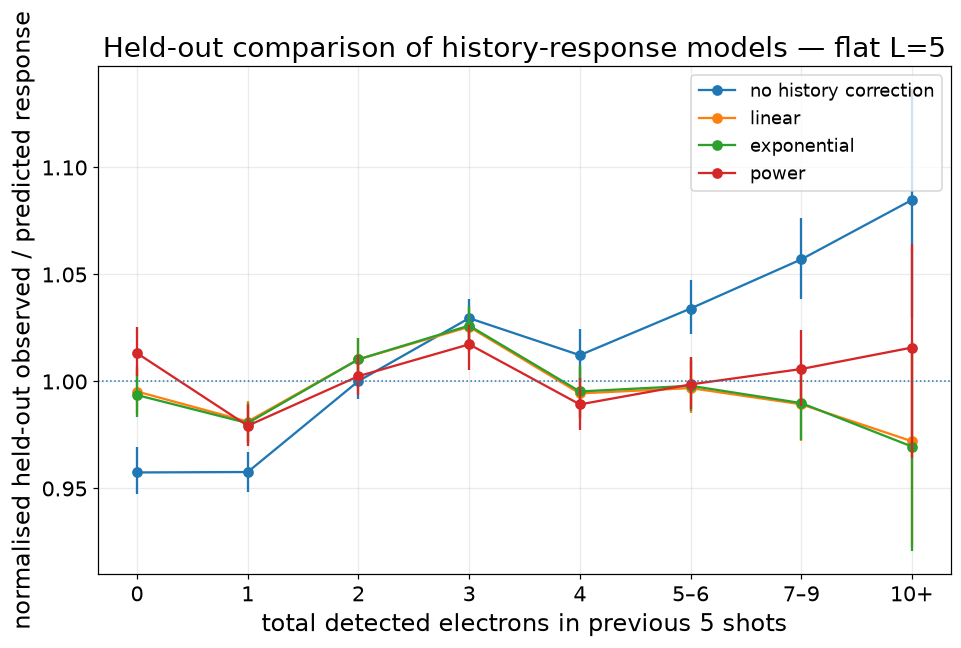

In [ ]:
# --- Held-out model comparison with whole-train bootstrap error bars: flat L=5 ---

COMPARE_H = make_history("flat",5)
COMPARE_MODELS = ["linear","exponential","power"]
COMPARE_BINS = [(0,0,"0"),(1,1,"1"),(2,2,"2"),(3,3,"3"),(4,4,"4"),(5,6,"5–6"),(7,9,"7–9"),(10,np.inf,"10+")]
COMPARE_BOOT_N = 500
COMPARE_BOOT_BATCH = 25
COMPARE_BOOT_SEED = 12345

compare_base = np.full_like(ref_base_explore,np.nan,dtype=float)
compare_pred = {model:np.full_like(ref_base_explore,np.nan,dtype=float) for model in COMPARE_MODELS}

for outer_block in range(EXPLORE_N_BLOCKS):
    train_rows = daq_valid_rows & (explore_block_id != outer_block)
    test_rows = daq_valid_rows & (explore_block_id == outer_block)
    ref_base_train,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],explore_mask[train_rows])
    ref_base_test = apply_bunch_baseline(gmd[test_rows],ref_beta)
    H_train = COMPARE_H[train_rows]; H_test = COMPARE_H[test_rows]
    train_mask = explore_mask[train_rows] & np.isfinite(H_train) & np.isfinite(ref_base_train) & (ref_base_train > 0)
    test_mask = explore_mask[test_rows] & np.isfinite(H_test) & np.isfinite(ref_base_test) & (ref_base_test > 0)
    y_train = data["ref_counts"][train_rows][train_mask].astype(float)
    mu_train = ref_base_train[train_mask].astype(float)
    h_train = H_train[train_mask].astype(float)
    A0 = y_train.sum()/mu_train.sum()
    tmp0 = np.full_like(ref_base_test,np.nan,dtype=float)
    tmp0[test_mask] = ref_base_test[test_mask]*A0
    compare_base[test_rows] = tmp0
    for model in COMPARE_MODELS:
        A,beta = fit_history_factor_fast(y_train,mu_train,h_train,model)
        tmp = np.full_like(ref_base_test,np.nan,dtype=float)
        tmp[test_mask] = ref_base_test[test_mask]*A*history_factor(H_test[test_mask],beta,model)
        compare_pred[model][test_rows] = tmp

valid = daq_valid_rows[:,None] & explore_mask & np.isfinite(COMPARE_H) & np.isfinite(compare_base) & (compare_base > 0)
for model in COMPARE_MODELS: valid &= np.isfinite(compare_pred[model]) & (compare_pred[model] > 0)

n_bins = len(COMPARE_BINS)
labels = [x[2] for x in COMPARE_BINS]
obs_tr = np.zeros((n_trains,n_bins),dtype=float)
base_tr = np.zeros((n_trains,n_bins),dtype=float)
hnum_tr = np.zeros((n_trains,n_bins),dtype=float)
model_tr = {model:np.zeros((n_trains,n_bins),dtype=float) for model in COMPARE_MODELS}

for k,(lo,hi,label) in enumerate(COMPARE_BINS):
    use = valid & (COMPARE_H >= lo) & (COMPARE_H <= hi if np.isfinite(hi) else COMPARE_H >= lo)
    obs_tr[:,k] = np.sum(np.where(use,data["ref_counts"],0),axis=1)
    base_tr[:,k] = np.sum(np.where(use,compare_base,0),axis=1)
    hnum_tr[:,k] = np.sum(np.where(use,compare_base*COMPARE_H,0),axis=1)
    for model in COMPARE_MODELS: model_tr[model][:,k] = np.sum(np.where(use,compare_pred[model],0),axis=1)

keep = base_tr.sum(axis=1) > 0
obs_tr = obs_tr[keep]; base_tr = base_tr[keep]; hnum_tr = hnum_tr[keep]
for model in COMPARE_MODELS: model_tr[model] = model_tr[model][keep]

def normalised_response(obs,pred):
    r = np.divide(obs,pred,out=np.full_like(obs,np.nan,dtype=float),where=pred > 0)
    pooled = obs.sum()/pred.sum()
    return r/pooled

obs_sum = obs_tr.sum(axis=0)
base_sum = base_tr.sum(axis=0)
compare_x = np.divide(hnum_tr.sum(axis=0),base_sum,out=np.full(n_bins,np.nan),where=base_sum > 0)
compare_response = {"baseline":normalised_response(obs_sum,base_sum)}
for model in COMPARE_MODELS: compare_response[model] = normalised_response(obs_sum,model_tr[model].sum(axis=0))

rng = np.random.default_rng(COMPARE_BOOT_SEED)
boot_curves = {name:np.empty((COMPARE_BOOT_N,n_bins),dtype=float) for name in ["baseline"]+COMPARE_MODELS}
boot_x = np.empty((COMPARE_BOOT_N,n_bins),dtype=float)
boot_weights = np.empty((COMPARE_BOOT_N,n_bins),dtype=float)

n_keep = obs_tr.shape[0]
prob = np.full(n_keep,1/n_keep)
done = 0

while done < COMPARE_BOOT_N:
    m = min(COMPARE_BOOT_BATCH,COMPARE_BOOT_N-done)
    counts = rng.multinomial(n_keep,prob,size=m)
    obs_b = counts@obs_tr
    base_b = counts@base_tr
    hnum_b = counts@hnum_tr
    boot_x[done:done+m] = np.divide(hnum_b,base_b,out=np.full_like(hnum_b,np.nan),where=base_b > 0)
    boot_weights[done:done+m] = base_b

    pooled = obs_b.sum(axis=1)/base_b.sum(axis=1)
    boot_curves["baseline"][done:done+m] = np.divide(obs_b,base_b,out=np.full_like(obs_b,np.nan),where=base_b > 0)/pooled[:,None]

    for model in COMPARE_MODELS:
        pred_b = counts@model_tr[model]
        pooled = obs_b.sum(axis=1)/pred_b.sum(axis=1)
        boot_curves[model][done:done+m] = np.divide(obs_b,pred_b,out=np.full_like(obs_b,np.nan),where=pred_b > 0)/pooled[:,None]

    done += m

fig,ax = plt.subplots(figsize=(10,6))

for name,label in [("baseline","no history correction"),("linear","linear"),("exponential","exponential"),("power","power")]:
    y = compare_response[name]
    low = np.nanpercentile(boot_curves[name],16,axis=0)
    high = np.nanpercentile(boot_curves[name],84,axis=0)
    line, = ax.plot(np.arange(n_bins),y,"o-",label=label)
    ax.vlines(np.arange(n_bins),low,high,color=line.get_color(),lw=1.5)

ax.axhline(1,ls=":",lw=1)
ax.set_xticks(np.arange(n_bins),labels)
ax.set(xlabel="total detected electrons in previous 5 shots",ylabel="normalised held-out observed / predicted response",title="Held-out comparison of history-response models — flat L=5")
ax.grid(alpha=0.25); ax.legend()
plt.show()

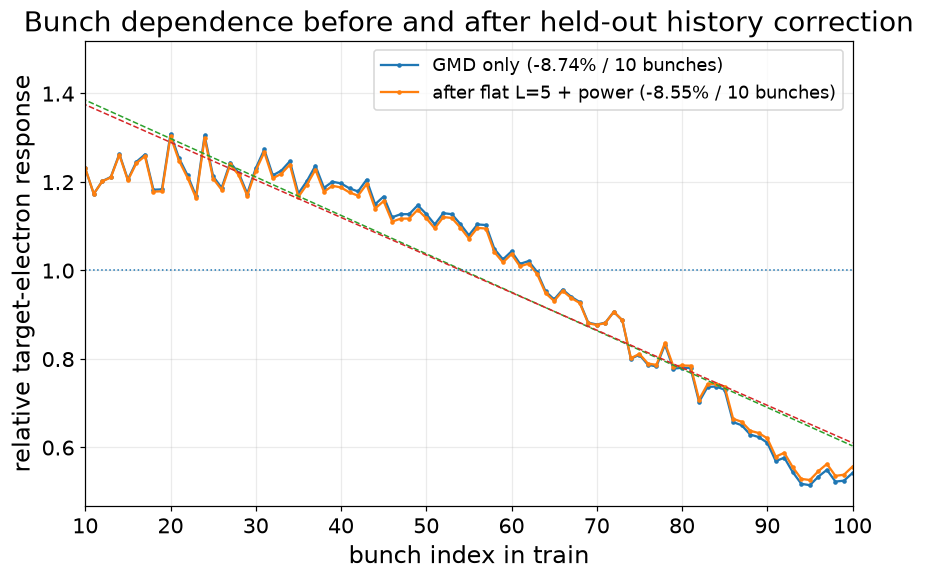

GMD only:                       -8.740% / 10 bunches
After flat L=5 + power      : -8.554% / 10 bunches
Slope change:                   +0.186% / 10 bunches
Reduction in |slope|:           2.13%


In [ ]:
# --- Does the held-out flat-L=5 history correction explain the bunch-position slope? ---

HISTORY_S_MODEL = "power"  # "linear", "exponential", or "power"
HISTORY_H = make_history("flat",5)

history_factor_cv = np.full_like(gmd,np.nan,dtype=float)
history_beta_cv = []

for outer_block in range(EXPLORE_N_BLOCKS):
    train_rows = daq_valid_rows & (explore_block_id != outer_block)
    test_rows = daq_valid_rows & (explore_block_id == outer_block)

    ref_base_train,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],explore_mask[train_rows])
    H_train = HISTORY_H[train_rows]
    train_mask = explore_mask[train_rows] & np.isfinite(H_train) & np.isfinite(ref_base_train) & (ref_base_train > 0)

    y_train = data["ref_counts"][train_rows][train_mask].astype(float)
    mu_train = ref_base_train[train_mask].astype(float)
    h_train = H_train[train_mask].astype(float)

    A,beta = fit_history_factor_fast(y_train,mu_train,h_train,HISTORY_S_MODEL)
    history_beta_cv.append(beta)

    H_test = HISTORY_H[test_rows]
    valid_test = explore_mask[test_rows] & np.isfinite(H_test)
    tmp = np.full(H_test.shape,np.nan,dtype=float)
    tmp[valid_test] = A*history_factor(H_test[valid_test],beta,HISTORY_S_MODEL)
    history_factor_cv[test_rows] = tmp

selected = daq_valid_rows[:,None] & explore_mask & np.isfinite(HISTORY_H) & np.isfinite(history_factor_cv) & (history_factor_cv > 0)

obs = band_sums(data["target_counts"].astype(float),gmd,selected)
shots = band_sums(np.ones_like(gmd),gmd,selected)
norm_gmd = band_sums(gmd,gmd,selected)
norm_history = band_sums(gmd*history_factor_cv,gmd,selected)

m_before = bunch_metrics(obs,norm_gmd,shots)
m_after = bunch_metrics(obs,norm_history,shots)

profile_before = combined_relative_profile(m_before,shots)
profile_after = combined_relative_profile(m_after,shots)
profile_weights = shots.sum(axis=0)

line_before = weighted_bunch_line(profile_before,profile_weights,INDEP_BUNCH_START)
line_after = weighted_bunch_line(profile_after,profile_weights,INDEP_BUNCH_START)

b = np.arange(n_bunch)
fig,ax = plt.subplots(figsize=(9,5.5))
ax.plot(b,profile_before,".-",ms=4,lw=1.5,label=f"GMD only ({m_before['slope']:+.2f}% / 10 bunches)")
ax.plot(b,profile_after,".-",ms=4,lw=1.5,label=f"after flat L=5 + {HISTORY_S_MODEL} ({m_after['slope']:+.2f}% / 10 bunches)")
ax.plot(b,line_before[0]*b+line_before[1],"--",lw=1)
ax.plot(b,line_after[0]*b+line_after[1],"--",lw=1)
ax.axhline(1,ls=":",lw=1)
ax.set_xlim(INDEP_BUNCH_START,n_bunch-1)
ax.set(xlabel="bunch index in train",ylabel="relative target-electron response",title="Bunch dependence before and after held-out history correction")
ax.grid(alpha=0.25); ax.legend()
plt.show()

slope_change = m_after["slope"]-m_before["slope"]
slope_reduction = 100*(1-abs(m_after["slope"])/abs(m_before["slope"]))
print(f"GMD only:                       {m_before['slope']:+.3f}% / 10 bunches")
print(f"After flat L=5 + {HISTORY_S_MODEL:11s}: {m_after['slope']:+.3f}% / 10 bunches")
print(f"Slope change:                   {slope_change:+.3f}% / 10 bunches")
print(f"Reduction in |slope|:           {slope_reduction:.2f}%")

,slope (% response / +5 previous e-),68% low,68% high,|slope| reduction (%)
model,,,,
baseline,7.0925,6.0307,7.9967,0.0000
linear,0.1645,-0.8592,1.0609,97.6813
exponential,0.3169,-0.7062,1.2112,95.5319
power,0.2911,-0.7546,1.1932,95.8958


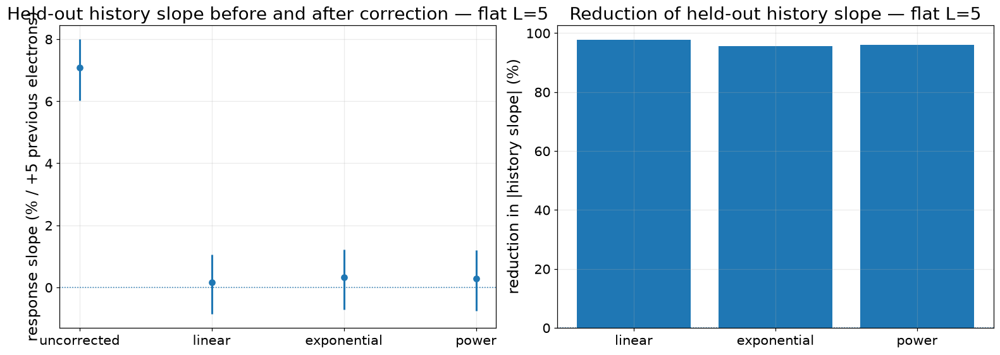

In [ ]:
# --- Residual history slope before and after each correction: flat L=5 ---

def weighted_slope(x,y,w):
    use = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (w > 0)
    x = x[use]; y = y[use]; w = w[use]
    xm = np.average(x,weights=w); ym = np.average(y,weights=w)
    return np.sum(w*(x-xm)*(y-ym))/np.sum(w*(x-xm)**2)

slope_names = ["baseline"]+COMPARE_MODELS
slope_point = {}
slope_boot = {}

for name in slope_names:
    slope_point[name] = 100*5*weighted_slope(compare_x,compare_response[name],base_sum)
    slope_boot[name] = np.array([100*5*weighted_slope(boot_x[i],boot_curves[name][i],boot_weights[i]) for i in range(COMPARE_BOOT_N)])

baseline_abs = abs(slope_point["baseline"])
slope_rows = []

for name in slope_names:
    low,high = np.percentile(slope_boot[name],[16,84])
    reduction = 0.0 if name == "baseline" else 100*(1-abs(slope_point[name])/baseline_abs)
    slope_rows.append({"model":name,"slope (% response / +5 previous e-)":slope_point[name],"68% low":low,"68% high":high,"|slope| reduction (%)":reduction})

slope_table = pd.DataFrame(slope_rows).set_index("model")
display(slope_table.round(4))

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

x = np.arange(len(slope_names))
y = np.array([slope_point[name] for name in slope_names])
low = np.array([np.percentile(slope_boot[name],16) for name in slope_names])
high = np.array([np.percentile(slope_boot[name],84) for name in slope_names])

axes[0].vlines(x,low,high,lw=2)
axes[0].scatter(x,y,zorder=3)
axes[0].axhline(0,ls=":",lw=1)
axes[0].set_xticks(x,["uncorrected","linear","exponential","power"])
axes[0].set(ylabel="response slope (% / +5 previous electrons)",title="Held-out history slope before and after correction — flat L=5")
axes[0].grid(alpha=0.25)

reductions = [100*(1-abs(slope_point[name])/baseline_abs) for name in COMPARE_MODELS]
axes[1].bar(np.arange(3),reductions)
axes[1].axhline(0,ls=":",lw=1)
axes[1].set_xticks(np.arange(3),COMPARE_MODELS)
axes[1].set(ylabel="reduction in |history slope| (%)",title="Reduction of held-out history slope — flat L=5")
axes[1].grid(alpha=0.25)

plt.show()

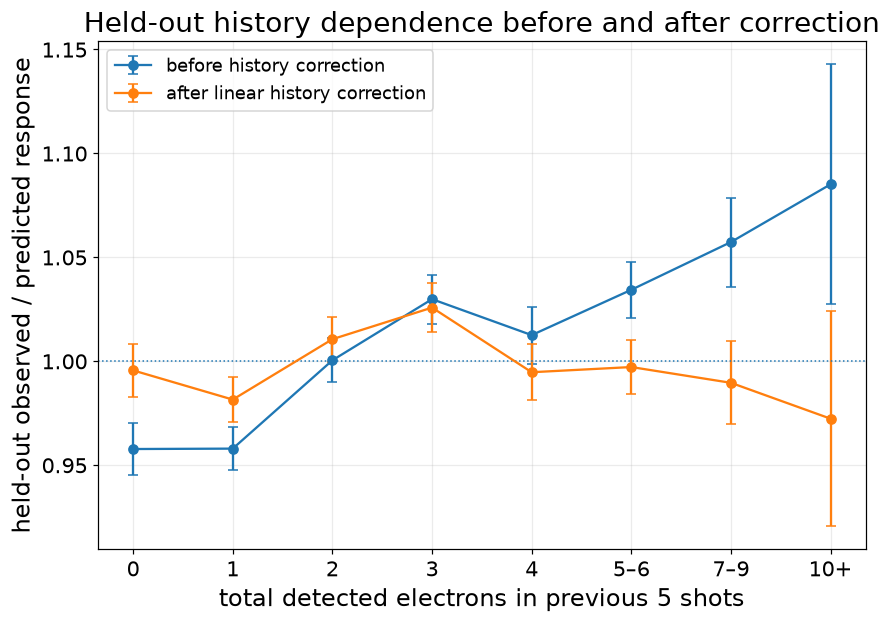

Linear beta across outer folds: 0.01451 ± 0.00081


In [ ]:
# --- Meeting plot: held-out history dependence before and after simple linear correction ---

MEETING_H = make_history("flat",5)
MEETING_BINS = [(0,0,"0"),(1,1,"1"),(2,2,"2"),(3,3,"3"),(4,4,"4"),(5,6,"5–6"),(7,9,"7–9"),(10,np.inf,"10+")]
meeting_pred = np.full_like(ref_base_explore,np.nan,dtype=float)
meeting_beta = []

for outer_block in range(EXPLORE_N_BLOCKS):
    train_rows = daq_valid_rows & (explore_block_id != outer_block)
    test_rows = daq_valid_rows & (explore_block_id == outer_block)
    ref_base_train,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],explore_mask[train_rows])
    ref_base_test = apply_bunch_baseline(gmd[test_rows],ref_beta)
    H_train = MEETING_H[train_rows]; H_test = MEETING_H[test_rows]
    train_mask = explore_mask[train_rows] & np.isfinite(H_train) & np.isfinite(ref_base_train) & (ref_base_train > 0)
    A,beta = fit_history_factor_fast(data["ref_counts"][train_rows][train_mask].astype(float),ref_base_train[train_mask],H_train[train_mask],"linear")
    meeting_beta.append(beta)
    test_mask = explore_mask[test_rows] & np.isfinite(H_test) & np.isfinite(ref_base_test) & (ref_base_test > 0)
    tmp = np.full_like(ref_base_test,np.nan,dtype=float)
    tmp[test_mask] = ref_base_test[test_mask]*A*history_factor(H_test[test_mask],beta,"linear")
    meeting_pred[test_rows] = tmp

valid = daq_valid_rows[:,None] & explore_mask & np.isfinite(MEETING_H) & np.isfinite(ref_base_explore) & (ref_base_explore > 0) & np.isfinite(meeting_pred) & (meeting_pred > 0)
before,after,before_err,after_err = [],[],[],[]

for lo,hi,label in MEETING_BINS:
    use = valid & (MEETING_H >= lo) & (MEETING_H <= hi if np.isfinite(hi) else MEETING_H >= lo)
    y = data["ref_counts"][use].astype(float)
    mu0 = ref_base_explore[use]
    mu1 = meeting_pred[use]
    before.append(y.sum()/mu0.sum()); after.append(y.sum()/mu1.sum())
    before_err.append(np.sqrt(y.sum())/mu0.sum()); after_err.append(np.sqrt(y.sum())/mu1.sum())

x = np.arange(len(MEETING_BINS))
labels = [b[2] for b in MEETING_BINS]

fig,ax = plt.subplots(figsize=(9,6))
ax.errorbar(x,before,yerr=before_err,fmt="o-",capsize=3,label="before history correction")
ax.errorbar(x,after,yerr=after_err,fmt="o-",capsize=3,label="after linear history correction")
ax.axhline(1,ls=":",lw=1)
ax.set_xticks(x,labels)
ax.set(xlabel="total detected electrons in previous 5 shots",ylabel="held-out observed / predicted response",title="Held-out history dependence before and after correction")
ax.grid(alpha=0.25); ax.legend()
plt.show()

print(f"Linear beta across outer folds: {np.mean(meeting_beta):.5f} ± {np.std(meeting_beta,ddof=1):.5f}")

,H family,parameter,S(H),reference improvement (%),target improvement (%),beta mean,beta std
5,exponential,5,power,0.011541,0.027345,0.062109,0.004682
2,flat,10,power,0.010720,0.029649,0.051790,0.003678
3,exponential,5,linear,0.010116,0.024125,0.017794,0.001642
4,exponential,5,exponential,0.009934,0.023730,0.016483,0.001459
8,active,2,power,0.003916,0.008795,0.043279,0.003252
6,active,2,linear,0.003830,0.008751,0.026555,0.002694
7,active,2,exponential,0.003810,0.008733,0.025949,0.002647
0,flat,2,linear,0.002747,0.008287,0.012116,0.001591
1,flat,2,exponential,0.002703,0.008184,0.011751,0.001574


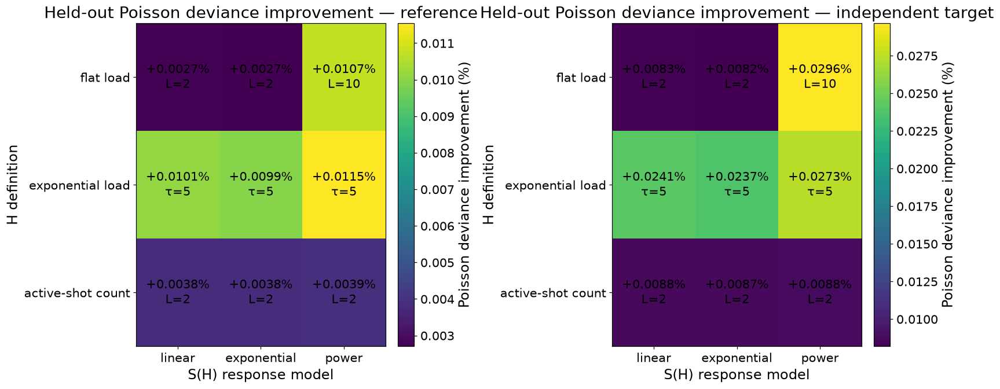

In [ ]:
# --- Held-out Poisson-deviance comparison for the aggregate-selected H x S(H) models ---

deviance_rows = []

for _,choice in aggregate_best_table.iterrows():
    family = choice["H family"]; param = choice["parameter"]; model = choice["S(H)"]
    H = make_history(family,param)
    ref_d0 = ref_d1 = target_d0 = target_d1 = 0.0
    betas = []
    for held_block in range(EXPLORE_N_BLOCKS):
        train_rows = daq_valid_rows & (explore_block_id != held_block)
        test_rows = daq_valid_rows & (explore_block_id == held_block)
        train_mask = train_rows[:,None] & explore_mask & np.isfinite(H) & np.isfinite(ref_base_explore) & (ref_base_explore > 0)
        ref_test = test_rows[:,None] & explore_mask & np.isfinite(H) & np.isfinite(ref_base_explore) & (ref_base_explore > 0)
        target_test = test_rows[:,None] & explore_mask & np.isfinite(H) & np.isfinite(target_base_explore) & (target_base_explore > 0)
        y_train = data["ref_counts"][train_mask].astype(float); mu_train = ref_base_explore[train_mask]; h_train = H[train_mask]
        A0 = y_train.sum()/mu_train.sum()
        A,beta = fit_history_factor_fast(y_train,mu_train,h_train,model)
        betas.append(beta)
        y_ref = data["ref_counts"][ref_test].astype(float); mu_ref0 = ref_base_explore[ref_test]*A0; mu_ref1 = ref_base_explore[ref_test]*A*history_factor(H[ref_test],beta,model)
        y_target = data["target_counts"][target_test].astype(float); mu_target0 = target_base_explore[target_test]*A0; mu_target1 = target_base_explore[target_test]*A*history_factor(H[target_test],beta,model)
        ref_d0 += poisson_deviance(y_ref,mu_ref0); ref_d1 += poisson_deviance(y_ref,mu_ref1)
        target_d0 += poisson_deviance(y_target,mu_target0); target_d1 += poisson_deviance(y_target,mu_target1)
    deviance_rows.append({"H family":family,"parameter":param,"S(H)":model,"reference improvement (%)":100*(1-ref_d1/ref_d0),"target improvement (%)":100*(1-target_d1/target_d0),"beta mean":np.mean(betas),"beta std":np.std(betas,ddof=1)})
    del H

deviance_model_table = pd.DataFrame(deviance_rows)
display(deviance_model_table.sort_values("reference improvement (%)",ascending=False).round(6))

ref_matrix = deviance_model_table.pivot(index="H family",columns="S(H)",values="reference improvement (%)").reindex(index=["flat","exponential","active"],columns=S_MODELS)
target_matrix = deviance_model_table.pivot(index="H family",columns="S(H)",values="target improvement (%)").reindex(index=["flat","exponential","active"],columns=S_MODELS)
param_matrix = deviance_model_table.pivot(index="H family",columns="S(H)",values="parameter").reindex(index=["flat","exponential","active"],columns=S_MODELS)

fig,axes = plt.subplots(1,2,figsize=(15,6),constrained_layout=True)
for ax,matrix,title in [(axes[0],ref_matrix,"Held-out Poisson deviance improvement — reference"),(axes[1],target_matrix,"Held-out Poisson deviance improvement — independent target")]:
    im = ax.imshow(matrix.values,aspect="auto")
    ax.set_xticks(np.arange(len(S_MODELS)),S_MODELS)
    ax.set_yticks(np.arange(3),["flat load","exponential load","active-shot count"])
    ax.set(xlabel="S(H) response model",ylabel="H definition",title=title)
    for i in range(3):
        for j in range(3):
            p = param_matrix.iloc[i,j]
            label = f"L={int(p)}" if matrix.index[i] != "exponential" else f"τ={p:g}"
            ax.text(j,i,f"{matrix.iloc[i,j]:+.4f}%\n{label}",ha="center",va="center")
    fig.colorbar(im,ax=ax,label="Poisson deviance improvement (%)")
plt.show()

## Ion spectrum degradation

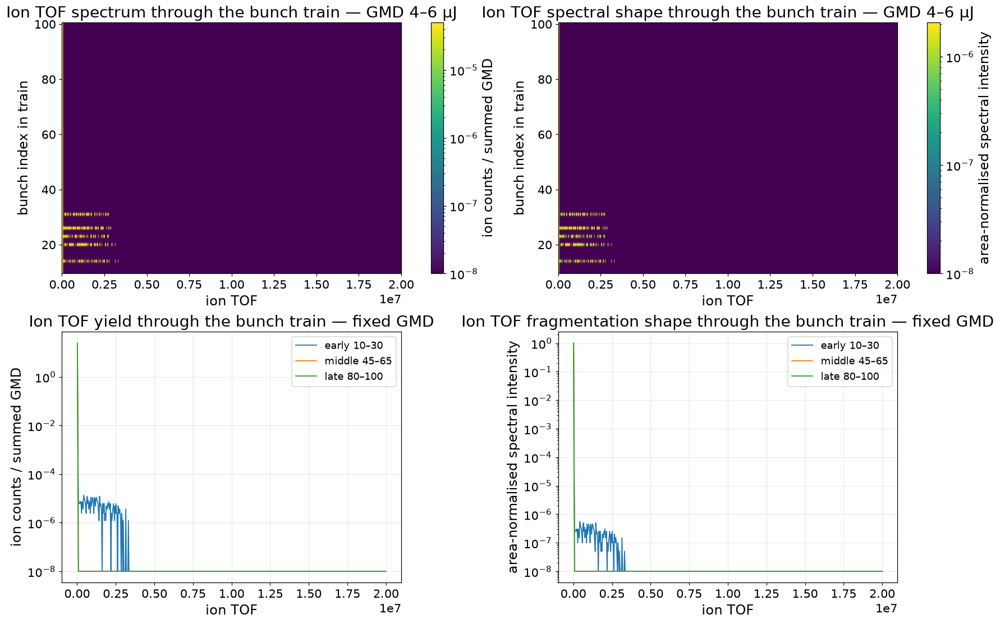

TOF focus range: 0 to 2e+07
 early bunches 10– 30: shots=166,012, summed GMD=823614.7 µJ
middle bunches 45– 65: shots=130,198, summed GMD=653934.3 µJ
  late bunches 80–100: shots=132,764, summed GMD=658195.8 µJ


In [ ]:
# --- Ion TOF spectral shape through the bunch train at fixed GMD, focused on low TOF ---

from matplotlib.colors import LogNorm

ION_SHAPE_GMD_RANGE = (4.0,6.0)
ION_TOF_RANGE = (0.0,2.0e7)
ION_TOF_BINS = 600
ION_BUNCH_GROUPS = {"early":(10,30),"middle":(45,65),"late":(80,100)}
ION_PLOT_FLOOR = 1e-8

ion_tof_edges = np.linspace(ION_TOF_RANGE[0],ION_TOF_RANGE[1],ION_TOF_BINS+1)
ion_tof_centres = 0.5*(ion_tof_edges[:-1]+ion_tof_edges[1:])
ion_spectra = np.zeros((n_bunch,ION_TOF_BINS),dtype=float)
ion_gmd_sum = np.zeros(n_bunch,dtype=float)
ion_shot_count = np.zeros(n_bunch,dtype=np.int64)

with h5py.File(source_h5,"r") as handle:
    for start in range(0,n_trains,INDEP_CHUNK_TRAINS):
        stop = min(start+INDEP_CHUNK_TRAINS,n_trains)
        g = gmd[start:stop]
        tof = handle["tofs_i"][start:stop]
        valid = daq_valid_rows[start:stop,None] & np.isfinite(g) & (g >= ION_SHAPE_GMD_RANGE[0]) & (g < ION_SHAPE_GMD_RANGE[1])
        for b in range(INDEP_BUNCH_START,n_bunch):
            rows = valid[:,b]
            if not np.any(rows): continue
            hits = tof[rows,b].ravel()
            hits = hits[(hits >= ION_TOF_RANGE[0]) & (hits < ION_TOF_RANGE[1])]
            if hits.size == 0: continue
            ion_spectra[b] += np.histogram(hits,bins=ion_tof_edges)[0]
            ion_gmd_sum[b] += g[rows,b].sum()
            ion_shot_count[b] += rows.sum()

ion_per_gmd = np.divide(ion_spectra,ion_gmd_sum[:,None],out=np.full_like(ion_spectra,np.nan),where=ion_gmd_sum[:,None] > 0)
ion_shape = np.divide(ion_per_gmd,np.nansum(ion_per_gmd,axis=1,keepdims=True),out=np.full_like(ion_per_gmd,np.nan),where=np.nansum(ion_per_gmd,axis=1,keepdims=True) > 0)

group_abs,group_shape = {},{}
for name,(lo,hi) in ION_BUNCH_GROUPS.items():
    use = np.arange(lo,min(hi+1,n_bunch))
    spec = np.nansum(ion_spectra[use],axis=0)
    gsum = np.nansum(ion_gmd_sum[use])
    group_abs[name] = np.maximum(spec/gsum,ION_PLOT_FLOOR)
    group_shape[name] = np.maximum(group_abs[name]/np.nansum(group_abs[name]),ION_PLOT_FLOOR)

abs_map = np.maximum(ion_per_gmd[INDEP_BUNCH_START:],ION_PLOT_FLOOR)
shape_map = np.maximum(ion_shape[INDEP_BUNCH_START:],ION_PLOT_FLOOR)
abs_vmin = np.nanpercentile(abs_map[np.isfinite(abs_map)],5)
abs_vmax = np.nanpercentile(abs_map[np.isfinite(abs_map)],99.5)
shape_vmin = np.nanpercentile(shape_map[np.isfinite(shape_map)],5)
shape_vmax = np.nanpercentile(shape_map[np.isfinite(shape_map)],99.5)

fig,axes = plt.subplots(2,2,figsize=(16,10),constrained_layout=True)
extent = [ion_tof_edges[0],ion_tof_edges[-1],INDEP_BUNCH_START-0.5,n_bunch-0.5]
im0 = axes[0,0].imshow(abs_map,aspect="auto",origin="lower",extent=extent,norm=LogNorm(vmin=max(abs_vmin,ION_PLOT_FLOOR),vmax=max(abs_vmax,10*ION_PLOT_FLOOR)))
axes[0,0].set(xlabel="ion TOF",ylabel="bunch index in train",title=f"Ion TOF spectrum through the bunch train — GMD {ION_SHAPE_GMD_RANGE[0]:g}–{ION_SHAPE_GMD_RANGE[1]:g} µJ")
fig.colorbar(im0,ax=axes[0,0],label="ion counts / summed GMD")

im1 = axes[0,1].imshow(shape_map,aspect="auto",origin="lower",extent=extent,norm=LogNorm(vmin=max(shape_vmin,ION_PLOT_FLOOR),vmax=max(shape_vmax,10*ION_PLOT_FLOOR)))
axes[0,1].set(xlabel="ion TOF",ylabel="bunch index in train",title=f"Ion TOF spectral shape through the bunch train — GMD {ION_SHAPE_GMD_RANGE[0]:g}–{ION_SHAPE_GMD_RANGE[1]:g} µJ")
fig.colorbar(im1,ax=axes[0,1],label="area-normalised spectral intensity")

for name in ION_BUNCH_GROUPS: axes[1,0].plot(ion_tof_centres,group_abs[name],lw=1.2,label=f"{name} {ION_BUNCH_GROUPS[name][0]}–{ION_BUNCH_GROUPS[name][1]}")
axes[1,0].set(xlabel="ion TOF",ylabel="ion counts / summed GMD",title="Ion TOF yield through the bunch train — fixed GMD")
axes[1,0].set_yscale("log"); axes[1,0].grid(alpha=0.25); axes[1,0].legend()

for name in ION_BUNCH_GROUPS: axes[1,1].plot(ion_tof_centres,group_shape[name],lw=1.2,label=f"{name} {ION_BUNCH_GROUPS[name][0]}–{ION_BUNCH_GROUPS[name][1]}")
axes[1,1].set(xlabel="ion TOF",ylabel="area-normalised spectral intensity",title="Ion TOF fragmentation shape through the bunch train — fixed GMD")
axes[1,1].set_yscale("log"); axes[1,1].grid(alpha=0.25); axes[1,1].legend()
plt.show()

print(f"TOF focus range: {ION_TOF_RANGE[0]:.3g} to {ION_TOF_RANGE[1]:.3g}")
for name,(lo,hi) in ION_BUNCH_GROUPS.items():
    use = np.arange(lo,min(hi+1,n_bunch))
    print(f"{name:>6s} bunches {lo:2d}–{hi:3d}: shots={ion_shot_count[use].sum():,}, summed GMD={ion_gmd_sum[use].sum():.1f} µJ")

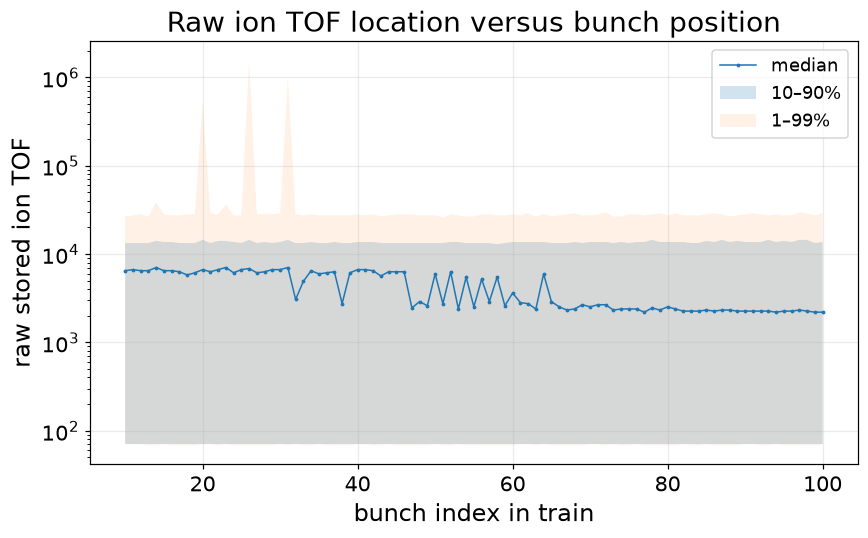

In [ ]:
# --- Fast lightweight diagnostic of raw ion-TOF coordinate versus bunch position ---

ION_DIAG_GMD_RANGE = (4.0,6.0)
ION_DIAG_TOF_BINS = 800
ION_DIAG_CHUNK_TRAINS = 250

tof_edges_diag = np.geomspace(1,np.iinfo(np.uint32).max,ION_DIAG_TOF_BINS+1)
tof_centres_diag = np.sqrt(tof_edges_diag[:-1]*tof_edges_diag[1:])
bunch_edges_diag = np.arange(-0.5,n_bunch+0.5,1)
tof_hist_diag = np.zeros((n_bunch,ION_DIAG_TOF_BINS),dtype=np.int64)
bunch_index_template = np.arange(n_bunch)[None,:,None]

with h5py.File(source_h5,"r") as handle:
    for start in range(0,n_trains,ION_DIAG_CHUNK_TRAINS):
        stop = min(start+ION_DIAG_CHUNK_TRAINS,n_trains)
        tof = handle["tofs_i"][start:stop]
        g = gmd[start:stop]
        valid_shot = daq_valid_rows[start:stop,None] & np.isfinite(g) & (g >= ION_DIAG_GMD_RANGE[0]) & (g < ION_DIAG_GMD_RANGE[1])
        valid_shot[:,:INDEP_BUNCH_START] = False
        valid_hit = (tof > 0) & valid_shot[:,:,None]
        if not np.any(valid_hit): continue
        hit_tof = tof[valid_hit]
        hit_bunch = np.broadcast_to(bunch_index_template,tof.shape)[valid_hit]
        h,_,_ = np.histogram2d(hit_bunch,hit_tof,bins=[bunch_edges_diag,tof_edges_diag])
        tof_hist_diag += h.astype(np.int64)

def histogram_quantile(counts,centres,q):
    total = counts.sum()
    if total == 0: return np.nan
    return centres[np.searchsorted(np.cumsum(counts),q*total)]

ion_tof_q_diag = np.full((n_bunch,5),np.nan)
for b in range(INDEP_BUNCH_START,n_bunch):
    for j,q in enumerate([0.01,0.10,0.50,0.90,0.99]): ion_tof_q_diag[b,j] = histogram_quantile(tof_hist_diag[b],tof_centres_diag,q)

b = np.arange(INDEP_BUNCH_START,n_bunch)
fig,ax = plt.subplots(figsize=(9,5))
ax.plot(b,ion_tof_q_diag[b,2],".-",ms=3,lw=1,label="median")
ax.fill_between(b,ion_tof_q_diag[b,1],ion_tof_q_diag[b,3],alpha=0.2,label="10–90%")
ax.fill_between(b,ion_tof_q_diag[b,0],ion_tof_q_diag[b,4],alpha=0.1,label="1–99%")
ax.set_yscale("log")
ax.set(xlabel="bunch index in train",ylabel="raw stored ion TOF",title="Raw ion TOF location versus bunch position")
ax.grid(alpha=0.25); ax.legend()
plt.show()

In [ ]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:           503Gi        80Gi       386Gi       201Mi        40Gi       422Gi
Swap:          4.0Gi          0B       4.0Gi


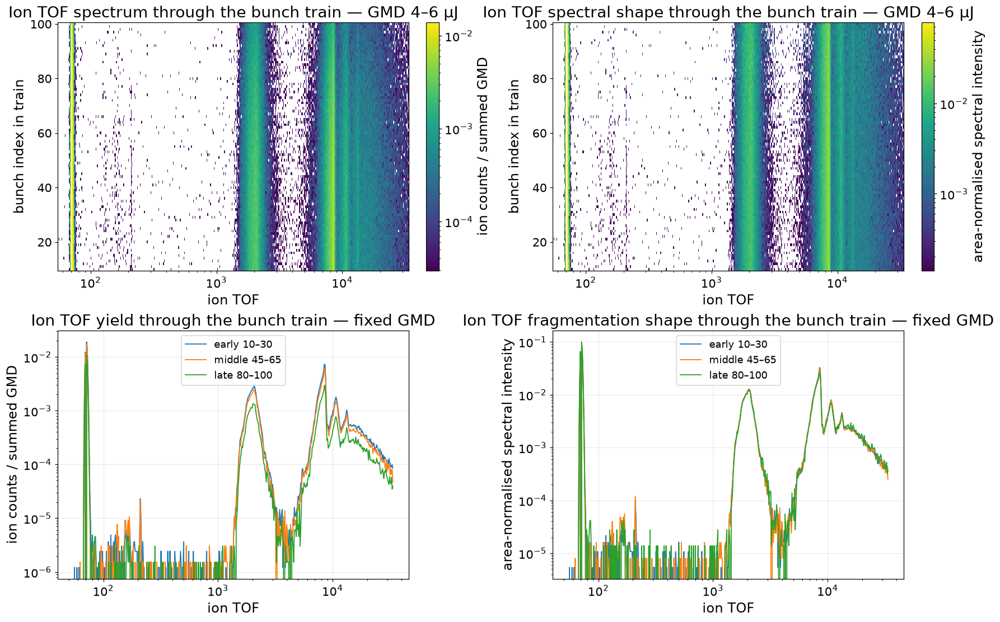

TOF range: 54.9–33760.2
 early: shots=166,012, summed GMD=823614.7 µJ
middle: shots=130,198, summed GMD=653934.3 µJ
  late: shots=132,764, summed GMD=658195.8 µJ


In [ ]:
# --- Ion TOF spectral shape through the bunch train at fixed GMD ---

from matplotlib.colors import LogNorm

ION_SHAPE_GMD_RANGE = (4.0,6.0)
ION_TOF_BINS = 500
ION_BUNCH_GROUPS = {"early":(10,30),"middle":(45,65),"late":(80,100)}
ION_CHUNK_TRAINS = 250

b_diag = np.arange(INDEP_BUNCH_START,n_bunch)
ION_TOF_RANGE = (max(1,np.nanmedian(ion_tof_q_diag[b_diag,0])*0.8),np.nanmedian(ion_tof_q_diag[b_diag,4])*1.2)
ion_tof_edges = np.geomspace(ION_TOF_RANGE[0],ION_TOF_RANGE[1],ION_TOF_BINS+1)
ion_tof_centres = np.sqrt(ion_tof_edges[:-1]*ion_tof_edges[1:])
bunch_edges = np.arange(-0.5,n_bunch+0.5,1)
ion_spectra = np.zeros((n_bunch,ION_TOF_BINS),dtype=np.int64)
ion_gmd_sum = np.zeros(n_bunch,dtype=float)
ion_shot_count = np.zeros(n_bunch,dtype=np.int64)
bunch_index_template = np.arange(n_bunch)[None,:,None]

with h5py.File(source_h5,"r") as handle:
    for start in range(0,n_trains,ION_CHUNK_TRAINS):
        stop = min(start+ION_CHUNK_TRAINS,n_trains)
        tof = handle["tofs_i"][start:stop]
        g = gmd[start:stop]
        valid_shot = daq_valid_rows[start:stop,None] & np.isfinite(g) & (g >= ION_SHAPE_GMD_RANGE[0]) & (g < ION_SHAPE_GMD_RANGE[1])
        valid_shot[:,:INDEP_BUNCH_START] = False
        ion_gmd_sum += np.sum(np.where(valid_shot,g,0),axis=0)
        ion_shot_count += np.sum(valid_shot,axis=0)
        valid_hit = valid_shot[:,:,None] & (tof > 0) & (tof >= ION_TOF_RANGE[0]) & (tof < ION_TOF_RANGE[1])
        if not np.any(valid_hit): continue
        hit_tof = tof[valid_hit]
        hit_bunch = np.broadcast_to(bunch_index_template,tof.shape)[valid_hit]
        h,_,_ = np.histogram2d(hit_bunch,hit_tof,bins=[bunch_edges,ion_tof_edges])
        ion_spectra += h.astype(np.int64)

ion_per_gmd = np.divide(ion_spectra,ion_gmd_sum[:,None],out=np.full(ion_spectra.shape,np.nan,dtype=float),where=ion_gmd_sum[:,None] > 0)
ion_shape = np.divide(ion_per_gmd,np.nansum(ion_per_gmd,axis=1,keepdims=True),out=np.full_like(ion_per_gmd,np.nan),where=np.nansum(ion_per_gmd,axis=1,keepdims=True) > 0)

group_abs,group_shape = {},{}
for name,(lo,hi) in ION_BUNCH_GROUPS.items():
    idx = np.arange(lo,min(hi+1,n_bunch))
    spec = ion_spectra[idx].sum(axis=0)
    gsum = ion_gmd_sum[idx].sum()
    group_abs[name] = spec/gsum
    group_shape[name] = group_abs[name]/group_abs[name].sum()

abs_positive = ion_per_gmd[(ion_per_gmd > 0) & np.isfinite(ion_per_gmd)]
shape_positive = ion_shape[(ion_shape > 0) & np.isfinite(ion_shape)]
abs_norm = LogNorm(vmin=np.percentile(abs_positive,5),vmax=np.percentile(abs_positive,99.5))
shape_norm = LogNorm(vmin=np.percentile(shape_positive,5),vmax=np.percentile(shape_positive,99.5))

fig,axes = plt.subplots(2,2,figsize=(16,10),constrained_layout=True)
im0 = axes[0,0].pcolormesh(ion_tof_edges,bunch_edges,np.ma.masked_less_equal(ion_per_gmd,0),shading="auto",norm=abs_norm)
axes[0,0].set_xscale("log"); axes[0,0].set_ylim(INDEP_BUNCH_START-0.5,n_bunch-0.5)
axes[0,0].set(xlabel="ion TOF",ylabel="bunch index in train",title=f"Ion TOF spectrum through the bunch train — GMD {ION_SHAPE_GMD_RANGE[0]:g}–{ION_SHAPE_GMD_RANGE[1]:g} µJ")
fig.colorbar(im0,ax=axes[0,0],label="ion counts / summed GMD")

im1 = axes[0,1].pcolormesh(ion_tof_edges,bunch_edges,np.ma.masked_less_equal(ion_shape,0),shading="auto",norm=shape_norm)
axes[0,1].set_xscale("log"); axes[0,1].set_ylim(INDEP_BUNCH_START-0.5,n_bunch-0.5)
axes[0,1].set(xlabel="ion TOF",ylabel="bunch index in train",title=f"Ion TOF spectral shape through the bunch train — GMD {ION_SHAPE_GMD_RANGE[0]:g}–{ION_SHAPE_GMD_RANGE[1]:g} µJ")
fig.colorbar(im1,ax=axes[0,1],label="area-normalised spectral intensity")

for name in ION_BUNCH_GROUPS: axes[1,0].plot(ion_tof_centres,group_abs[name],lw=1.2,label=f"{name} {ION_BUNCH_GROUPS[name][0]}–{ION_BUNCH_GROUPS[name][1]}")
axes[1,0].set_xscale("log"); axes[1,0].set_yscale("log")
axes[1,0].set(xlabel="ion TOF",ylabel="ion counts / summed GMD",title="Ion TOF yield through the bunch train — fixed GMD")
axes[1,0].grid(alpha=0.25); axes[1,0].legend()

for name in ION_BUNCH_GROUPS: axes[1,1].plot(ion_tof_centres,group_shape[name],lw=1.2,label=f"{name} {ION_BUNCH_GROUPS[name][0]}–{ION_BUNCH_GROUPS[name][1]}")
axes[1,1].set_xscale("log"); axes[1,1].set_yscale("log")
axes[1,1].set(xlabel="ion TOF",ylabel="area-normalised spectral intensity",title="Ion TOF fragmentation shape through the bunch train — fixed GMD")
axes[1,1].grid(alpha=0.25); axes[1,1].legend()
plt.show()

print(f"TOF range: {ION_TOF_RANGE[0]:.1f}–{ION_TOF_RANGE[1]:.1f}")
for name,(lo,hi) in ION_BUNCH_GROUPS.items():
    idx = np.arange(lo,min(hi+1,n_bunch))
    print(f"{name:>6s}: shots={ion_shot_count[idx].sum():,}, summed GMD={ion_gmd_sum[idx].sum():.1f} µJ")

## 9. Observations and open questions
All code cells completed on the full 35,439-train dataset with the saved scientific settings. The conclusions below separate measured associations from possible mechanisms.

- **Bunch-position effect:** the local GMD-versus-reference panels and bunch-specific response slopes show fewer detected reference electrons for the same GMD later in the train. This establishes a response change, not its cause.
- **Positive neighbouring/train-level correlation:** matched recent total-electron history gives high-minus-low current relative response **+0.4273**; matched cumulative history gives **+0.3558**. The separation is positive in all five stored-row blocks, although magnitudes vary. This is opposite in sign to simple saturation and may reflect a persistent hidden train-level condition. Previous electrons have not been shown to cause the current increase.
- **History does not explain the main slope:** the corrected grouped linear model improves held-out reference MSE by only **0.0785%**, and target slope becomes slightly more negative (**−8.675 → −8.744% per 10 bunches**). The conditional exponential model also gives very small gains (maximum reference MSE improvement **0.0612%**) without removing the target slope. Short zero-total-electron histories retain target slopes of **−8.810, −8.868 and −8.646% per 10 bunches** for windows of 1, 2 and 3 shots, compared with **−8.675** for all shots. Together these tests argue against short-range detected-electron history as the main origin of the bunch-position dependence. The global free-lag result remains exploratory/confounded.
- **High-GMD nonlinearity:** the total-electron panels show high-GMD sublinearity relative to the 1–4 µJ line, without a simple monotonic ordering with bunch position. This does not obviously explain the monotonic bunch-position loss by itself.
- **Open physical question:** what train/bunch-dependent quantity makes the GMD-to-electron response fall through the train? Future discriminating tests include other electron KE regions, ion yield, electron spectral/peak-position changes, multi-hit/dead-time diagnostics, and other available bunch-resolved FEL/beam diagnostics. Those analyses are not implemented here.

**Ordering limitation:** real tID is not monotonic across the full dataset. The existing matching blocks preserve stored row order; their chronological interpretation is not verified. Panels labelled chronological blocks should therefore be read as acquisition-row blocks until ordering is established. No trains were reordered and the CV row-index convention was preserved.

`between_tdc_files` is retained as metadata, not a new cut. Only **6 shots** reached the 50-hit storage ceiling; this ceiling is essentially irrelevant here, but does not measure detector dead time. Zero recorded history cannot rule out undetected charge. Count-based error bars omit fitting uncertainty and within-train dependence; same-fold ridge selection does not establish physical significance.

Validation included an earlier sequential smoke check on 250 real trains and explicit checks of local line fitting, past-only history and train boundaries. The subsequent full-data execution used the unchanged matching minima of 5 for recent history and 20 for cumulative history. No Slurm job was submitted.


## 10. Dataset inventory for the next stage
Which additional observables exist in the source H5? The following read-only inventory prints dataset names, shapes and dtypes. It does not load their full arrays, change masks, or implement new physical-origin analyses; there are no axes in this section.

In [ ]:
# --- Inventory all datasets available in the source H5 ---
with h5py.File(source_h5,"r") as handle:
    def show_dataset(name,obj):
        if isinstance(obj,h5py.Dataset):
            print(f"{name:45s} shape={str(obj.shape):20s} dtype={obj.dtype}")
    handle.visititems(show_dataset)

between_tdc_files                             shape=(35439,)             dtype=bool
gmd                                           shape=(35439, 101)         dtype=float32
hor_pos                                       shape=(35439,)             dtype=float32
local_DAQ_running                             shape=(35439,)             dtype=bool
mpe                                           shape=(35439,)             dtype=float32
tID                                           shape=(35439,)             dtype=float64
tofs_e                                        shape=(35439, 101, 50)     dtype=uint32
tofs_i                                        shape=(35439, 101, 120)    dtype=uint32
ver_pos                                       shape=(35439,)             dtype=float32
z                                             shape=(35439, 101)         dtype=float32
z_std                                         shape=(35439, 101)         dtype=float32
